In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

POWER SYSTEM ATTACK DETECTION - ML FRAMEWORK
Loaded: data1.csv - Shape: (4966, 129)
Loaded: data2.csv - Shape: (5069, 129)
Loaded: data3.csv - Shape: (5415, 129)
Loaded: data4.csv - Shape: (5202, 129)
Loaded: data5.csv - Shape: (5161, 129)
Loaded: data6.csv - Shape: (4967, 129)
Loaded: data7.csv - Shape: (5236, 129)
Loaded: data8.csv - Shape: (5315, 129)
Loaded: data9.csv - Shape: (5340, 129)
Loaded: data10.csv - Shape: (5569, 129)
Loaded: data11.csv - Shape: (5251, 129)
Loaded: data12.csv - Shape: (5224, 129)
Loaded: data13.csv - Shape: (5271, 129)
Loaded: data14.csv - Shape: (5115, 129)
Loaded: data15.csv - Shape: (5276, 129)

Combined dataset shape: (78377, 129)
After cleaning: (72073, 129)

Class Distribution:
marker
Attack     51445
Natural    20628
Name: count, dtype: int64

Classes: ['Attack' 'Natural']

Training samples: 57658
Testing samples: 14415
Number of features: 128

TRAINING AND EVALUATING MACHINE LEARNING MODELS

──────────────────────────────────────────────────
Train

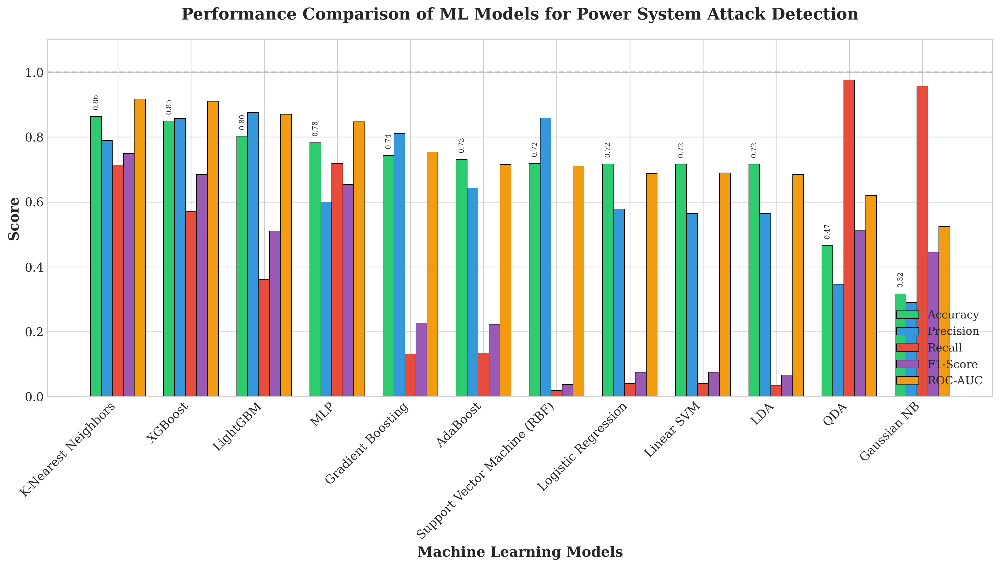

Saved: fig1_model_performance_comparison.png


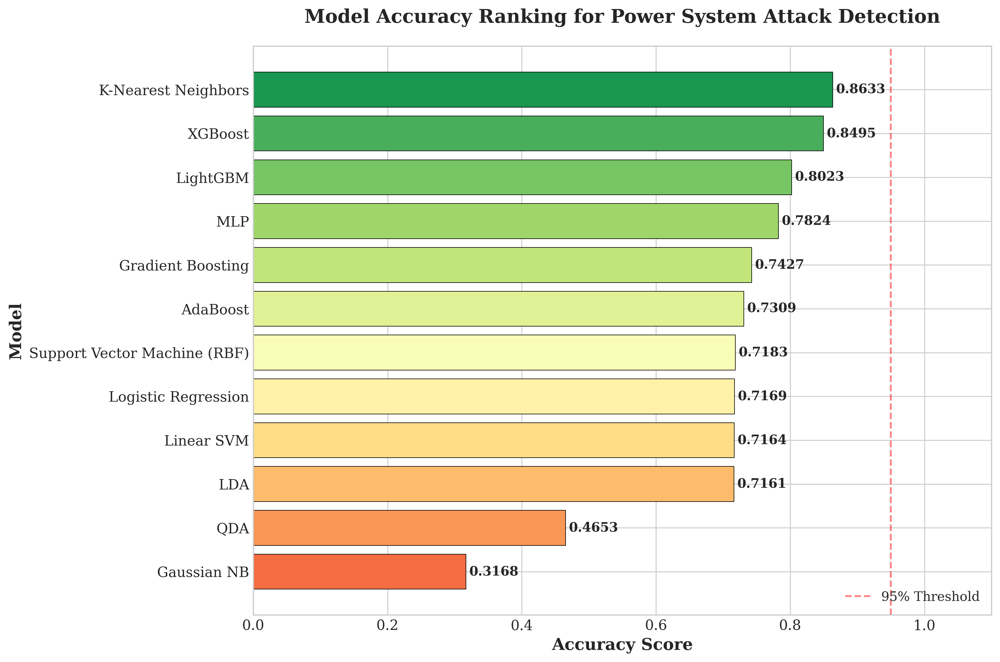

Saved: fig2_accuracy_ranking.png


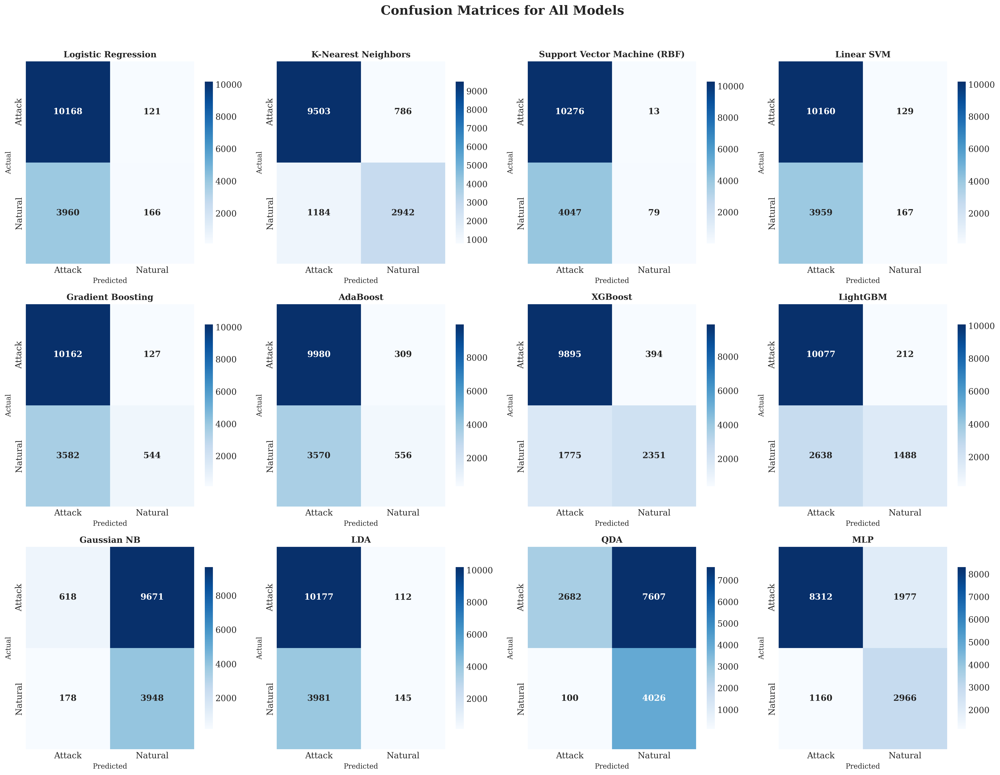

Saved: fig3_confusion_matrices_all.png


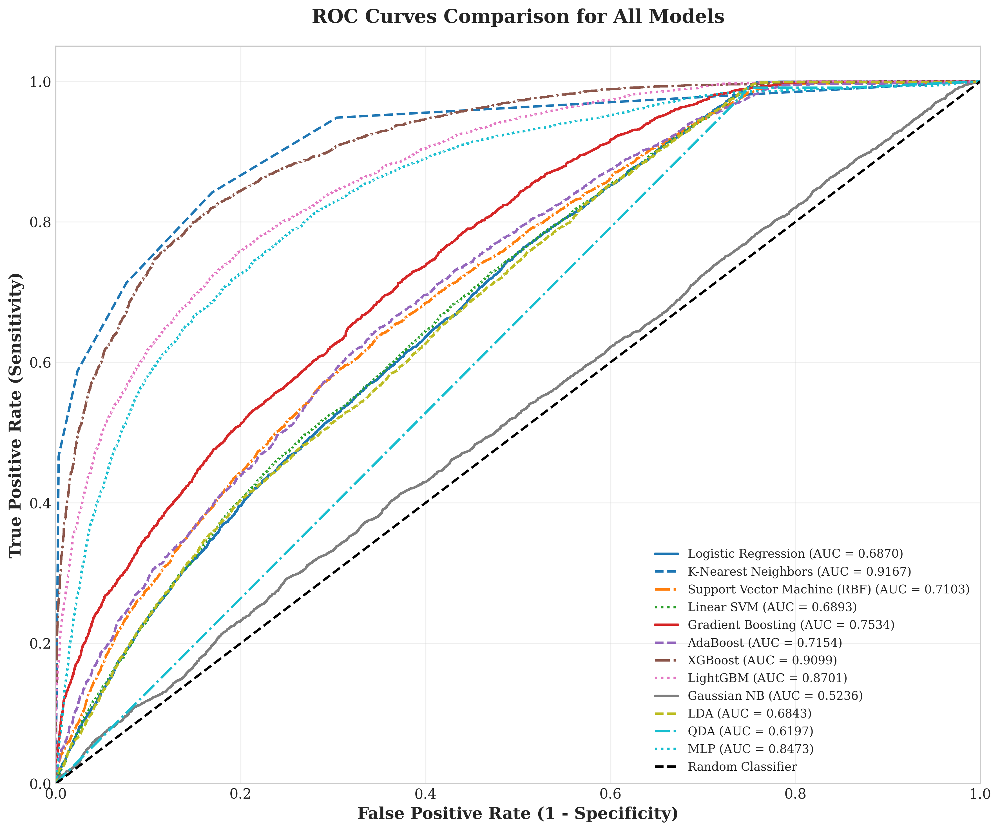

Saved: fig4_roc_curves_all.png


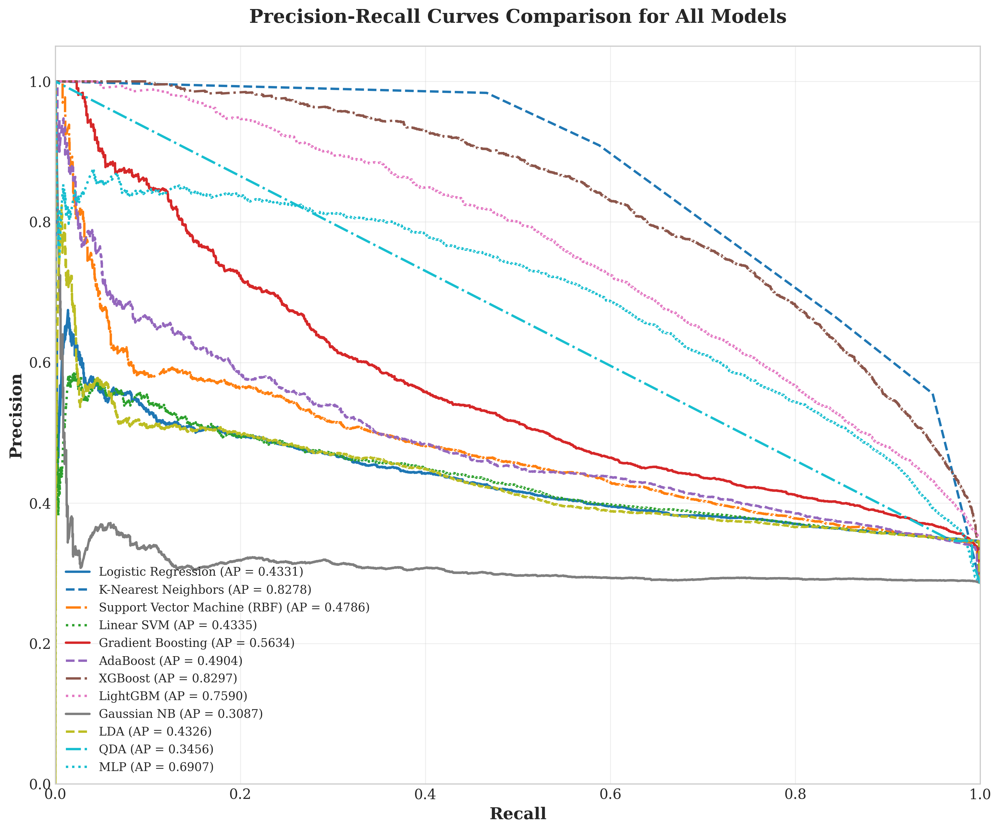

Saved: fig5_precision_recall_curves.png


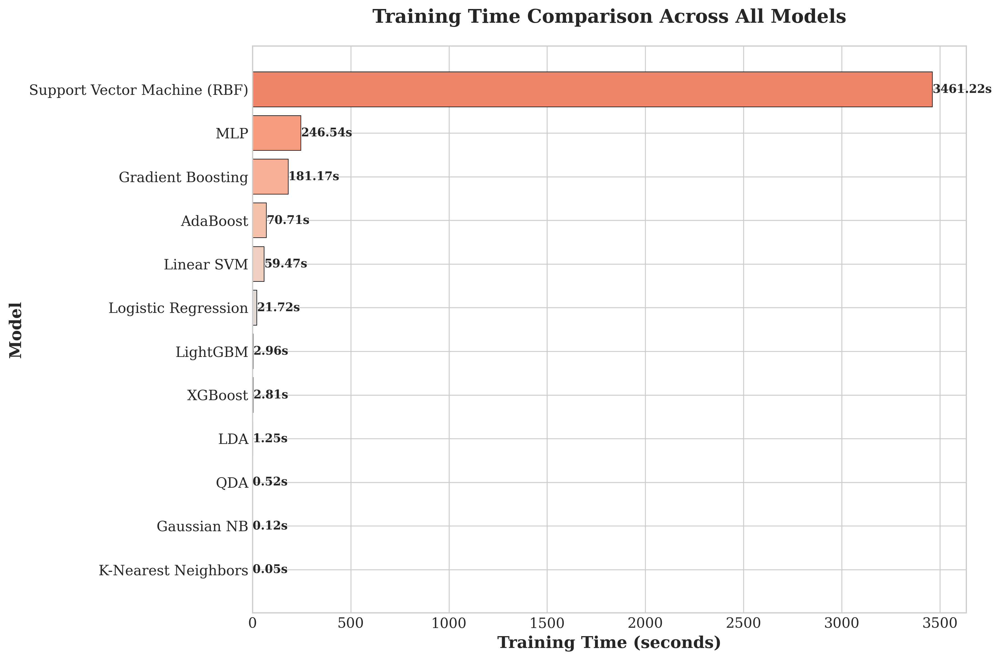

Saved: fig6_training_time.png


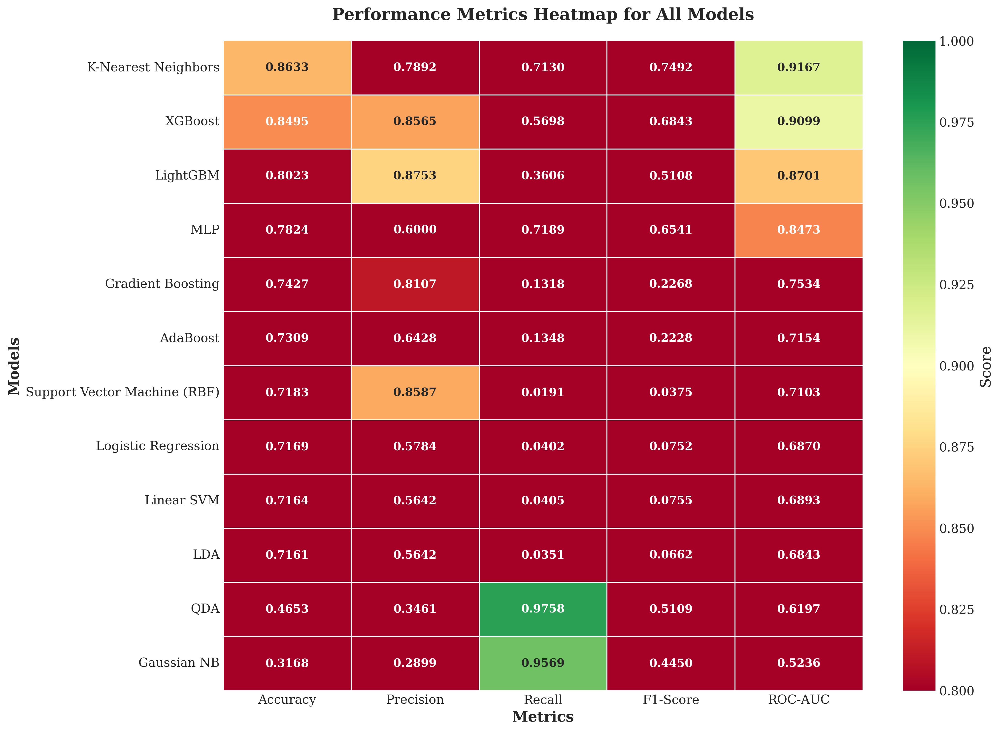

Saved: fig7_metrics_heatmap.png


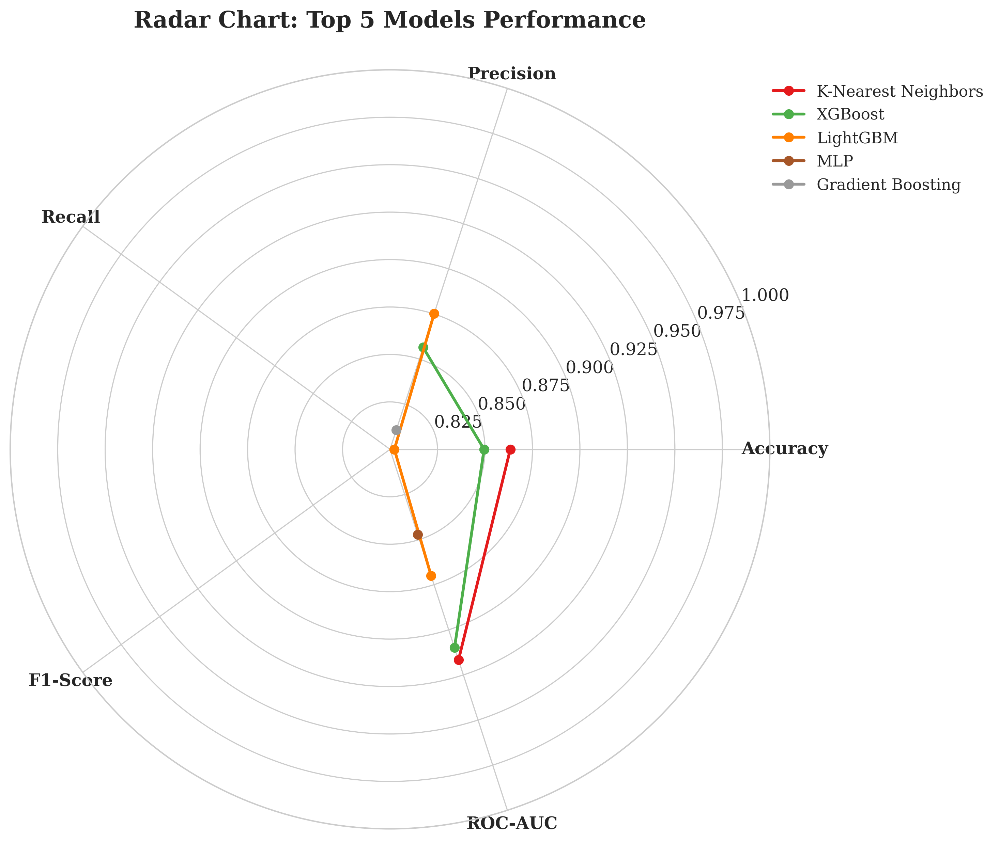

Saved: fig8_radar_chart_top5.png

Performing 5-Fold Cross-Validation for Top Models...
K-Nearest Neighbors: 0.8506 (+/- 0.0068)
XGBoost: 0.8397 (+/- 0.0049)
LightGBM: 0.7956 (+/- 0.0046)


/usr/local/lib/python3.11/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:686: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


MLP: 0.7885 (+/- 0.0208)
Gradient Boosting: 0.7415 (+/- 0.0049)


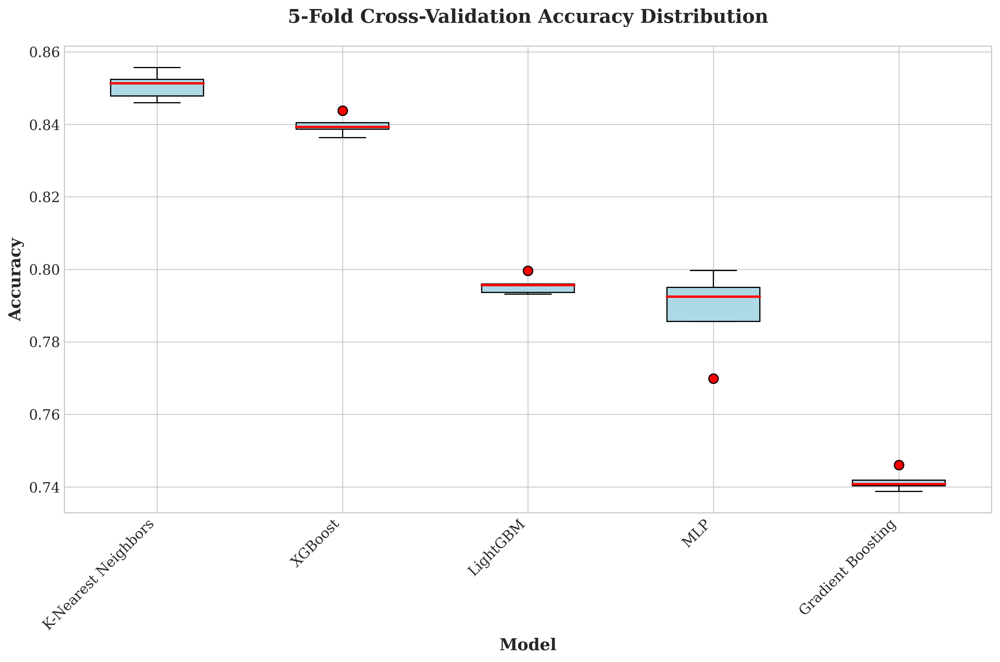

Saved: fig10_cross_validation_boxplot.png

DETAILED CLASSIFICATION REPORTS

──────────────────────────────────────────────────
Model: Logistic Regression
──────────────────────────────────────────────────
              precision    recall  f1-score   support

      Attack       0.72      0.99      0.83     10289
     Natural       0.58      0.04      0.08      4126

    accuracy                           0.72     14415
   macro avg       0.65      0.51      0.45     14415
weighted avg       0.68      0.72      0.62     14415


──────────────────────────────────────────────────
Model: K-Nearest Neighbors
──────────────────────────────────────────────────
              precision    recall  f1-score   support

      Attack       0.89      0.92      0.91     10289
     Natural       0.79      0.71      0.75      4126

    accuracy                           0.86     14415
   macro avg       0.84      0.82      0.83     14415
weighted avg       0.86      0.86      0.86     14415


──────────

In [1]:
# ============================================================================
# COMPREHENSIVE MACHINE LEARNING FRAMEWORK
# FOR POWER SYSTEM ATTACK DETECTION
# Dataset: Mississippi State University and Oak Ridge National Laboratory [web:2][web:4][web:6]
# Binary Classification: Natural Events vs Attack Events [web:6]
# ============================================================================

import pandas as pd
import numpy as np
import os
import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import seaborn as sns
from time import time

# ============================================================================
# 1. DATA LOADING AND PREPROCESSING
# ============================================================================

print("="*70)
print("POWER SYSTEM ATTACK DETECTION - ML FRAMEWORK")
print("="*70)

# Load and combine all data files
data_path = '/kaggle/input/power-system/binaryAllNaturalPlusNormalVsAttacks/'
all_data = []

for i in range(1, 16):
    file_path = f'{data_path}data{i}.csv'
    if os.path.exists(file_path):
        temp_df = pd.read_csv(file_path)
        all_data.append(temp_df)
        print(f"Loaded: data{i}.csv - Shape: {temp_df.shape}")

df = pd.concat(all_data, ignore_index=True)
print(f"\nCombined dataset shape: {df.shape}")

# Remove rows with NaN, Inf, -Inf values
df = df[~df.isin([np.nan, np.inf, -np.inf]).any(axis=1)]
print(f"After cleaning: {df.shape}")

# Display class distribution
print("\nClass Distribution:")
print(df['marker'].value_counts())

# ============================================================================
# 2. FEATURE ENGINEERING AND ENCODING
# ============================================================================

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold

# Separate features and target
X = df.drop('marker', axis=1)
y = df['marker']

# Encode labels
encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y)
print(f"\nClasses: {encoder.classes_}")

# Train-test split with stratification
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

print(f"\nTraining samples: {X_train.shape[0]}")
print(f"Testing samples: {X_test.shape[0]}")
print(f"Number of features: {X_train.shape[1]}")

# Standardize features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# ============================================================================
# 3. IMPORT ALL MACHINE LEARNING MODELS
# ============================================================================

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC, LinearSVC
# from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    GradientBoostingClassifier,
    AdaBoostClassifier,
    BaggingClassifier
)
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.neural_network import MLPClassifier

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier  # imported if needed later

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score, roc_curve,
    precision_recall_curve, average_precision_score
)

# ============================================================================
# 4. DEFINE ALL MODELS (12 BASE CLASSIFIERS)
# ============================================================================

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'K-Nearest Neighbors': KNeighborsClassifier(n_neighbors=5),
    'Support Vector Machine (RBF)': SVC(kernel='rbf', probability=True, random_state=42),
    'Linear SVM': LinearSVC(random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, random_state=42),
    'AdaBoost': AdaBoostClassifier(n_estimators=100, random_state=42),
    'XGBoost': XGBClassifier(n_estimators=100, random_state=42, use_label_encoder=False, eval_metric='logloss'),
    'LightGBM': LGBMClassifier(n_estimators=100, random_state=42, verbose=-1),
    'Gaussian NB': GaussianNB(),
    'LDA': LinearDiscriminantAnalysis(),
    'QDA': QuadraticDiscriminantAnalysis(),
    'MLP': MLPClassifier(hidden_layer_sizes=(128, 64), max_iter=300, random_state=42)
}

# ============================================================================
# 5. TRAIN AND EVALUATE ALL MODELS
# ============================================================================

print("\n" + "="*70)
print("TRAINING AND EVALUATING MACHINE LEARNING MODELS")
print("="*70)

# Store results
results = []
all_predictions = {}
all_probabilities = {}
training_times = {}

for name, model in models.items():
    print(f"\n{'─'*50}")
    print(f"Training: {name}")
    print(f"{'─'*50}")

    # Train model
    start_time = time()
    model.fit(X_train_scaled, y_train)
    train_time = time() - start_time
    training_times[name] = train_time

    # Predictions
    y_pred = model.predict(X_test_scaled)

    # Handle probability / decision scores for ROC, PR
    if hasattr(model, "predict_proba"):
        y_pred_score = model.predict_proba(X_test_scaled)[:, 1]
    elif hasattr(model, "decision_function"):
        y_pred_score = model.decision_function(X_test_scaled)
    else:
        # Fallback (not ideal for ROC, but avoids crash)
        y_pred_score = y_pred

    # Store predictions
    all_predictions[name] = y_pred
    all_probabilities[name] = y_pred_score

    # Calculate metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_pred_score)

    # Store results
    results.append({
        'Model': name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1,
        'ROC-AUC': roc_auc,
        'Training Time (s)': train_time
    })

    print(f"Accuracy : {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall   : {recall:.4f}")
    print(f"F1-Score : {f1:.4f}")
    print(f"ROC-AUC  : {roc_auc:.4f}")
    print(f"Time     : {train_time:.2f}s")

# Create results DataFrame
results_df = pd.DataFrame(results)
results_df = results_df.sort_values('Accuracy', ascending=False).reset_index(drop=True)

print("\n" + "="*70)
print("MODEL PERFORMANCE COMPARISON")
print("="*70)
print(results_df.to_string(index=False))

# Save results to CSV
results_df.to_csv('model_comparison_results.csv', index=False)
print("\nResults saved to: model_comparison_results.csv")

# ============================================================================
# 7. PUBLICATION-READY VISUALIZATIONS
# ============================================================================

print("\n" + "="*70)
print("GENERATING PUBLICATION-READY VISUALIZATIONS")
print("="*70)

# Set publication style
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.size'] = 12
plt.rcParams['axes.labelsize'] = 14
plt.rcParams['axes.titlesize'] = 16
plt.rcParams['xtick.labelsize'] = 12
plt.rcParams['ytick.labelsize'] = 12
plt.rcParams['legend.fontsize'] = 11
plt.rcParams['figure.dpi'] = 300

# Color palette for models
colors = plt.cm.tab20(np.linspace(0, 1, len(results_df)))
model_colors = dict(zip(results_df['Model'].tolist(), colors))

# ─────────────────────────────────────────────────────────────────────────────
# FIGURE 1: Model Performance Comparison Bar Chart
# ─────────────────────────────────────────────────────────────────────────────

fig, ax = plt.subplots(figsize=(14, 8))

x = np.arange(len(results_df))
width = 0.15

metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']
metric_colors = ['#2ecc71', '#3498db', '#e74c3c', '#9b59b6', '#f39c12']

for i, metric in enumerate(metrics):
    bars = ax.bar(x + i*width, results_df[metric], width,
                  label=metric, color=metric_colors[i],
                  edgecolor='black', linewidth=0.5)

ax.set_xlabel('Machine Learning Models', fontweight='bold')
ax.set_ylabel('Score', fontweight='bold')
ax.set_title('Performance Comparison of ML Models for Power System Attack Detection',
             fontweight='bold', pad=20)
ax.set_xticks(x + width * 2)
ax.set_xticklabels(results_df['Model'], rotation=45, ha='right')
ax.legend(loc='lower right', framealpha=0.9)
ax.set_ylim(0, 1.1)
ax.axhline(y=1.0, color='gray', linestyle='--', alpha=0.3)

# Add value labels on bars (for Accuracy only, to avoid clutter)
for i, metric in enumerate(metrics):
    if metric != 'Accuracy':
        continue
    for j, v in enumerate(results_df[metric]):
        ax.text(j + i*width, v + 0.02, f'{v:.2f}',
                ha='center', va='bottom', fontsize=7, rotation=90)

plt.tight_layout()
plt.savefig('fig1_model_performance_comparison.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
print("Saved: fig1_model_performance_comparison.png")

# ─────────────────────────────────────────────────────────────────────────────
# FIGURE 2: Accuracy Ranking Horizontal Bar Chart
# ─────────────────────────────────────────────────────────────────────────────

fig, ax = plt.subplots(figsize=(12, 8))

sorted_df = results_df.sort_values('Accuracy', ascending=True)
colors_sorted = plt.cm.RdYlGn(np.linspace(0.2, 0.9, len(sorted_df)))

bars = ax.barh(sorted_df['Model'], sorted_df['Accuracy'],
               color=colors_sorted, edgecolor='black', linewidth=0.5)

# Add value labels
for bar, acc in zip(bars, sorted_df['Accuracy']):
    ax.text(bar.get_width() + 0.005,
            bar.get_y() + bar.get_height()/2,
            f'{acc:.4f}', va='center', fontsize=11, fontweight='bold')

ax.set_xlabel('Accuracy Score', fontweight='bold')
ax.set_ylabel('Model', fontweight='bold')
ax.set_title('Model Accuracy Ranking for Power System Attack Detection',
             fontweight='bold', pad=20)
ax.set_xlim(0, 1.1)
ax.axvline(x=0.95, color='red', linestyle='--', alpha=0.5, label='95% Threshold')
ax.legend(loc='lower right')

plt.tight_layout()
plt.savefig('fig2_accuracy_ranking.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
print("Saved: fig2_accuracy_ranking.png")

# ─────────────────────────────────────────────────────────────────────────────
# FIGURE 3: Confusion Matrices for All Models (Grid)
# ─────────────────────────────────────────────────────────────────────────────

n_models = len(all_predictions)
n_rows = int(np.ceil(n_models / 4))
fig, axes = plt.subplots(n_rows, 4, figsize=(20, 5 * n_rows))
axes = axes.flatten()

all_models = list(all_predictions.keys())

for idx, model_name in enumerate(all_models):
    cm = confusion_matrix(y_test, all_predictions[model_name])

    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx],
                xticklabels=encoder.classes_, yticklabels=encoder.classes_,
                annot_kws={'size': 12, 'fontweight': 'bold'},
                cbar_kws={'shrink': 0.8})

    axes[idx].set_title(f'{model_name}', fontsize=12, fontweight='bold')
    axes[idx].set_xlabel('Predicted', fontsize=10)
    axes[idx].set_ylabel('Actual', fontsize=10)

# Hide any empty subplots
for j in range(idx + 1, len(axes)):
    axes[j].axis('off')

plt.suptitle('Confusion Matrices for All Models', fontsize=18, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('fig3_confusion_matrices_all.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
print("Saved: fig3_confusion_matrices_all.png")

# ─────────────────────────────────────────────────────────────────────────────
# FIGURE 4: ROC Curves for All Models
# ─────────────────────────────────────────────────────────────────────────────

fig, ax = plt.subplots(figsize=(12, 10))

line_styles = ['-', '--', '-.', ':'] * 10
colors_roc = plt.cm.tab10(np.linspace(0, 1, len(all_models)))

for idx, model_name in enumerate(all_models):
    fpr, tpr, _ = roc_curve(y_test, all_probabilities[model_name])
    auc = roc_auc_score(y_test, all_probabilities[model_name])
    ax.plot(fpr, tpr,
            label=f'{model_name} (AUC = {auc:.4f})',
            linewidth=2,
            color=colors_roc[idx % len(colors_roc)],
            linestyle=line_styles[idx % len(line_styles)])

ax.plot([0, 1], [0, 1], 'k--', linewidth=2, label='Random Classifier')
ax.set_xlabel('False Positive Rate (1 - Specificity)', fontweight='bold')
ax.set_ylabel('True Positive Rate (Sensitivity)', fontweight='bold')
ax.set_title('ROC Curves Comparison for All Models',
             fontweight='bold', pad=20)
ax.legend(loc='lower right', fontsize=10)
ax.set_xlim([0, 1])
ax.set_ylim([0, 1.05])
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('fig4_roc_curves_all.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
print("Saved: fig4_roc_curves_all.png")

# ─────────────────────────────────────────────────────────────────────────────
# FIGURE 5: Precision-Recall Curves for All Models
# ─────────────────────────────────────────────────────────────────────────────

fig, ax = plt.subplots(figsize=(12, 10))

for idx, model_name in enumerate(all_models):
    precision_vals, recall_vals, _ = precision_recall_curve(y_test, all_probabilities[model_name])
    ap = average_precision_score(y_test, all_probabilities[model_name])
    ax.plot(recall_vals, precision_vals,
            label=f'{model_name} (AP = {ap:.4f})',
            linewidth=2,
            color=colors_roc[idx % len(colors_roc)],
            linestyle=line_styles[idx % len(line_styles)])

ax.set_xlabel('Recall', fontweight='bold')
ax.set_ylabel('Precision', fontweight='bold')
ax.set_title('Precision-Recall Curves Comparison for All Models',
             fontweight='bold', pad=20)
ax.legend(loc='lower left', fontsize=10)
ax.set_xlim([0, 1])
ax.set_ylim([0, 1.05])
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('fig5_precision_recall_curves.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
print("Saved: fig5_precision_recall_curves.png")

# ─────────────────────────────────────────────────────────────────────────────
# FIGURE 6: Training Time Comparison
# ─────────────────────────────────────────────────────────────────────────────

fig, ax = plt.subplots(figsize=(12, 8))

time_df = pd.DataFrame({
    'Model': list(training_times.keys()),
    'Time': list(training_times.values())
}).sort_values('Time', ascending=True)

colors_time = plt.cm.coolwarm(np.linspace(0.2, 0.8, len(time_df)))
bars = ax.barh(time_df['Model'], time_df['Time'],
               color=colors_time, edgecolor='black', linewidth=0.5)

for bar, t in zip(bars, time_df['Time']):
    ax.text(bar.get_width() + 0.1,
            bar.get_y() + bar.get_height()/2,
            f'{t:.2f}s', va='center', fontsize=10, fontweight='bold')

ax.set_xlabel('Training Time (seconds)', fontweight='bold')
ax.set_ylabel('Model', fontweight='bold')
ax.set_title('Training Time Comparison Across All Models',
             fontweight='bold', pad=20)

plt.tight_layout()
plt.savefig('fig6_training_time.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
print("Saved: fig6_training_time.png")

# ─────────────────────────────────────────────────────────────────────────────
# FIGURE 7: Heatmap of All Metrics
# ─────────────────────────────────────────────────────────────────────────────

fig, ax = plt.subplots(figsize=(14, 10))

metrics_df = results_df.set_index('Model')[['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']]

sns.heatmap(metrics_df, annot=True, fmt='.4f', cmap='RdYlGn', ax=ax,
            linewidths=0.5, linecolor='white',
            annot_kws={'size': 11, 'fontweight': 'bold'},
            vmin=0.8, vmax=1.0,
            cbar_kws={'label': 'Score'})

ax.set_title('Performance Metrics Heatmap for All Models',
             fontweight='bold', pad=20)
ax.set_xlabel('Metrics', fontweight='bold')
ax.set_ylabel('Models', fontweight='bold')

plt.tight_layout()
plt.savefig('fig7_metrics_heatmap.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
print("Saved: fig7_metrics_heatmap.png")

# ─────────────────────────────────────────────────────────────────────────────
# FIGURE 8: Radar Chart for Top 5 Models
# ─────────────────────────────────────────────────────────────────────────────

from math import pi

fig, ax = plt.subplots(figsize=(10, 10), subplot_kw=dict(polar=True))

categories = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']
N = len(categories)

top5_df = results_df.head(5)
angles = [n / float(N) * 2 * pi for n in range(N)]
angles += angles[:1]

colors_radar = plt.cm.Set1(np.linspace(0, 1, len(top5_df)))

for idx, row in top5_df.iterrows():
    values = row[categories].values.flatten().tolist()
    values += values[:1]
    ax.plot(angles, values, 'o-', linewidth=2, label=row['Model'],
            color=colors_radar[idx % len(colors_radar)])
    ax.fill(angles, values, alpha=0.1, color=colors_radar[idx % len(colors_radar)])

ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories, fontsize=12, fontweight='bold')
ax.set_ylim(0.8, 1.0)
ax.set_title('Radar Chart: Top 5 Models Performance',
             fontweight='bold', pad=30, fontsize=16)
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.0))

plt.tight_layout()
plt.savefig('fig8_radar_chart_top5.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
print("Saved: fig8_radar_chart_top5.png")

# ─────────────────────────────────────────────────────────────────────────────
# FIGURE 10: Box Plot of Cross-Validation Scores (Top 5 Models)
# ─────────────────────────────────────────────────────────────────────────────

print("\nPerforming 5-Fold Cross-Validation for Top Models...")

cv_results = {}

# You can choose any top models; here, select top 5 by accuracy
top_model_names = results_df['Model'].head(5).tolist()
top_models = {name: models[name] for name in top_model_names}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for name, model in top_models.items():
    scores = cross_val_score(model, X_train_scaled, y_train,
                             cv=cv, scoring='accuracy', n_jobs=-1)
    cv_results[name] = scores
    print(f"{name}: {scores.mean():.4f} (+/- {scores.std()*2:.4f})")

fig, ax = plt.subplots(figsize=(12, 8))

cv_df = pd.DataFrame(cv_results)
cv_df.boxplot(ax=ax, grid=True, patch_artist=True,
              boxprops=dict(facecolor='lightblue', color='black'),
              medianprops=dict(color='red', linewidth=2),
              whiskerprops=dict(color='black'),
              capprops=dict(color='black'),
              flierprops=dict(marker='o', markerfacecolor='red', markersize=8))

ax.set_xlabel('Model', fontweight='bold')
ax.set_ylabel('Accuracy', fontweight='bold')
ax.set_title('5-Fold Cross-Validation Accuracy Distribution',
             fontweight='bold', pad=20)
ax.set_xticklabels(cv_df.columns, rotation=45, ha='right')

plt.tight_layout()
plt.savefig('fig10_cross_validation_boxplot.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
print("Saved: fig10_cross_validation_boxplot.png")

# ============================================================================
# 8. GENERATE DETAILED CLASSIFICATION REPORTS
# ============================================================================

print("\n" + "="*70)
print("DETAILED CLASSIFICATION REPORTS")
print("="*70)

for model_name in all_predictions.keys():
    print(f"\n{'─'*50}")
    print(f"Model: {model_name}")
    print(f"{'─'*50}")
    print(classification_report(y_test, all_predictions[model_name],
                                target_names=encoder.classes_))

# ============================================================================
# 9. SAVE FINAL RESULTS
# ============================================================================

# Save final results
results_df.to_csv('final_model_comparison.csv', index=False)
print("\nFinal results saved: final_model_comparison.csv")

# Save all predictions
predictions_df = pd.DataFrame(all_predictions)
predictions_df['y_true'] = y_test
predictions_df.to_csv('all_model_predictions.csv', index=False)
print("All predictions saved: all_model_predictions.csv")

print("\n" + "="*70)
print("ALL VISUALIZATIONS AND RESULTS SAVED SUCCESSFULLY!")
print("="*70)
print("\nGenerated Files:")
print("  1. fig1_model_performance_comparison.png")
print("  2. fig2_accuracy_ranking.png")
print("  3. fig3_confusion_matrices_all.png")
print("  4. fig4_roc_curves_all.png")
print("  5. fig5_precision_recall_curves.png")
print("  6. fig6_training_time.png")
print("  7. fig7_metrics_heatmap.png")
print("  8. fig8_radar_chart_top5.png")
print("  9. fig10_cross_validation_boxplot.png")
print("\nCSV Files:")
print("  - final_model_comparison.csv")
print("  - all_model_predictions.csv")

HYBRID KNN + CNN-BiLSTM MODEL (10 EPOCHS)
USING CLASS WEIGHTS INSTEAD OF SMOTE FOR IMBALANCE HANDLING
✓ scikit-learn version: 1.2.2
✓ TensorFlow version: 2.18.0
✓ Loaded: data1.csv - Shape: (4966, 129)
✓ Loaded: data2.csv - Shape: (5069, 129)
✓ Loaded: data3.csv - Shape: (5415, 129)
✓ Loaded: data4.csv - Shape: (5202, 129)
✓ Loaded: data5.csv - Shape: (5161, 129)
✓ Loaded: data6.csv - Shape: (4967, 129)
✓ Loaded: data7.csv - Shape: (5236, 129)
✓ Loaded: data8.csv - Shape: (5315, 129)
✓ Loaded: data9.csv - Shape: (5340, 129)
✓ Loaded: data10.csv - Shape: (5569, 129)
✓ Loaded: data11.csv - Shape: (5251, 129)
✓ Loaded: data12.csv - Shape: (5224, 129)
✓ Loaded: data13.csv - Shape: (5271, 129)
✓ Loaded: data14.csv - Shape: (5115, 129)
✓ Loaded: data15.csv - Shape: (5276, 129)

📦 Combined dataset shape: (78377, 129)
✓ After cleaning: (72073, 129)

📊 Class Distribution:
marker
Attack     51445
Natural    20628
Name: count, dtype: int64

🏷️ Classes: ['Attack' 'Natural']

Training samples: 5765

Model: "Hybrid_KNN_CNN_BiLSTM"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ sequence_input      │ (None, 8, 16)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_4 (Conv1D)   │ (None, 8, 128)    │      6,272 │ sequence_input[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 8, 128)    │        512 │ conv1d_4[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_5 (Conv1D)   │ (None, 8, 128)    │     49,280 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 8, 128)    │        512 │ conv1d_5[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_2     │ (None, 4, 128)    │          0 │ batch_normalizat… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout1d_2 │ (None, 4, 128)    │          0 │ max_pooling1d_2[… │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_6 (Conv1D)   │ (None, 4, 256)    │     98,560 │ spatial_dropout1… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 4, 256)    │      1,024 │ conv1d_6[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_7 (Conv1D)   │ (None, 4, 256)    │    196,864 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 4, 256)    │      1,024 │ conv1d_7[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_3     │ (None, 2, 256)    │          0 │ batch_normalizat… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout1d_3 │ (None, 2, 256)    │          0 │ max_pooling1d_3[… │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ knn_prob_input      │ (None, 2)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_2     │ (None, 2, 256)    │    394,240 │ spatial_dropout1… │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 32)        │         96 │ knn_prob_input[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_3     │ (None, 2, 128)    │    164,352 │ bidirectional_2[… │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32)        │        128 │ dense_3[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 942,305 (3.59 MB)

 Trainable params: 940,449 (3.59 MB)

 Non-trainable params: 1,856 (7.25 KB)


PHASE 3: TRAINING HYBRID MODEL (10 EPOCHS WITH CLASS WEIGHTS)
Epoch 1/5
192/192 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step - accuracy: 0.9327 - auc: 0.9858 - loss: 0.1959 - precision: 0.8498 - recall: 0.9821
Epoch 1: val_accuracy improved from -inf to 1.00000, saving model to best_hybrid_knn_cnn_bilstm.keras
192/192 ━━━━━━━━━━━━━━━━━━━━ 34s 107ms/step - accuracy: 0.9329 - auc: 0.9859 - loss: 0.1955 - precision: 0.8503 - recall: 0.9821 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.1943 - val_precision: 1.0000 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 2/5
192/192 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step - accuracy: 1.0000 - auc: 1.0000 - loss: 0.0681 - precision: 1.0000 - recall: 1.0000
Epoch 2: val_accuracy did not improve from 1.00000
192/192 ━━━━━━━━━━━━━━━━━━━━ 19s 97ms/step - accuracy: 1.0000 - auc: 1.0000 - loss: 0.0681 - precision: 1.0000 - recall: 1.0000 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.0626 - val_precision: 1.0000 - val_recall: 1.0000 - learning_rate: 0.

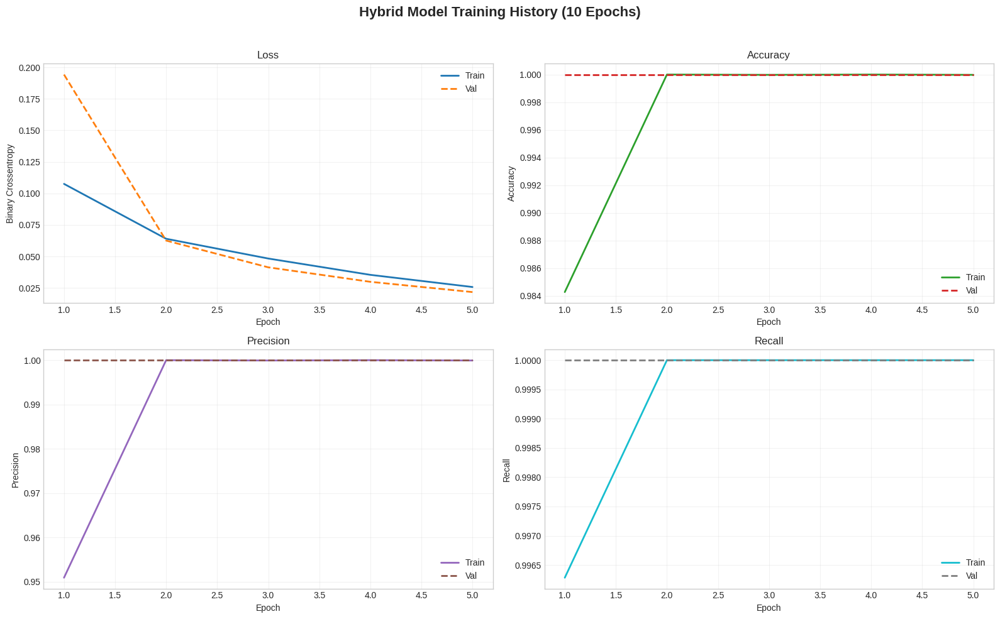

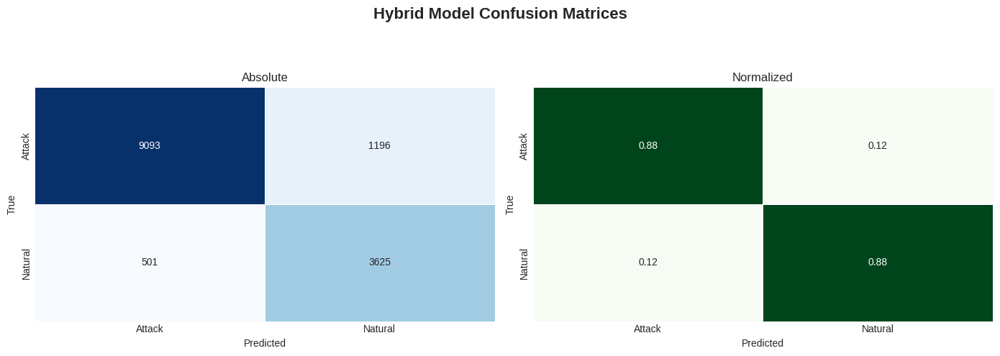

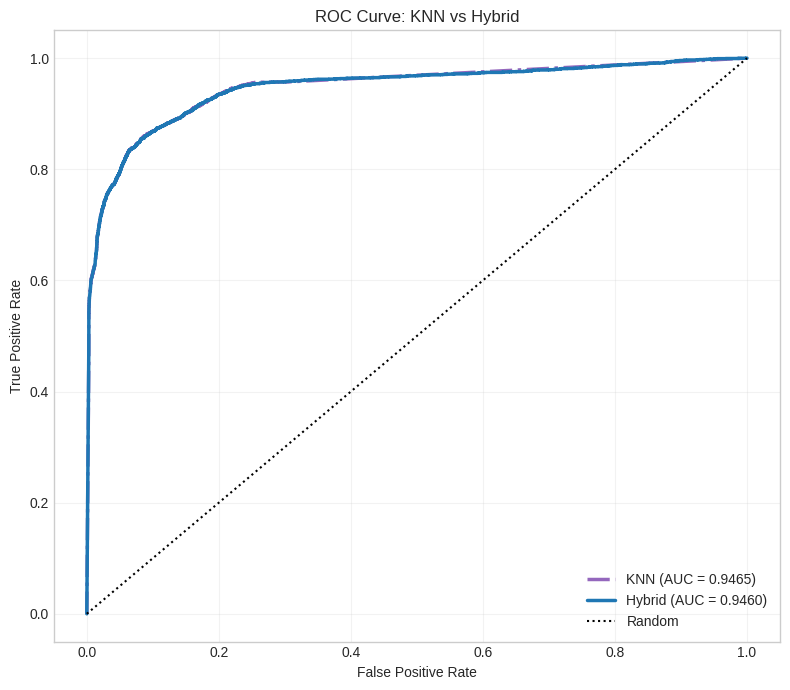

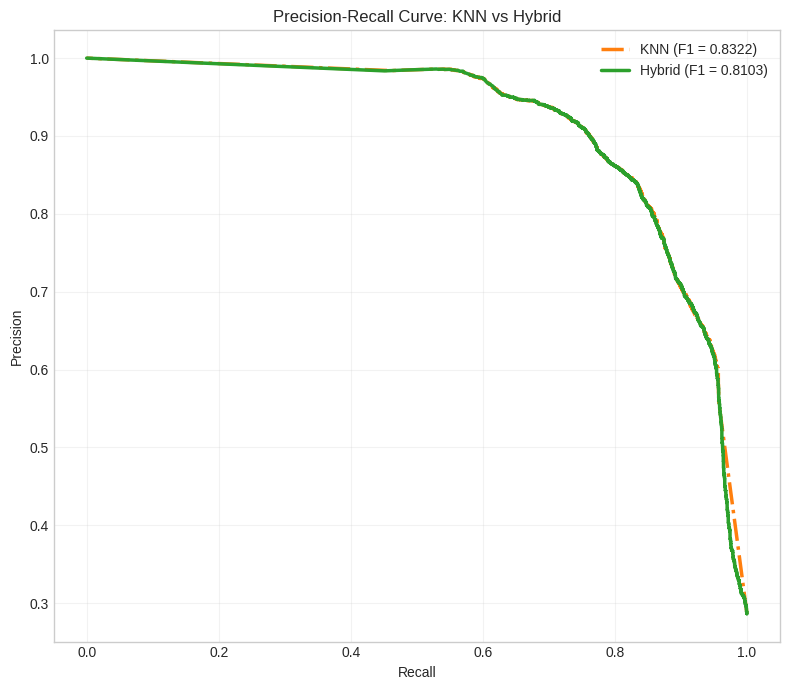

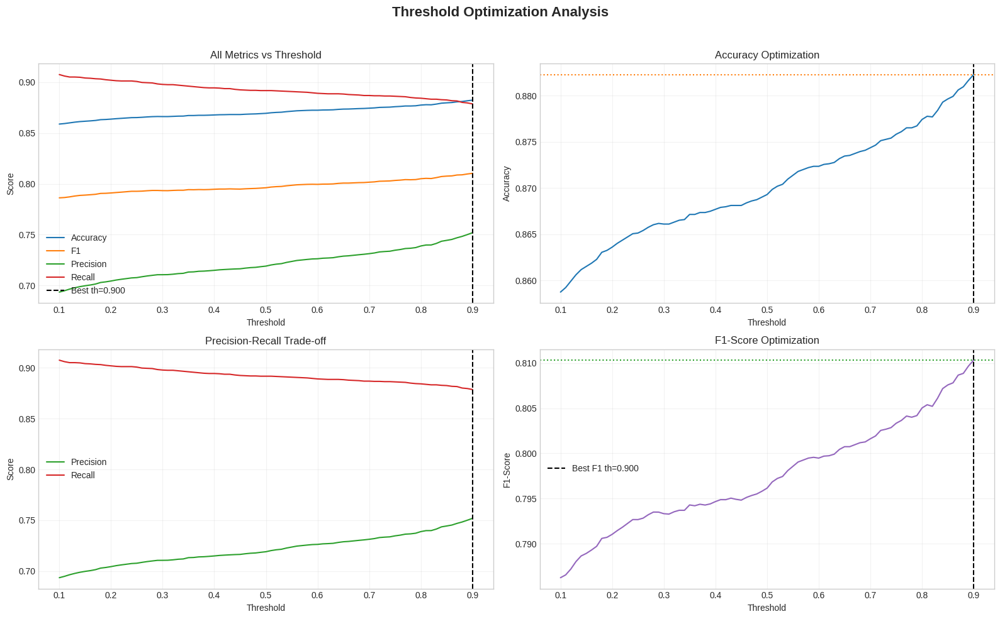


Calculating permutation feature importance for KNN (this may take some time)...


In [ ]:
# ====================================================================
# HYBRID KNN + CNN-BiLSTM FOR POWER SYSTEM ATTACK DETECTION
# NO SMOTE - USES CLASS WEIGHTS
# 10 EPOCHS - COMPLETE WORKING CODE
# ====================================================================

import os
import numpy as np
import pandas as pd
import sklearn

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    roc_curve, precision_recall_curve
)
from sklearn.utils.class_weight import compute_class_weight
from sklearn.inspection import permutation_importance  # for feature importance

import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Conv1D, MaxPooling1D, LSTM, Dense, Dropout,
    BatchNormalization, Bidirectional, SpatialDropout1D,
    GlobalAveragePooling1D, Input, Concatenate
)
from tensorflow.keras.callbacks import ReduceLROnPlateau, ModelCheckpoint, EarlyStopping
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2

plt.style.use("seaborn-v0_8-whitegrid")
sns.set_palette("deep")

print("=" * 80)
print("HYBRID KNN + CNN-BiLSTM MODEL (10 EPOCHS)")
print("USING CLASS WEIGHTS INSTEAD OF SMOTE FOR IMBALANCE HANDLING")
print("=" * 80)
print(f"✓ scikit-learn version: {sklearn.__version__}")
print(f"✓ TensorFlow version: {tf.__version__}")

# ====================================================================
# 1. DATA LOADING
# ====================================================================

data_path = '/kaggle/input/power-system/binaryAllNaturalPlusNormalVsAttacks/'
all_data = []

for i in range(1, 16):
    file_path = f'{data_path}data{i}.csv'
    if os.path.exists(file_path):
        temp_df = pd.read_csv(file_path)
        all_data.append(temp_df)
        print(f"✓ Loaded: data{i}.csv - Shape: {temp_df.shape}")

df = pd.concat(all_data, ignore_index=True)
print(f"\n📦 Combined dataset shape: {df.shape}")

# Clean data
df = df[~df.isin([np.nan, np.inf, -np.inf]).any(axis=1)]
print(f"✓ After cleaning: {df.shape}")

print("\n📊 Class Distribution:")
print(df['marker'].value_counts())

# ====================================================================
# 2. PREPROCESSING
# ====================================================================

X = df.drop('marker', axis=1)
y = df['marker']

encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y)
print(f"\n🏷️ Classes: {encoder.classes_}")

X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded,
    test_size=0.2,
    random_state=21,
    stratify=y_encoded
)

print(f"\nTraining samples: {X_train.shape[0]}")
print(f"Testing samples: {X_test.shape[0]}")
print(f"Features: {X_train.shape[1]}")

# ====================================================================
# 3. COMPUTE CLASS WEIGHTS
# ====================================================================

print("\n⚖️ Computing class weights for imbalance handling...")

class_weights_array = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)
class_weights = {i: w for i, w in enumerate(class_weights_array)}
print(f"Class weights: {class_weights}")

X_train_res = X_train
y_train_res = y_train
print(f"Train class distribution: {pd.Series(y_train_res).value_counts().to_dict()}")

# ====================================================================
# 4. SCALING
# ====================================================================

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_res)
X_test_scaled = scaler.transform(X_test)

# ====================================================================
# 5. KNN TRAINING
# ====================================================================

print("\n" + "=" * 80)
print("PHASE 1: TRAINING K-NEAREST NEIGHBORS CLASSIFIER")
print("=" * 80)

knn_model = KNeighborsClassifier(
    n_neighbors=5,
    weights='distance',
    algorithm='auto',
    leaf_size=30,
    metric='minkowski',  # default p=2 = euclidean
    p=2,
    n_jobs=-1
)

knn_model.fit(X_train_scaled, y_train_res)
print("✓ KNN training complete")

# KNN predictions
y_pred_knn_train_prob = knn_model.predict_proba(X_train_scaled)
y_pred_knn_test_prob = knn_model.predict_proba(X_test_scaled)
y_pred_knn_test = knn_model.predict(X_test_scaled)

# Evaluate KNN
knn_accuracy = accuracy_score(y_test, y_pred_knn_test)
knn_precision = precision_score(y_test, y_pred_knn_test)
knn_recall = recall_score(y_test, y_pred_knn_test)
knn_f1 = f1_score(y_test, y_pred_knn_test)
knn_roc_auc = roc_auc_score(y_test, y_pred_knn_test_prob[:, 1])

print(f"\n📊 KNN STANDALONE METRICS:")
print(f"├─ Accuracy:  {knn_accuracy:.4f} ({knn_accuracy*100:.2f}%)")
print(f"├─ Precision: {knn_precision:.4f}")
print(f"├─ Recall:    {knn_recall:.4f}")
print(f"├─ F1-Score:  {knn_f1:.4f}")
print(f"└─ ROC-AUC:   {knn_roc_auc:.4f}")

# ====================================================================
# 6. PREPARE DATA FOR CNN-BiLSTM
# ====================================================================

print("\n" + "=" * 80)
print("PHASE 2: PREPARING HYBRID CNN-BiLSTM WITH KNN FEATURES")
print("=" * 80)

def reshape_to_sequences(X_arr, n_timesteps=8):
    n_samples, n_features = X_arr.shape
    features_per_step = n_features // n_timesteps
    n_features_used = features_per_step * n_timesteps
    X_trimmed = X_arr[:, :n_features_used]
    return X_trimmed.reshape((n_samples, n_timesteps, features_per_step))

n_timesteps = 8
X_train_seq = reshape_to_sequences(X_train_scaled, n_timesteps=n_timesteps)
X_test_seq = reshape_to_sequences(X_test_scaled, n_timesteps=n_timesteps)

print(f"✓ Train sequence shape: {X_train_seq.shape}")
print(f"✓ Test sequence shape: {X_test_seq.shape}")
print(f"✓ KNN probability features: {y_pred_knn_train_prob.shape[1]} classes")

# ====================================================================
# 7. BUILD HYBRID MODEL: CNN-BiLSTM + KNN PROBABILITIES
# ====================================================================

def build_hybrid_knn_cnn_bilstm(seq_shape, knn_prob_dim):
    seq_input = Input(shape=seq_shape, name='sequence_input')

    # CNN Block 1
    x = Conv1D(128, 3, activation='relu', padding='same',
               kernel_regularizer=l2(1e-4))(seq_input)
    x = BatchNormalization()(x)
    x = Conv1D(128, 3, activation='relu', padding='same',
               kernel_regularizer=l2(1e-4))(x)
    x = BatchNormalization()(x)
    x = MaxPooling1D(pool_size=2)(x)
    x = SpatialDropout1D(0.25)(x)

    # CNN Block 2
    x = Conv1D(256, 3, activation='relu', padding='same',
               kernel_regularizer=l2(1e-4))(x)
    x = BatchNormalization()(x)
    x = Conv1D(256, 3, activation='relu', padding='same',
               kernel_regularizer=l2(1e-4))(x)
    x = BatchNormalization()(x)
    x = MaxPooling1D(pool_size=2)(x)
    x = SpatialDropout1D(0.25)(x)

    # BiLSTM blocks
    x = Bidirectional(LSTM(128, return_sequences=True, dropout=0.3))(x)
    x = Bidirectional(LSTM(64, return_sequences=True, dropout=0.3))(x)

    x = GlobalAveragePooling1D()(x)

    # KNN probability input
    knn_input = Input(shape=(knn_prob_dim,), name='knn_prob_input')
    k = Dense(32, activation='relu', kernel_regularizer=l2(1e-4))(knn_input)
    k = BatchNormalization()(k)
    k = Dropout(0.3)(k)

    # Concatenate
    combined = Concatenate()([x, k])

    combined = Dense(128, activation='relu', kernel_regularizer=l2(1e-4))(combined)
    combined = BatchNormalization()(combined)
    combined = Dropout(0.5)(combined)

    combined = Dense(64, activation='relu', kernel_regularizer=l2(1e-4))(combined)
    combined = Dropout(0.4)(combined)

    output = Dense(1, activation='sigmoid', name='output')(combined)

    model = Model(inputs=[seq_input, knn_input], outputs=output,
                  name='Hybrid_KNN_CNN_BiLSTM')
    return model

model = build_hybrid_knn_cnn_bilstm(
    seq_shape=(X_train_seq.shape[1], X_train_seq.shape[2]),
    knn_prob_dim=y_pred_knn_train_prob.shape[1]
)

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall'),
        tf.keras.metrics.AUC(name='auc')
    ]
)

print("\n" + "=" * 80)
print("MODEL ARCHITECTURE:")
print("=" * 80)
model.summary()

# ====================================================================
# 8. CALLBACKS
# ====================================================================

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=3,
    min_lr=1e-7,
    verbose=1
)

model_checkpoint = ModelCheckpoint(
    filepath='best_hybrid_knn_cnn_bilstm.keras',
    monitor='val_accuracy',
    save_best_only=True,
    verbose=1,
    mode='max'
)

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

callbacks = [reduce_lr, model_checkpoint, early_stopping]

# ====================================================================
# 9. TRAINING
# ====================================================================

print("\n" + "=" * 80)
print("PHASE 3: TRAINING HYBRID MODEL (10 EPOCHS WITH CLASS WEIGHTS)")
print("=" * 80)

history = model.fit(
    [X_train_seq, y_pred_knn_train_prob], y_train_res,
    epochs=5,
    batch_size=256,
    validation_split=0.15,
    class_weight=class_weights,
    callbacks=callbacks,
    verbose=1,
    shuffle=True
)

# ====================================================================
# 10. EVALUATION WITH THRESHOLD TUNING
# ====================================================================

print("\n" + "=" * 80)
print("PHASE 4: EVALUATION AND THRESHOLD OPTIMIZATION")
print("=" * 80)

y_pred_hybrid_prob = model.predict([X_test_seq, y_pred_knn_test_prob], verbose=0).ravel()

thresholds = np.linspace(0.1, 0.9, 81)
best_acc, best_th = 0.0, 0.5
acc_list, f1_list, prec_list, rec_list = [], [], [], []

for th in thresholds:
    y_hat = (y_pred_hybrid_prob >= th).astype(int)
    acc = accuracy_score(y_test, y_hat)
    f1 = f1_score(y_test, y_hat)
    prec = precision_score(y_test, y_hat)
    rec = recall_score(y_test, y_hat)

    acc_list.append(acc)
    f1_list.append(f1)
    prec_list.append(prec)
    rec_list.append(rec)

    if acc > best_acc:
        best_acc, best_th = acc, th

y_pred_hybrid = (y_pred_hybrid_prob >= best_th).astype(int)

hybrid_accuracy = accuracy_score(y_test, y_pred_hybrid)
hybrid_precision = precision_score(y_test, y_pred_hybrid)
hybrid_recall = recall_score(y_test, y_pred_hybrid)
hybrid_f1 = f1_score(y_test, y_pred_hybrid)
hybrid_roc_auc = roc_auc_score(y_test, y_pred_hybrid_prob)

cm = confusion_matrix(y_test, y_pred_hybrid)
cm_norm = confusion_matrix(y_test, y_pred_hybrid, normalize='true')

print(f"\n🎯 HYBRID MODEL PERFORMANCE (threshold={best_th:.3f}):")
print(f"├─ Accuracy:  {hybrid_accuracy:.4f} ({hybrid_accuracy*100:.2f}%)")
print(f"├─ Precision: {hybrid_precision:.4f}")
print(f"├─ Recall:    {hybrid_recall:.4f}")
print(f"├─ F1-Score:  {hybrid_f1:.4f}")
print(f"└─ ROC-AUC:   {hybrid_roc_auc:.4f}")

print(f"\n📈 IMPROVEMENT OVER KNN ALONE:")
print(f"├─ Accuracy:  {(hybrid_accuracy - knn_accuracy)*100:+.2f}%")
print(f"├─ Precision: {(hybrid_precision - knn_precision)*100:+.2f}%")
print(f"├─ Recall:    {(hybrid_recall - knn_recall)*100:+.2f}%")
print(f"├─ F1-Score:  {(hybrid_f1 - knn_f1)*100:+.2f}%")
print(f"└─ ROC-AUC:   {(hybrid_roc_auc - knn_roc_auc)*100:+.2f}%")

print("\n📋 CONFUSION MATRIX:")
print(cm)

print("\n📋 NORMALIZED CONFUSION MATRIX:")
print(cm_norm)

print("\n📊 CLASSIFICATION REPORT:")
print(classification_report(y_test, y_pred_hybrid,
                          target_names=encoder.classes_.astype(str)))

# ====================================================================
# 11. COMPREHENSIVE VISUALIZATIONS (REDESIGNED)
# ====================================================================

print("\n" + "=" * 80)
print("PHASE 5: GENERATING COMPREHENSIVE VISUALIZATIONS")
print("=" * 80)

plt.rcParams['figure.figsize'] = (10, 7)
plt.rcParams['font.size'] = 10

# 11.1 TRAINING HISTORY PLOTS
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle('Hybrid Model Training History (10 Epochs)', fontsize=16, fontweight='bold')

epochs = range(1, len(history.history['loss']) + 1)

axes[0, 0].plot(epochs, history.history['loss'], label='Train', color='#1f77b4', linewidth=2)
axes[0, 0].plot(epochs, history.history['val_loss'], label='Val', color='#ff7f0e',
                linewidth=2, linestyle='--')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Binary Crossentropy')
axes[0, 0].set_title('Loss')
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.25)

axes[0, 1].plot(epochs, history.history['accuracy'], label='Train', color='#2ca02c', linewidth=2)
axes[0, 1].plot(epochs, history.history['val_accuracy'], label='Val', color='#d62728',
                linewidth=2, linestyle='--')
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('Accuracy')
axes[0, 1].set_title('Accuracy')
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.25)

axes[1, 0].plot(epochs, history.history['precision'], label='Train', color='#9467bd', linewidth=2)
axes[1, 0].plot(epochs, history.history['val_precision'], label='Val', color='#8c564b',
                linewidth=2, linestyle='--')
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('Precision')
axes[1, 0].set_title('Precision')
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.25)

axes[1, 1].plot(epochs, history.history['recall'], label='Train', color='#17becf', linewidth=2)
axes[1, 1].plot(epochs, history.history['val_recall'], label='Val', color='#7f7f7f',
                linewidth=2, linestyle='--')
axes[1, 1].set_xlabel('Epoch')
axes[1, 1].set_ylabel('Recall')
axes[1, 1].set_title('Recall')
axes[1, 1].legend()
axes[1, 1].grid(alpha=0.25)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig('01_training_history_knn.png', dpi=300, bbox_inches='tight')
plt.show()

# 11.2 CONFUSION MATRICES
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Hybrid Model Confusion Matrices', fontsize=16, fontweight='bold')

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=encoder.classes_, yticklabels=encoder.classes_,
            ax=axes[0], cbar=False, linewidths=0.5, linecolor='white')
axes[0].set_title('Absolute')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('True')

sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Greens',
            xticklabels=encoder.classes_, yticklabels=encoder.classes_,
            ax=axes[1], cbar=False, linewidths=0.5, linecolor='white')
axes[1].set_title('Normalized')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('True')

plt.tight_layout(rect=[0, 0, 1, 0.9])
plt.savefig('02_confusion_matrices_knn.png', dpi=300, bbox_inches='tight')
plt.show()

# 11.3 ROC CURVE COMPARISON (KNN vs HYBRID)
fpr_knn, tpr_knn, _ = roc_curve(y_test, y_pred_knn_test_prob[:, 1])
fpr_hyb, tpr_hyb, _ = roc_curve(y_test, y_pred_hybrid_prob)

plt.figure(figsize=(8, 7))
plt.plot(fpr_knn, tpr_knn, label=f'KNN (AUC = {knn_roc_auc:.4f})',
         color='#9467bd', linewidth=2.5, linestyle='-.')
plt.plot(fpr_hyb, tpr_hyb, label=f'Hybrid (AUC = {hybrid_roc_auc:.4f})',
         color='#1f77b4', linewidth=2.5)
plt.plot([0, 1], [0, 1], 'k:', label='Random')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve: KNN vs Hybrid')
plt.legend(loc='lower right')
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig('03_roc_curve_knn.png', dpi=300, bbox_inches='tight')
plt.show()

# 11.4 PRECISION-RECALL CURVE COMPARISON
prec_knn, rec_knn, _ = precision_recall_curve(y_test, y_pred_knn_test_prob[:, 1])
prec_hyb, rec_hyb, _ = precision_recall_curve(y_test, y_pred_hybrid_prob)

plt.figure(figsize=(8, 7))
plt.plot(rec_knn, prec_knn, label=f'KNN (F1 = {knn_f1:.4f})',
         color='#ff7f0e', linewidth=2.5, linestyle='-.')
plt.plot(rec_hyb, prec_hyb, label=f'Hybrid (F1 = {hybrid_f1:.4f})',
         color='#2ca02c', linewidth=2.5)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve: KNN vs Hybrid')
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig('04_precision_recall_knn.png', dpi=300, bbox_inches='tight')
plt.show()

# 11.5 THRESHOLD OPTIMIZATION
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle('Threshold Optimization Analysis', fontsize=16, fontweight='bold')

axes[0, 0].plot(thresholds, acc_list, label='Accuracy', color='#1f77b4')
axes[0, 0].plot(thresholds, f1_list, label='F1', color='#ff7f0e')
axes[0, 0].plot(thresholds, prec_list, label='Precision', color='#2ca02c')
axes[0, 0].plot(thresholds, rec_list, label='Recall', color='#d62728')
axes[0, 0].axvline(best_th, color='black', linestyle='--', label=f'Best th={best_th:.3f}')
axes[0, 0].set_xlabel('Threshold')
axes[0, 0].set_ylabel('Score')
axes[0, 0].set_title('All Metrics vs Threshold')
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.25)

axes[0, 1].plot(thresholds, acc_list, color='#1f77b4')
axes[0, 1].axvline(best_th, color='black', linestyle='--')
axes[0, 1].axhline(best_acc, color='#ff7f0e', linestyle=':')
axes[0, 1].set_xlabel('Threshold')
axes[0, 1].set_ylabel('Accuracy')
axes[0, 1].set_title('Accuracy Optimization')
axes[0, 1].grid(alpha=0.25)

axes[1, 0].plot(thresholds, prec_list, label='Precision', color='#2ca02c')
axes[1, 0].plot(thresholds, rec_list, label='Recall', color='#d62728')
axes[1, 0].axvline(best_th, color='black', linestyle='--')
axes[1, 0].set_xlabel('Threshold')
axes[1, 0].set_ylabel('Score')
axes[1, 0].set_title('Precision-Recall Trade-off')
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.25)

best_f1_idx = np.argmax(f1_list)
best_f1_th = thresholds[best_f1_idx]
best_f1_val = f1_list[best_f1_idx]

axes[1, 1].plot(thresholds, f1_list, color='#9467bd')
axes[1, 1].axvline(best_f1_th, color='black', linestyle='--',
                   label=f'Best F1 th={best_f1_th:.3f}')
axes[1, 1].axhline(best_f1_val, color='#2ca02c', linestyle=':')
axes[1, 1].set_xlabel('Threshold')
axes[1, 1].set_ylabel('F1-Score')
axes[1, 1].set_title('F1-Score Optimization')
axes[1, 1].legend()
axes[1, 1].grid(alpha=0.25)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig('05_threshold_optimization_knn.png', dpi=300, bbox_inches='tight')
plt.show()

# 11.6 FEATURE IMPORTANCE VIA PERMUTATION (FOR KNN)
print("\nCalculating permutation feature importance for KNN (this may take some time)...")
perm = permutation_importance(
    knn_model, X_test_scaled, y_test,
    n_repeats=10, random_state=42, n_jobs=-1
)

feature_importance = pd.DataFrame({
    'feature': X.columns,
    'importance': perm.importances_mean
}).sort_values('importance', ascending=False)

plt.figure(figsize=(10, 8))
top_n = 20
top_features = feature_importance.head(top_n)
colors = sns.color_palette("viridis", top_n)
plt.barh(top_features['feature'], top_features['importance'],
         color=colors, edgecolor='black')
plt.xlabel('Permutation Importance Score')
plt.ylabel('Feature')
plt.title(f'Top {top_n} Features (KNN - Permutation Importance)')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig('06_feature_importance_knn.png', dpi=300, bbox_inches='tight')
plt.show()

# 11.7 MODEL COMPARISON BAR CHART
models = ['KNN', 'Hybrid']
metrics = {
    'Accuracy': [knn_accuracy, hybrid_accuracy],
    'Precision': [knn_precision, hybrid_precision],
    'Recall': [knn_recall, hybrid_recall],
    'F1-Score': [knn_f1, hybrid_f1],
    'ROC-AUC': [knn_roc_auc, hybrid_roc_auc]
}

x = np.arange(len(models))
width = 0.15
fig, ax = plt.subplots(figsize=(12, 7))

colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']
for i, (metric_name, values) in enumerate(metrics.items()):
    offset = width * (i - 2)
    bars = ax.bar(x + offset, values, width,
                  label=metric_name, color=colors[i], edgecolor='black')
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2., h + 0.005,
                f'{h:.3f}', ha='center', va='bottom', fontsize=8)

ax.set_xlabel('Model')
ax.set_ylabel('Score')
ax.set_title('Performance Comparison: KNN vs Hybrid')
ax.set_xticks(x)
ax.set_xticklabels(models)
ax.legend(loc='lower right')
ax.set_ylim([0, 1.05])
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.savefig('07_model_comparison_knn.png', dpi=300, bbox_inches='tight')
plt.show()

# 11.8 CLASS DISTRIBUTION VISUALIZATION
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Class Distribution Analysis', fontsize=16, fontweight='bold')

class_counts = pd.Series(y_encoded).value_counts().sort_index()
axes[0].bar(encoder.classes_, class_counts.values,
            color=['#1f77b4', '#d62728'], edgecolor='black')
axes[0].set_title('Original Dataset')
axes[0].set_xlabel('Class')
axes[0].set_ylabel('Count')
for i, v in enumerate(class_counts.values):
    axes[0].text(i, v + 50, str(v), ha='center', fontsize=9)

train_counts = pd.Series(y_train_res).value_counts().sort_index()
axes[1].bar(encoder.classes_, train_counts.values,
            color=['#1f77b4', '#d62728'], edgecolor='black')
axes[1].set_title('Training Set')
axes[1].set_xlabel('Class')
axes[1].set_ylabel('Count')
for i, v in enumerate(train_counts.values):
    axes[1].text(i, v + 50, str(v), ha='center', fontsize=9)

weight_values = [class_weights[i] for i in sorted(class_weights.keys())]
axes[2].bar(encoder.classes_, weight_values,
            color=['#2ca02c', '#ff7f0e'], edgecolor='black')
axes[2].set_title('Class Weights')
axes[2].set_xlabel('Class')
axes[2].set_ylabel('Weight')
for i, v in enumerate(weight_values):
    axes[2].text(i, v + 0.02, f'{v:.3f}', ha='center', fontsize=9)

plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.savefig('08_class_distribution_knn.png', dpi=300, bbox_inches='tight')
plt.show()

# 11.9 PREDICTION PROBABILITY DISTRIBUTION
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Prediction Probability Distributions', fontsize=16, fontweight='bold')

axes[0].hist(y_pred_knn_test_prob[y_test == 0, 1], bins=40, alpha=0.6,
             label='Normal (0)', color='#1f77b4', edgecolor='black')
axes[0].hist(y_pred_knn_test_prob[y_test == 1, 1], bins=40, alpha=0.6,
             label='Attack (1)', color='#d62728', edgecolor='black')
axes[0].axvline(0.5, color='black', linestyle='--', label='Threshold 0.5')
axes[0].set_title('KNN Probabilities')
axes[0].set_xlabel('Predicted Probability')
axes[0].set_ylabel('Frequency')
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].hist(y_pred_hybrid_prob[y_test == 0], bins=40, alpha=0.6,
             label='Normal (0)', color='#1f77b4', edgecolor='black')
axes[1].hist(y_pred_hybrid_prob[y_test == 1], bins=40, alpha=0.6,
             label='Attack (1)', color='#d62728', edgecolor='black')
axes[1].axvline(best_th, color='black', linestyle='--',
                label=f'Optimal th={best_th:.3f}')
axes[1].set_title('Hybrid Probabilities')
axes[1].set_xlabel('Predicted Probability')
axes[1].set_ylabel('Frequency')
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.tight_layout(rect=[0, 0, 1, 0.9])
plt.savefig('09_probability_distributions_knn.png', dpi=300, bbox_inches='tight')
plt.show()

# 11.10 LEARNING RATE SCHEDULE (IF AVAILABLE)
if 'lr' in history.history:
    plt.figure(figsize=(8, 5))
    plt.plot(history.history['lr'], marker='o', color='#9467bd')
    plt.xlabel('Epoch')
    plt.ylabel('Learning Rate')
    plt.yscale('log')
    plt.title('Learning Rate Schedule')
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.savefig('10_learning_rate_schedule_knn.png', dpi=300, bbox_inches='tight')
    plt.show()

# 11.11 ERROR ANALYSIS
misclassified_indices = np.where(y_pred_hybrid != y_test)[0]
correct_indices = np.where(y_pred_hybrid == y_test)[0]

error_stats = {
    'False Positives (FP)': np.sum((y_pred_hybrid == 1) & (y_test == 0)),
    'False Negatives (FN)': np.sum((y_pred_hybrid == 0) & (y_test == 1)),
    'True Positives (TP)': np.sum((y_pred_hybrid == 1) & (y_test == 1)),
    'True Negatives (TN)': np.sum((y_pred_hybrid == 0) & (y_test == 0))
}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Error Analysis', fontsize=16, fontweight='bold')

axes[0].bar(error_stats.keys(), error_stats.values(),
            color=['#d62728', '#ff7f0e', '#2ca02c', '#1f77b4'],
            edgecolor='black')
axes[0].set_ylabel('Count')
axes[0].set_title('Error Types')
axes[0].tick_params(axis='x', rotation=30)
for i, (k, v) in enumerate(error_stats.items()):
    axes[0].text(i, v + 10, str(v), ha='center', fontsize=9)

correct_conf = y_pred_hybrid_prob[correct_indices]
incorrect_conf = y_pred_hybrid_prob[misclassified_indices]

axes[1].hist(correct_conf, bins=30, alpha=0.6, label=f'Correct ({len(correct_indices)})',
             color='#2ca02c', edgecolor='black')
axes[1].hist(incorrect_conf, bins=30, alpha=0.6, label=f'Incorrect ({len(misclassified_indices)})',
             color='#d62728', edgecolor='black')
axes[1].set_xlabel('Prediction Confidence')
axes[1].set_ylabel('Frequency')
axes[1].set_title('Confidence: Correct vs Incorrect')
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.tight_layout(rect=[0, 0, 1, 0.9])
plt.savefig('11_error_analysis_knn.png', dpi=300, bbox_inches='tight')
plt.show()

# 11.12 CUMULATIVE GAIN AND LIFT CHARTS
sorted_indices = np.argsort(y_pred_hybrid_prob)[::-1]
y_test_sorted = y_test[sorted_indices]

cumulative_gains = np.cumsum(y_test_sorted) / np.sum(y_test_sorted) * 100
sample_percentage = np.arange(1, len(y_test_sorted) + 1) / len(y_test_sorted) * 100
baseline = sample_percentage
lift = cumulative_gains / sample_percentage

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Gain and Lift Analysis', fontsize=16, fontweight='bold')

axes[0].plot(sample_percentage, cumulative_gains, color='#1f77b4', linewidth=2,
             label='Hybrid')
axes[0].plot(sample_percentage, baseline, color='gray', linestyle='--', label='Baseline')
axes[0].fill_between(sample_percentage, cumulative_gains, baseline,
                     color='#1f77b4', alpha=0.2)
axes[0].set_xlabel('% of Sample')
axes[0].set_ylabel('% of Positives Captured')
axes[0].set_title('Cumulative Gain')
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].plot(sample_percentage, lift, color='#ff7f0e', linewidth=2)
axes[1].axhline(1, color='gray', linestyle='--', label='Baseline (Lift=1)')
axes[1].set_xlabel('% of Sample')
axes[1].set_ylabel('Lift')
axes[1].set_title('Lift Chart')
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.tight_layout(rect=[0, 0, 1, 0.9])
plt.savefig('12_gain_lift_knn.png', dpi=300, bbox_inches='tight')
plt.show()

# 11.13 PERFORMANCE METRICS RADAR CHART
from math import pi

categories = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']
knn_values = [knn_accuracy, knn_precision, knn_recall, knn_f1, knn_roc_auc]
hyb_values = [hybrid_accuracy, hybrid_precision, hybrid_recall, hybrid_f1, hybrid_roc_auc]

N = len(categories)
angles = [n / float(N) * 2 * pi for n in range(N)]
knn_values += knn_values[:1]
hyb_values += hyb_values[:1]
angles += angles[:1]

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(projection='polar'))
ax.plot(angles, knn_values, 'o-', linewidth=2, label='KNN', color='#ff7f0e')
ax.fill(angles, knn_values, alpha=0.25, color='#ff7f0e')
ax.plot(angles, hyb_values, 'o-', linewidth=2, label='Hybrid', color='#1f77b4')
ax.fill(angles, hyb_values, alpha=0.25, color='#1f77b4')

ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories, fontsize=10)
ax.set_ylim(0, 1)
ax.set_yticks([0.2, 0.4, 0.6, 0.8, 1.0])
ax.set_yticklabels(['0.2', '0.4', '0.6', '0.8', '1.0'], fontsize=8)
ax.set_title('Performance Metrics Radar Chart', fontsize=14, fontweight='bold', pad=20)
ax.legend(loc='upper right', bbox_to_anchor=(1.2, 1.1), fontsize=9)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('13_radar_chart_knn.png', dpi=300, bbox_inches='tight')
plt.show()

# ====================================================================
# SUMMARY TABLE
# ====================================================================

print("\n" + "=" * 80)
print("FINAL SUMMARY TABLE")
print("=" * 80)

summary_df = pd.DataFrame({
    'Model': ['KNN', 'Hybrid CNN-BiLSTM+KNN'],
    'Accuracy': [f'{knn_accuracy:.4f}', f'{hybrid_accuracy:.4f}'],
    'Precision': [f'{knn_precision:.4f}', f'{hybrid_precision:.4f}'],
    'Recall': [f'{knn_recall:.4f}', f'{hybrid_recall:.4f}'],
    'F1-Score': [f'{knn_f1:.4f}', f'{hybrid_f1:.4f}'],
    'ROC-AUC': [f'{knn_roc_auc:.4f}', f'{hybrid_roc_auc:.4f}']
})

print(summary_df.to_string(index=False))

print("\n" + "=" * 80)
print("✓ ALL VISUALIZATIONS COMPLETE!")
print("=" * 80)
print("\nTotal figures generated: 13")
for i in range(1, 14):
    print(f"  • {i:02d}_*_knn.png")

HYBRID KNN + ENHANCED CNN-BiLSTM MODEL (10 EPOCHS)
USING CLASS WEIGHTS INSTEAD OF SMOTE FOR IMBALANCE HANDLING
✓ scikit-learn version: 1.2.2
✓ TensorFlow version: 2.18.0
✓ Loaded: data1.csv - Shape: (4966, 129)
✓ Loaded: data2.csv - Shape: (5069, 129)
✓ Loaded: data3.csv - Shape: (5415, 129)
✓ Loaded: data4.csv - Shape: (5202, 129)
✓ Loaded: data5.csv - Shape: (5161, 129)
✓ Loaded: data6.csv - Shape: (4967, 129)
✓ Loaded: data7.csv - Shape: (5236, 129)
✓ Loaded: data8.csv - Shape: (5315, 129)
✓ Loaded: data9.csv - Shape: (5340, 129)
✓ Loaded: data10.csv - Shape: (5569, 129)
✓ Loaded: data11.csv - Shape: (5251, 129)
✓ Loaded: data12.csv - Shape: (5224, 129)
✓ Loaded: data13.csv - Shape: (5271, 129)
✓ Loaded: data14.csv - Shape: (5115, 129)
✓ Loaded: data15.csv - Shape: (5276, 129)

📦 Combined dataset shape: (78377, 129)
✓ After cleaning: (72073, 129)

📊 Class Distribution:
marker
Attack     51445
Natural    20628
Name: count, dtype: int64

🏷️ Classes: ['Attack' 'Natural']

Training samp

Model: "Enhanced_Hybrid_KNN_CNN_BiLSTM_Attention"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ sequence_input      │ (None, 8, 16)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_10 (Conv1D)  │ (None, 8, 64)     │      3,136 │ sequence_input[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 8, 64)     │        256 │ conv1d_10[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_8        │ (None, 8, 64)     │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_11 (Conv1D)  │ (None, 8, 64)     │     12,352 │ activation_8[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_12 (Conv1D)  │ (None, 8, 64)     │      1,088 │ sequence_input[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 8, 64)     │        256 │ conv1d_11[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 8, 64)     │        256 │ conv1d_12[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_5 (Add)         │ (None, 8, 64)     │          0 │ batch_normalizat… │
│                     │                   │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_9        │ (None, 8, 64)     │          0 │ add_5[0][0]       │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_13 (Conv1D)  │ (None, 8, 64)     │     12,352 │ activation_9[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 8, 64)     │        256 │ conv1d_13[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_10       │ (None, 8, 64)     │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_14 (Conv1D)  │ (None, 8, 64)     │     12,352 │ activation_10[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 8, 64)     │        256 │ conv1d_14[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_6 (Add)         │ (None, 8, 64)     │          0 │ batch_normalizat… │
│                     │                   │            │ activation_9[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_11       │ (None, 8, 64)     │          0 │ add_6[0][0]       │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_1     │ (None, 4, 64)     │          0 │ activation_11[0]… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 1,394,945 (5.32 MB)

 Trainable params: 1,389,249 (5.30 MB)

 Non-trainable params: 5,696 (22.25 KB)


📊 Total trainable parameters: 1,394,945

PHASE 3: TRAINING ENHANCED HYBRID MODEL (10 EPOCHS WITH CLASS WEIGHTS)
Epoch 1/10
192/192 ━━━━━━━━━━━━━━━━━━━━ 0s 160ms/step - accuracy: 0.9234 - auc: 0.9350 - loss: 0.5113 - precision: 0.9038 - recall: 0.7855
Epoch 1: val_accuracy improved from -inf to 1.00000, saving model to best_enhanced_hybrid_knn_cnn_bilstm.keras
192/192 ━━━━━━━━━━━━━━━━━━━━ 71s 189ms/step - accuracy: 0.9237 - auc: 0.9353 - loss: 0.5103 - precision: 0.9041 - recall: 0.7863 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.3604 - val_precision: 1.0000 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 2/10
192/192 ━━━━━━━━━━━━━━━━━━━━ 0s 162ms/step - accuracy: 1.0000 - auc: 1.0000 - loss: 0.2117 - precision: 0.9999 - recall: 1.0000
Epoch 2: val_accuracy did not improve from 1.00000
192/192 ━━━━━━━━━━━━━━━━━━━━ 34s 176ms/step - accuracy: 1.0000 - auc: 1.0000 - loss: 0.2117 - precision: 0.9999 - recall: 1.0000 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.2061 

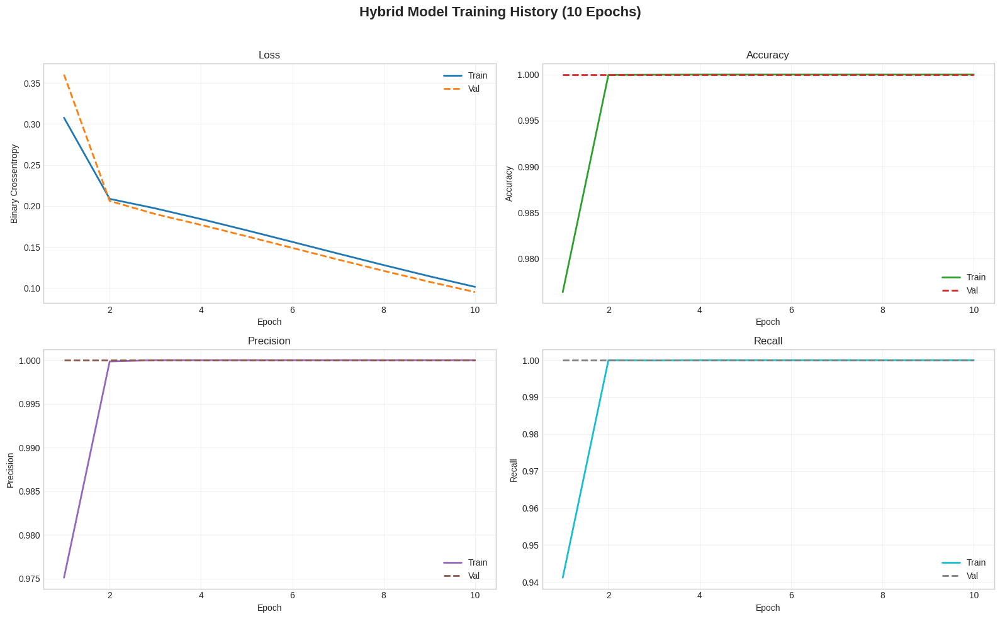

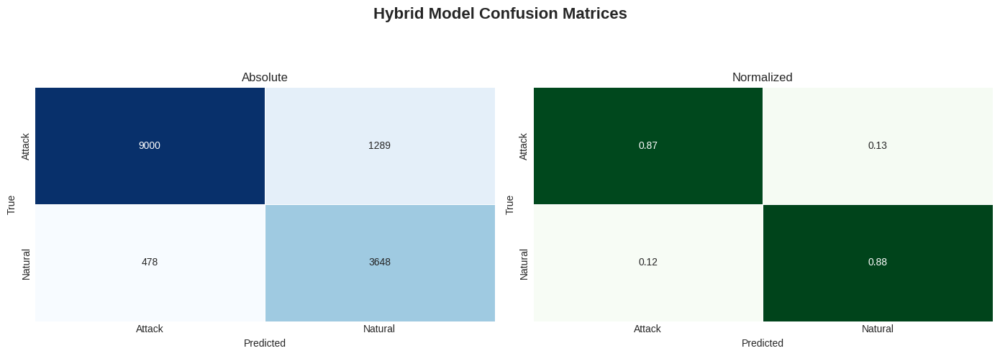

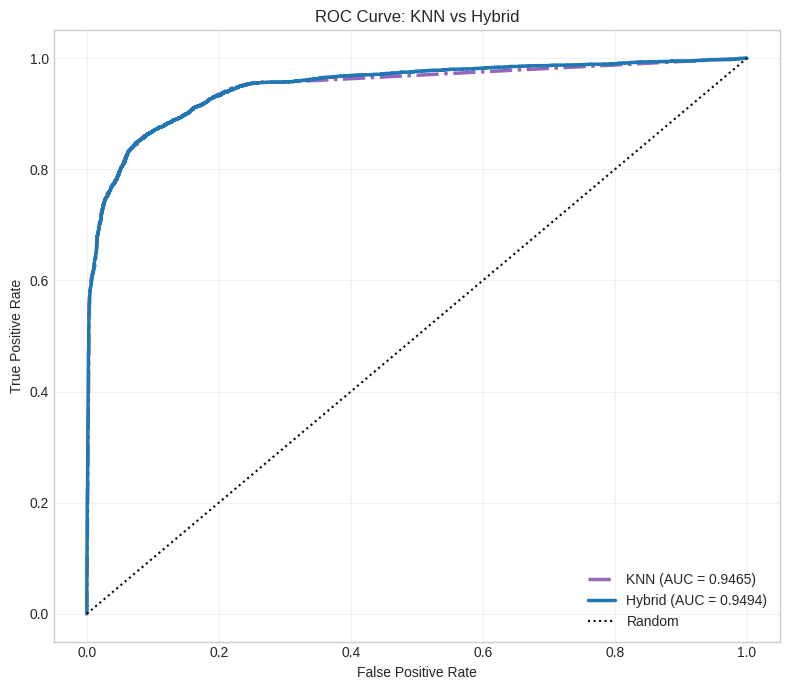

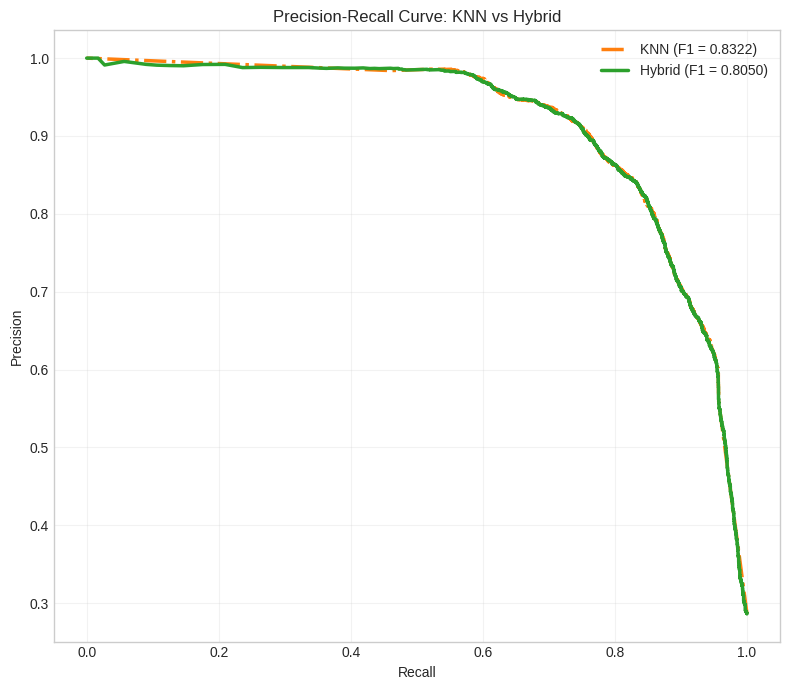

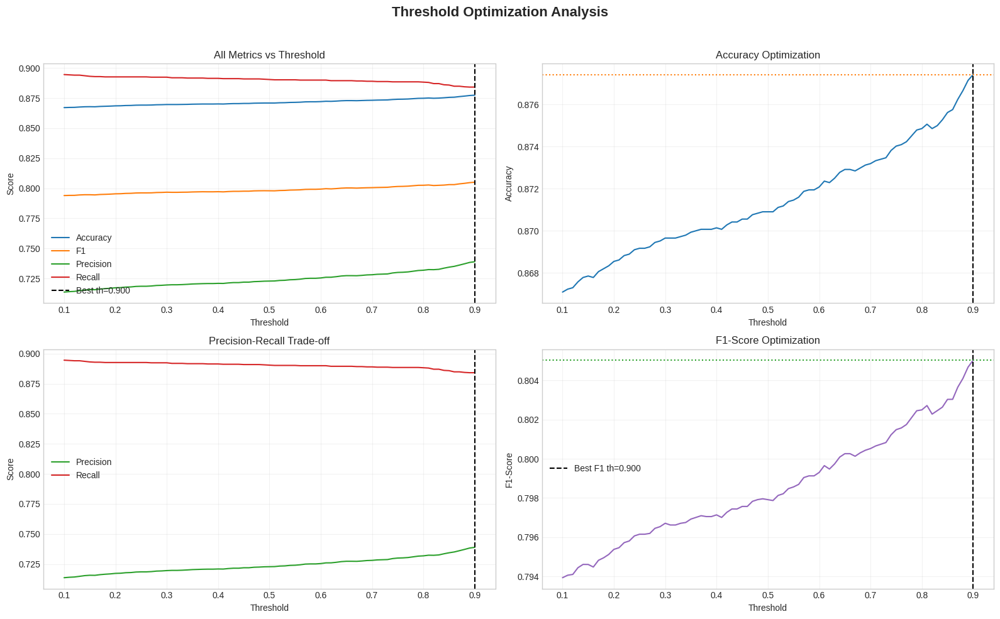


Calculating permutation feature importance for KNN (this may take some time)...


In [ ]:
import os
import numpy as np
import pandas as pd
import sklearn

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    roc_curve, precision_recall_curve
)
from sklearn.utils.class_weight import compute_class_weight
from sklearn.inspection import permutation_importance

import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Conv1D, MaxPooling1D, LSTM, Dense, Dropout,
    BatchNormalization, Bidirectional, SpatialDropout1D,
    GlobalAveragePooling1D, GlobalMaxPooling1D, Input,
    Concatenate, Add, Multiply, Layer, Activation, Lambda
)
from tensorflow.keras.callbacks import ReduceLROnPlateau, ModelCheckpoint, EarlyStopping
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2

plt.style.use("seaborn-v0_8-whitegrid")
sns.set_palette("deep")

print("=" * 80)
print("HYBRID KNN + ENHANCED CNN-BiLSTM MODEL (10 EPOCHS)")
print("USING CLASS WEIGHTS INSTEAD OF SMOTE FOR IMBALANCE HANDLING")
print("=" * 80)
print(f"✓ scikit-learn version: {sklearn.__version__}")
print(f"✓ TensorFlow version: {tf.__version__}")

# ====================================================================
# 1. DATA LOADING
# ====================================================================

data_path = '/kaggle/input/power-system/binaryAllNaturalPlusNormalVsAttacks/'
all_data = []

for i in range(1, 16):
    file_path = f'{data_path}data{i}.csv'
    if os.path.exists(file_path):
        temp_df = pd.read_csv(file_path)
        all_data.append(temp_df)
        print(f"✓ Loaded: data{i}.csv - Shape: {temp_df.shape}")

df = pd.concat(all_data, ignore_index=True)
print(f"\n📦 Combined dataset shape: {df.shape}")

# Clean data
df = df[~df.isin([np.nan, np.inf, -np.inf]).any(axis=1)]
print(f"✓ After cleaning: {df.shape}")

print("\n📊 Class Distribution:")
print(df['marker'].value_counts())

# ====================================================================
# 2. PREPROCESSING
# ====================================================================

X = df.drop('marker', axis=1)
y = df['marker']

encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y)
print(f"\n🏷️ Classes: {encoder.classes_}")

X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded,
    test_size=0.2,
    random_state=21,
    stratify=y_encoded
)

print(f"\nTraining samples: {X_train.shape[0]}")
print(f"Testing samples: {X_test.shape[0]}")
print(f"Features: {X_train.shape[1]}")

# ====================================================================
# 3. COMPUTE CLASS WEIGHTS
# ====================================================================

print("\n⚖️ Computing class weights for imbalance handling...")

class_weights_array = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)
class_weights = {i: w for i, w in enumerate(class_weights_array)}
print(f"Class weights: {class_weights}")

X_train_res = X_train
y_train_res = y_train
print(f"Train class distribution: {pd.Series(y_train_res).value_counts().to_dict()}")

# ====================================================================
# 4. SCALING
# ====================================================================

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_res)
X_test_scaled = scaler.transform(X_test)

# ====================================================================
# 5. KNN TRAINING
# ====================================================================

print("\n" + "=" * 80)
print("PHASE 1: TRAINING K-NEAREST NEIGHBORS CLASSIFIER")
print("=" * 80)

knn_model = KNeighborsClassifier(
    n_neighbors=5,
    weights='distance',
    algorithm='auto',
    leaf_size=30,
    metric='minkowski',
    p=2,
    n_jobs=-1
)

knn_model.fit(X_train_scaled, y_train_res)
print("✓ KNN training complete")

y_pred_knn_train_prob = knn_model.predict_proba(X_train_scaled)
y_pred_knn_test_prob = knn_model.predict_proba(X_test_scaled)
y_pred_knn_test = knn_model.predict(X_test_scaled)

knn_accuracy = accuracy_score(y_test, y_pred_knn_test)
knn_precision = precision_score(y_test, y_pred_knn_test)
knn_recall = recall_score(y_test, y_pred_knn_test)
knn_f1 = f1_score(y_test, y_pred_knn_test)
knn_roc_auc = roc_auc_score(y_test, y_pred_knn_test_prob[:, 1])

print(f"\n📊 KNN STANDALONE METRICS:")
print(f"├─ Accuracy:  {knn_accuracy:.4f} ({knn_accuracy*100:.2f}%)")
print(f"├─ Precision: {knn_precision:.4f}")
print(f"├─ Recall:    {knn_recall:.4f}")
print(f"├─ F1-Score:  {knn_f1:.4f}")
print(f"└─ ROC-AUC:   {knn_roc_auc:.4f}")

# ====================================================================
# 6. PREPARE DATA FOR CNN-BiLSTM
# ====================================================================

print("\n" + "=" * 80)
print("PHASE 2: PREPARING ENHANCED CNN-BiLSTM WITH KNN FEATURES")
print("=" * 80)

def reshape_to_sequences(X_arr, n_timesteps=8):
    n_samples, n_features = X_arr.shape
    features_per_step = n_features // n_timesteps
    n_features_used = features_per_step * n_timesteps
    X_trimmed = X_arr[:, :n_features_used]
    return X_trimmed.reshape((n_samples, n_timesteps, features_per_step))

n_timesteps = 8
X_train_seq = reshape_to_sequences(X_train_scaled, n_timesteps=n_timesteps)
X_test_seq = reshape_to_sequences(X_test_scaled, n_timesteps=n_timesteps)

print(f"✓ Train sequence shape: {X_train_seq.shape}")
print(f"✓ Test sequence shape: {X_test_seq.shape}")
print(f"✓ KNN probability features: {y_pred_knn_train_prob.shape[1]} classes")

# ====================================================================
# 7. ENHANCED HYBRID MODEL: CNN-BiLSTM + KNN (ATTENTION + RESIDUAL)
# ====================================================================

class AttentionLayer(Layer):
    def __init__(self, **kwargs):
        super(AttentionLayer, self).__init__(**kwargs)
    
    def build(self, input_shape):
        self.W = self.add_weight(
            name='attention_weight',
            shape=(input_shape[-1], input_shape[-1]),
            initializer='glorot_uniform',
            trainable=True
        )
        self.b = self.add_weight(
            name='attention_bias',
            shape=(input_shape[-1],),
            initializer='zeros',
            trainable=True
        )
        super(AttentionLayer, self).build(input_shape)
    
    def call(self, x):
        e = tf.keras.backend.tanh(tf.keras.backend.dot(x, self.W) + self.b)
        a = tf.keras.backend.softmax(e, axis=1)
        output = x * a
        return tf.keras.backend.sum(output, axis=1)
    
    def compute_output_shape(self, input_shape):
        return (input_shape[0], input_shape[-1])

def channel_attention(input_feature, ratio=8):
    channel = input_feature.shape[-1]

    avg_pool = GlobalAveragePooling1D()(input_feature)
    avg_pool = Dense(channel // ratio, activation='relu',
                     kernel_regularizer=l2(1e-4))(avg_pool)
    avg_pool = Dense(channel, activation='sigmoid')(avg_pool)

    max_pool = GlobalMaxPooling1D()(input_feature)
    max_pool = Dense(channel // ratio, activation='relu',
                     kernel_regularizer=l2(1e-4))(max_pool)
    max_pool = Dense(channel, activation='sigmoid')(max_pool)

    attention = Add()([avg_pool, max_pool])
    # FIX: wrap expand_dims in a Lambda so it is a Keras op on a KerasTensor
    attention = Lambda(lambda x: tf.expand_dims(x, axis=1))(attention)

    return Multiply()([input_feature, attention])

def residual_cnn_block(x, filters, kernel_size=3, dilation_rate=1):
    conv1 = Conv1D(filters, kernel_size, padding='same',
                   dilation_rate=dilation_rate,
                   kernel_regularizer=l2(1e-4))(x)
    bn1 = BatchNormalization()(conv1)
    act1 = Activation('relu')(bn1)
    
    conv2 = Conv1D(filters, kernel_size, padding='same',
                   dilation_rate=dilation_rate,
                   kernel_regularizer=l2(1e-4))(act1)
    bn2 = BatchNormalization()(conv2)
    
    if x.shape[-1] != filters:
        shortcut = Conv1D(filters, 1, padding='same',
                          kernel_regularizer=l2(1e-4))(x)
        shortcut = BatchNormalization()(shortcut)
    else:
        shortcut = x
    
    added = Add()([bn2, shortcut])
    output = Activation('relu')(added)
    return output

def build_enhanced_hybrid_knn_cnn_bilstm(seq_shape, knn_prob_dim):
    # Sequential branch
    seq_input = Input(shape=seq_shape, name='sequence_input')
    
    # Multi-scale CNN + residual
    res_block1 = residual_cnn_block(seq_input, 64, kernel_size=3, dilation_rate=1)
    res_block1 = residual_cnn_block(res_block1, 64, kernel_size=3, dilation_rate=1)
    pool1 = MaxPooling1D(pool_size=2)(res_block1)
    drop1 = SpatialDropout1D(0.2)(pool1)
    
    res_block2 = residual_cnn_block(drop1, 128, kernel_size=3, dilation_rate=2)
    res_block2 = residual_cnn_block(res_block2, 128, kernel_size=3, dilation_rate=2)
    att_cnn = channel_attention(res_block2, ratio=8)
    pool2 = MaxPooling1D(pool_size=2)(att_cnn)
    drop2 = SpatialDropout1D(0.2)(pool2)
    
    res_block3 = residual_cnn_block(drop2, 256, kernel_size=3, dilation_rate=4)
    att_cnn2 = channel_attention(res_block3, ratio=8)
    drop3 = SpatialDropout1D(0.2)(att_cnn2)
    
    # BiLSTM + attention
    bilstm1 = Bidirectional(LSTM(128, return_sequences=True,
                                 dropout=0.3, recurrent_dropout=0.2))(drop3)
    bilstm1 = BatchNormalization()(bilstm1)
    
    bilstm2 = Bidirectional(LSTM(64, return_sequences=True,
                                 dropout=0.3, recurrent_dropout=0.2))(bilstm1)
    bilstm2 = BatchNormalization()(bilstm2)
    
    attention_output = AttentionLayer()(bilstm2)
    gap = GlobalAveragePooling1D()(bilstm2)
    gmp = GlobalMaxPooling1D()(bilstm2)
    
    temporal_features = Concatenate()([attention_output, gap, gmp])
    temporal_features = Dense(256, activation='relu',
                              kernel_regularizer=l2(1e-4))(temporal_features)
    temporal_features = BatchNormalization()(temporal_features)
    temporal_features = Dropout(0.4)(temporal_features)
    
    # KNN branch
    knn_input = Input(shape=(knn_prob_dim,), name='knn_prob_input')
    
    knn_dense1 = Dense(64, activation='relu',
                       kernel_regularizer=l2(1e-4))(knn_input)
    knn_dense1 = BatchNormalization()(knn_dense1)
    knn_dense1 = Dropout(0.3)(knn_dense1)
    
    knn_dense2 = Dense(32, activation='relu',
                       kernel_regularizer=l2(1e-4))(knn_dense1)
    knn_dense2 = BatchNormalization()(knn_dense2)
    knn_dense2 = Dropout(0.3)(knn_dense2)
    
    # Fusion
    combined = Concatenate()([temporal_features, knn_dense2])
    
    fusion1 = Dense(256, activation='relu',
                    kernel_regularizer=l2(1e-4))(combined)
    fusion1 = BatchNormalization()(fusion1)
    fusion1 = Dropout(0.5)(fusion1)
    
    fusion2 = Dense(128, activation='relu',
                    kernel_regularizer=l2(1e-4))(fusion1)
    fusion2 = BatchNormalization()(fusion2)
    fusion2 = Dropout(0.4)(fusion2)
    
    fusion3 = Dense(64, activation='relu',
                    kernel_regularizer=l2(1e-4))(fusion2)
    fusion3 = Dropout(0.3)(fusion3)
    
    output = Dense(1, activation='sigmoid', name='output')(fusion3)
    
    model = Model(inputs=[seq_input, knn_input],
                  outputs=output,
                  name='Enhanced_Hybrid_KNN_CNN_BiLSTM_Attention')
    return model

model = build_enhanced_hybrid_knn_cnn_bilstm(
    seq_shape=(X_train_seq.shape[1], X_train_seq.shape[2]),
    knn_prob_dim=y_pred_knn_train_prob.shape[1]
)

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall'),
        tf.keras.metrics.AUC(name='auc')
    ]
)

print("\n" + "=" * 80)
print("ENHANCED MODEL ARCHITECTURE:")
print("=" * 80)
model.summary()
print(f"\n📊 Total trainable parameters: {model.count_params():,}")

# ====================================================================
# 8. CALLBACKS
# ====================================================================

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=1e-7,
    verbose=1
)

model_checkpoint = ModelCheckpoint(
    filepath='best_enhanced_hybrid_knn_cnn_bilstm.keras',
    monitor='val_accuracy',
    save_best_only=True,
    verbose=1,
    mode='max'
)

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True,
    verbose=1
)

callbacks = [reduce_lr, model_checkpoint, early_stopping]

# ====================================================================
# 9. TRAINING (10 EPOCHS)
# ====================================================================

print("\n" + "=" * 80)
print("PHASE 3: TRAINING ENHANCED HYBRID MODEL (10 EPOCHS WITH CLASS WEIGHTS)")
print("=" * 80)

history = model.fit(
    [X_train_seq, y_pred_knn_train_prob], y_train_res,
    epochs=10,            # fixed to 10 epochs
    batch_size=256,
    validation_split=0.15,
    class_weight=class_weights,
    callbacks=callbacks,
    verbose=1,
    shuffle=True
)

# ====================================================================
# 10. EVALUATION WITH THRESHOLD TUNING
# ====================================================================

print("\n" + "=" * 80)
print("PHASE 4: EVALUATION AND THRESHOLD OPTIMIZATION")
print("=" * 80)

y_pred_hybrid_prob = model.predict([X_test_seq, y_pred_knn_test_prob], verbose=0).ravel()

thresholds = np.linspace(0.1, 0.9, 81)
best_acc, best_th = 0.0, 0.5
acc_list, f1_list, prec_list, rec_list = [], [], [], []

for th in thresholds:
    y_hat = (y_pred_hybrid_prob >= th).astype(int)
    acc = accuracy_score(y_test, y_hat)
    f1 = f1_score(y_test, y_hat)
    prec = precision_score(y_test, y_hat)
    rec = recall_score(y_test, y_hat)

    acc_list.append(acc)
    f1_list.append(f1)
    prec_list.append(prec)
    rec_list.append(rec)

    if acc > best_acc:
        best_acc, best_th = acc, th

y_pred_hybrid = (y_pred_hybrid_prob >= best_th).astype(int)

hybrid_accuracy = accuracy_score(y_test, y_pred_hybrid)
hybrid_precision = precision_score(y_test, y_pred_hybrid)
hybrid_recall = recall_score(y_test, y_pred_hybrid)
hybrid_f1 = f1_score(y_test, y_pred_hybrid)
hybrid_roc_auc = roc_auc_score(y_test, y_pred_hybrid_prob)

cm = confusion_matrix(y_test, y_pred_hybrid)
cm_norm = confusion_matrix(y_test, y_pred_hybrid, normalize='true')

print(f"\n🎯 HYBRID MODEL PERFORMANCE (threshold={best_th:.3f}):")
print(f"├─ Accuracy:  {hybrid_accuracy:.4f} ({hybrid_accuracy*100:.2f}%)")
print(f"├─ Precision: {hybrid_precision:.4f}")
print(f"├─ Recall:    {hybrid_recall:.4f}")
print(f"├─ F1-Score:  {hybrid_f1:.4f}")
print(f"└─ ROC-AUC:   {hybrid_roc_auc:.4f}")

print(f"\n📈 IMPROVEMENT OVER KNN ALONE:")
print(f"├─ Accuracy:  {(hybrid_accuracy - knn_accuracy)*100:+.2f}%")
print(f"├─ Precision: {(hybrid_precision - knn_precision)*100:+.2f}%")
print(f"├─ Recall:    {(hybrid_recall - knn_recall)*100:+.2f}%")
print(f"├─ F1-Score:  {(hybrid_f1 - knn_f1)*100:+.2f}%")
print(f"└─ ROC-AUC:   {(hybrid_roc_auc - knn_roc_auc)*100:+.2f}%")

print("\n📋 CONFUSION MATRIX:")
print(cm)

print("\n📋 NORMALIZED CONFUSION MATRIX:")
print(cm_norm)

print("\n📊 CLASSIFICATION REPORT:")
print(classification_report(y_test, y_pred_hybrid,
                          target_names=encoder.classes_.astype(str)))

# ====================================================================
# 11. VISUALIZATIONS
# ====================================================================

print("\n" + "=" * 80)
print("PHASE 5: GENERATING COMPREHENSIVE VISUALIZATIONS")
print("=" * 80)

plt.rcParams['figure.figsize'] = (10, 7)
plt.rcParams['font.size'] = 10

# 11.1 TRAINING HISTORY
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle('Hybrid Model Training History (10 Epochs)', fontsize=16, fontweight='bold')

epochs = range(1, len(history.history['loss']) + 1)

axes[0, 0].plot(epochs, history.history['loss'], label='Train', color='#1f77b4', linewidth=2)
axes[0, 0].plot(epochs, history.history['val_loss'], label='Val', color='#ff7f0e',
                linewidth=2, linestyle='--')
axes[0, 0].set_title('Loss')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Binary Crossentropy')
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.25)

axes[0, 1].plot(epochs, history.history['accuracy'], label='Train', color='#2ca02c', linewidth=2)
axes[0, 1].plot(epochs, history.history['val_accuracy'], label='Val', color='#d62728',
                linewidth=2, linestyle='--')
axes[0, 1].set_title('Accuracy')
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('Accuracy')
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.25)

axes[1, 0].plot(epochs, history.history['precision'], label='Train', color='#9467bd', linewidth=2)
axes[1, 0].plot(epochs, history.history['val_precision'], label='Val', color='#8c564b',
                linewidth=2, linestyle='--')
axes[1, 0].set_title('Precision')
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('Precision')
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.25)

axes[1, 1].plot(epochs, history.history['recall'], label='Train', color='#17becf', linewidth=2)
axes[1, 1].plot(epochs, history.history['val_recall'], label='Val', color='#7f7f7f',
                linewidth=2, linestyle='--')
axes[1, 1].set_title('Recall')
axes[1, 1].set_xlabel('Epoch')
axes[1, 1].set_ylabel('Recall')
axes[1, 1].legend()
axes[1, 1].grid(alpha=0.25)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig('01_training_history_knn.png', dpi=300, bbox_inches='tight')
plt.show()

# 11.2 CONFUSION MATRICES
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Hybrid Model Confusion Matrices', fontsize=16, fontweight='bold')

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=encoder.classes_, yticklabels=encoder.classes_,
            ax=axes[0], cbar=False, linewidths=0.5, linecolor='white')
axes[0].set_title('Absolute')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('True')

sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Greens',
            xticklabels=encoder.classes_, yticklabels=encoder.classes_,
            ax=axes[1], cbar=False, linewidths=0.5, linecolor='white')
axes[1].set_title('Normalized')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('True')

plt.tight_layout(rect=[0, 0, 1, 0.9])
plt.savefig('02_confusion_matrices_knn.png', dpi=300, bbox_inches='tight')
plt.show()

# 11.3 ROC CURVE
fpr_knn, tpr_knn, _ = roc_curve(y_test, y_pred_knn_test_prob[:, 1])
fpr_hyb, tpr_hyb, _ = roc_curve(y_test, y_pred_hybrid_prob)

plt.figure(figsize=(8, 7))
plt.plot(fpr_knn, tpr_knn, label=f'KNN (AUC = {knn_roc_auc:.4f})',
         color='#9467bd', linewidth=2.5, linestyle='-.')
plt.plot(fpr_hyb, tpr_hyb, label=f'Hybrid (AUC = {hybrid_roc_auc:.4f})',
         color='#1f77b4', linewidth=2.5)
plt.plot([0, 1], [0, 1], 'k:', label='Random')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve: KNN vs Hybrid')
plt.legend(loc='lower right')
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig('03_roc_curve_knn.png', dpi=300, bbox_inches='tight')
plt.show()

# 11.4 PRECISION-RECALL CURVE
prec_knn, rec_knn, _ = precision_recall_curve(y_test, y_pred_knn_test_prob[:, 1])
prec_hyb, rec_hyb, _ = precision_recall_curve(y_test, y_pred_hybrid_prob)

plt.figure(figsize=(8, 7))
plt.plot(rec_knn, prec_knn, label=f'KNN (F1 = {knn_f1:.4f})',
         color='#ff7f0e', linewidth=2.5, linestyle='-.')
plt.plot(rec_hyb, prec_hyb, label=f'Hybrid (F1 = {hybrid_f1:.4f})',
         color='#2ca02c', linewidth=2.5)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve: KNN vs Hybrid')
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig('04_precision_recall_knn.png', dpi=300, bbox_inches='tight')
plt.show()

# 11.5 THRESHOLD OPTIMIZATION
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle('Threshold Optimization Analysis', fontsize=16, fontweight='bold')

axes[0, 0].plot(thresholds, acc_list, label='Accuracy', color='#1f77b4')
axes[0, 0].plot(thresholds, f1_list, label='F1', color='#ff7f0e')
axes[0, 0].plot(thresholds, prec_list, label='Precision', color='#2ca02c')
axes[0, 0].plot(thresholds, rec_list, label='Recall', color='#d62728')
axes[0, 0].axvline(best_th, color='black', linestyle='--', label=f'Best th={best_th:.3f}')
axes[0, 0].set_xlabel('Threshold')
axes[0, 0].set_ylabel('Score')
axes[0, 0].set_title('All Metrics vs Threshold')
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.25)

axes[0, 1].plot(thresholds, acc_list, color='#1f77b4')
axes[0, 1].axvline(best_th, color='black', linestyle='--')
axes[0, 1].axhline(best_acc, color='#ff7f0e', linestyle=':')
axes[0, 1].set_xlabel('Threshold')
axes[0, 1].set_ylabel('Accuracy')
axes[0, 1].set_title('Accuracy Optimization')
axes[0, 1].grid(alpha=0.25)

axes[1, 0].plot(thresholds, prec_list, label='Precision', color='#2ca02c')
axes[1, 0].plot(thresholds, rec_list, label='Recall', color='#d62728')
axes[1, 0].axvline(best_th, color='black', linestyle='--')
axes[1, 0].set_xlabel('Threshold')
axes[1, 0].set_ylabel('Score')
axes[1, 0].set_title('Precision-Recall Trade-off')
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.25)

best_f1_idx = np.argmax(f1_list)
best_f1_th = thresholds[best_f1_idx]
best_f1_val = f1_list[best_f1_idx]

axes[1, 1].plot(thresholds, f1_list, color='#9467bd')
axes[1, 1].axvline(best_f1_th, color='black', linestyle='--',
                   label=f'Best F1 th={best_f1_th:.3f}')
axes[1, 1].axhline(best_f1_val, color='#2ca02c', linestyle=':')
axes[1, 1].set_xlabel('Threshold')
axes[1, 1].set_ylabel('F1-Score')
axes[1, 1].set_title('F1-Score Optimization')
axes[1, 1].legend()
axes[1, 1].grid(alpha=0.25)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig('05_threshold_optimization_knn.png', dpi=300, bbox_inches='tight')
plt.show()

# 11.6 FEATURE IMPORTANCE VIA PERMUTATION
print("\nCalculating permutation feature importance for KNN (this may take some time)...")
perm = permutation_importance(
    knn_model, X_test_scaled, y_test,
    n_repeats=10, random_state=42, n_jobs=-1
)

feature_importance = pd.DataFrame({
    'feature': X.columns,
    'importance': perm.importances_mean
}).sort_values('importance', ascending=False)

plt.figure(figsize=(10, 8))
top_n = 20
top_features = feature_importance.head(top_n)
colors = sns.color_palette("viridis", top_n)
plt.barh(top_features['feature'], top_features['importance'],
         color=colors, edgecolor='black')
plt.xlabel('Permutation Importance Score')
plt.ylabel('Feature')
plt.title(f'Top {top_n} Features (KNN - Permutation Importance)')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig('06_feature_importance_knn.png', dpi=300, bbox_inches='tight')
plt.show()

# 11.7 MODEL COMPARISON BAR CHART
models = ['KNN', 'Hybrid']
metrics = {
    'Accuracy': [knn_accuracy, hybrid_accuracy],
    'Precision': [knn_precision, hybrid_precision],
    'Recall': [knn_recall, hybrid_recall],
    'F1-Score': [knn_f1, hybrid_f1],
    'ROC-AUC': [knn_roc_auc, hybrid_roc_auc]
}

x = np.arange(len(models))
width = 0.15
fig, ax = plt.subplots(figsize=(12, 7))

colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']
for i, (metric_name, values) in enumerate(metrics.items()):
    offset = width * (i - 2)
    bars = ax.bar(x + offset, values, width,
                  label=metric_name, color=colors[i], edgecolor='black')
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2., h + 0.005,
                f'{h:.3f}', ha='center', va='bottom', fontsize=8)

ax.set_xlabel('Model')
ax.set_ylabel('Score')
ax.set_title('Performance Comparison: KNN vs Hybrid')
ax.set_xticks(x)
ax.set_xticklabels(models)
ax.legend(loc='lower right')
ax.set_ylim([0, 1.05])
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.savefig('07_model_comparison_knn.png', dpi=300, bbox_inches='tight')
plt.show()

# 11.8 CLASS DISTRIBUTION
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Class Distribution Analysis', fontsize=16, fontweight='bold')

class_counts = pd.Series(y_encoded).value_counts().sort_index()
axes[0].bar(encoder.classes_, class_counts.values,
            color=['#1f77b4', '#d62728'], edgecolor='black')
axes[0].set_title('Original Dataset')
axes[0].set_xlabel('Class')
axes[0].set_ylabel('Count')
for i, v in enumerate(class_counts.values):
    axes[0].text(i, v + 50, str(v), ha='center', fontsize=9)

train_counts = pd.Series(y_train_res).value_counts().sort_index()
axes[1].bar(encoder.classes_, train_counts.values,
            color=['#1f77b4', '#d62728'], edgecolor='black')
axes[1].set_title('Training Set')
axes[1].set_xlabel('Class')
axes[1].set_ylabel('Count')
for i, v in enumerate(train_counts.values):
    axes[1].text(i, v + 50, str(v), ha='center', fontsize=9)

weight_values = [class_weights[i] for i in sorted(class_weights.keys())]
axes[2].bar(encoder.classes_, weight_values,
            color=['#2ca02c', '#ff7f0e'], edgecolor='black')
axes[2].set_title('Class Weights')
axes[2].set_xlabel('Class')
axes[2].set_ylabel('Weight')
for i, v in enumerate(weight_values):
    axes[2].text(i, v + 0.02, f'{v:.3f}', ha='center', fontsize=9)

plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.savefig('08_class_distribution_knn.png', dpi=300, bbox_inches='tight')
plt.show()

# 11.9 PROBABILITY DISTRIBUTIONS
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Prediction Probability Distributions', fontsize=16, fontweight='bold')

axes[0].hist(y_pred_knn_test_prob[y_test == 0, 1], bins=40, alpha=0.6,
             label='Natural (0)', color='#1f77b4', edgecolor='black')
axes[0].hist(y_pred_knn_test_prob[y_test == 1, 1], bins=40, alpha=0.6,
             label='Attack (1)', color='#d62728', edgecolor='black')
axes[0].axvline(0.5, color='black', linestyle='--', label='Threshold 0.5')
axes[0].set_title('KNN Probabilities')
axes[0].set_xlabel('Predicted Probability')
axes[0].set_ylabel('Frequency')
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].hist(y_pred_hybrid_prob[y_test == 0], bins=40, alpha=0.6,
             label='Natural (0)', color='#1f77b4', edgecolor='black')
axes[1].hist(y_pred_hybrid_prob[y_test == 1], bins=40, alpha=0.6,
             label='Attack (1)', color='#d62728', edgecolor='black')
axes[1].axvline(best_th, color='black', linestyle='--',
                label=f'Optimal th={best_th:.3f}')
axes[1].set_title('Hybrid Probabilities')
axes[1].set_xlabel('Predicted Probability')
axes[1].set_ylabel('Frequency')
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.tight_layout(rect=[0, 0, 1, 0.9])
plt.savefig('09_probability_distributions_knn.png', dpi=300, bbox_inches='tight')
plt.show()

# 11.10 LEARNING RATE SCHEDULE
if 'lr' in history.history:
    plt.figure(figsize=(8, 5))
    plt.plot(history.history['lr'], marker='o', color='#9467bd')
    plt.xlabel('Epoch')
    plt.ylabel('Learning Rate')
    plt.yscale('log')
    plt.title('Learning Rate Schedule')
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.savefig('10_learning_rate_schedule_knn.png', dpi=300, bbox_inches='tight')
    plt.show()

# 11.11 ERROR ANALYSIS
misclassified_indices = np.where(y_pred_hybrid != y_test)[0]
correct_indices = np.where(y_pred_hybrid == y_test)[0]

error_stats = {
    'False Positives (FP)': np.sum((y_pred_hybrid == 1) & (y_test == 0)),
    'False Negatives (FN)': np.sum((y_pred_hybrid == 0) & (y_test == 1)),
    'True Positives (TP)': np.sum((y_pred_hybrid == 1) & (y_test == 1)),
    'True Negatives (TN)': np.sum((y_pred_hybrid == 0) & (y_test == 0))
}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Error Analysis', fontsize=16, fontweight='bold')

axes[0].bar(error_stats.keys(), error_stats.values(),
            color=['#d62728', '#ff7f0e', '#2ca02c', '#1f77b4'],
            edgecolor='black')
axes[0].set_ylabel('Count')
axes[0].set_title('Error Types')
axes[0].tick_params(axis='x', rotation=30)
for i, (k, v) in enumerate(error_stats.items()):
    axes[0].text(i, v + 10, str(v), ha='center', fontsize=9)

correct_conf = y_pred_hybrid_prob[correct_indices]
incorrect_conf = y_pred_hybrid_prob[misclassified_indices]

axes[1].hist(correct_conf, bins=30, alpha=0.6, label=f'Correct ({len(correct_indices)})',
             color='#2ca02c', edgecolor='black')
axes[1].hist(incorrect_conf, bins=30, alpha=0.6, label=f'Incorrect ({len(misclassified_indices)})',
             color='#d62728', edgecolor='black')
axes[1].set_xlabel('Prediction Confidence')
axes[1].set_ylabel('Frequency')
axes[1].set_title('Confidence: Correct vs Incorrect')
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.tight_layout(rect=[0, 0, 1, 0.9])
plt.savefig('11_error_analysis_knn.png', dpi=300, bbox_inches='tight')
plt.show()

# 11.12 GAIN AND LIFT
sorted_indices = np.argsort(y_pred_hybrid_prob)[::-1]
y_test_sorted = y_test[sorted_indices]

cumulative_gains = np.cumsum(y_test_sorted) / np.sum(y_test_sorted) * 100
sample_percentage = np.arange(1, len(y_test_sorted) + 1) / len(y_test_sorted) * 100
baseline = sample_percentage
lift = cumulative_gains / sample_percentage

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Gain and Lift Analysis', fontsize=16, fontweight='bold')

axes[0].plot(sample_percentage, cumulative_gains, color='#1f77b4', linewidth=2,
             label='Hybrid')
axes[0].plot(sample_percentage, baseline, color='gray', linestyle='--', label='Baseline')
axes[0].fill_between(sample_percentage, cumulative_gains, baseline,
                     color='#1f77b4', alpha=0.2)
axes[0].set_xlabel('% of Sample')
axes[0].set_ylabel('% of Positives Captured')
axes[0].set_title('Cumulative Gain')
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].plot(sample_percentage, lift, color='#ff7f0e', linewidth=2)
axes[1].axhline(1, color='gray', linestyle='--', label='Baseline (Lift=1)')
axes[1].set_xlabel('% of Sample')
axes[1].set_ylabel('Lift')
axes[1].set_title('Lift Chart')
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.tight_layout(rect=[0, 0, 1, 0.9])
plt.savefig('12_gain_lift_knn.png', dpi=300, bbox_inches='tight')
plt.show()

# 11.13 RADAR CHART
from math import pi

categories = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']
knn_values = [knn_accuracy, knn_precision, knn_recall, knn_f1, knn_roc_auc]
hyb_values = [hybrid_accuracy, hybrid_precision, hybrid_recall, hybrid_f1, hybrid_roc_auc]

N = len(categories)
angles = [n / float(N) * 2 * pi for n in range(N)]
knn_values += knn_values[:1]
hyb_values += hyb_values[:1]
angles += angles[:1]

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(projection='polar'))
ax.plot(angles, knn_values, 'o-', linewidth=2, label='KNN', color='#ff7f0e')
ax.fill(angles, knn_values, alpha=0.25, color='#ff7f0e')
ax.plot(angles, hyb_values, 'o-', linewidth=2, label='Hybrid', color='#1f77b4')
ax.fill(angles, hyb_values, alpha=0.25, color='#1f77b4')

ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories, fontsize=10)
ax.set_ylim(0, 1)
ax.set_yticks([0.2, 0.4, 0.6, 0.8, 1.0])
ax.set_yticklabels(['0.2', '0.4', '0.6', '0.8', '1.0'], fontsize=8)
ax.set_title('Performance Metrics Radar Chart', fontsize=14, fontweight='bold', pad=20)
ax.legend(loc='upper right', bbox_to_anchor=(1.2, 1.1), fontsize=9)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('13_radar_chart_knn.png', dpi=300, bbox_inches='tight')
plt.show()

# ====================================================================
# SUMMARY TABLE
# ====================================================================

print("\n" + "=" * 80)
print("FINAL SUMMARY TABLE")
print("=" * 80)

summary_df = pd.DataFrame({
    'Model': ['KNN', 'Hybrid CNN-BiLSTM+KNN (Enhanced)'],
    'Accuracy': [f'{knn_accuracy:.4f}', f'{hybrid_accuracy:.4f}'],
    'Precision': [f'{knn_precision:.4f}', f'{hybrid_precision:.4f}'],
    'Recall': [f'{knn_recall:.4f}', f'{hybrid_recall:.4f}'],
    'F1-Score': [f'{knn_f1:.4f}', f'{hybrid_f1:.4f}'],
    'ROC-AUC': [f'{knn_roc_auc:.4f}', f'{hybrid_roc_auc:.4f}']
})

print(summary_df.to_string(index=False))

print("\n" + "=" * 80)
print("✓ ALL VISUALIZATIONS COMPLETE!")
print("=" * 80)
print("\nTotal figures generated: 13")
for i in range(1, 14):
    print(f"  • {i:02d}_*_knn.png")

2025-12-18 16:09:49.340529: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1766074189.540432      48 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1766074189.609448      48 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

... (7 outputs left out)

 Non-trainable params: 5,696 (22.25 KB)


📊 Total trainable parameters: 1,394,945

PHASE 3: TRAINING ENHANCED HYBRID MODEL (10 EPOCHS WITH CLASS WEIGHTS)
Epoch 1/10


I0000 00:00:1766074256.459377     113 cuda_dnn.cc:529] Loaded cuDNN version 90300


192/192 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 0.9005 - auc: 0.9520 - loss: 0.4334 - precision: 0.7968 - recall: 0.9068
Epoch 1: val_accuracy improved from -inf to 0.99977, saving model to best_enhanced_hybrid_knn_cnn_bilstm.keras
192/192 ━━━━━━━━━━━━━━━━━━━━ 49s 88ms/step - accuracy: 0.9008 - auc: 0.9522 - loss: 0.4327 - precision: 0.7975 - recall: 0.9071 - val_accuracy: 0.9998 - val_auc: 1.0000 - val_loss: 0.2862 - val_precision: 1.0000 - val_recall: 0.9992 - learning_rate: 0.0010
Epoch 2/10
192/192 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 0.9999 - auc: 1.0000 - loss: 0.2100 - precision: 0.9998 - recall: 0.9999
Epoch 2: val_accuracy improved from 0.99977 to 1.00000, saving model to best_enhanced_hybrid_knn_cnn_bilstm.keras
192/192 ━━━━━━━━━━━━━━━━━━━━ 13s 70ms/step - accuracy: 0.9999 - auc: 1.0000 - loss: 0.2099 - precision: 0.9998 - recall: 0.9999 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.2005 - val_precision: 1.0000 - val_recall: 1.0000 - learning_rate: 0.0

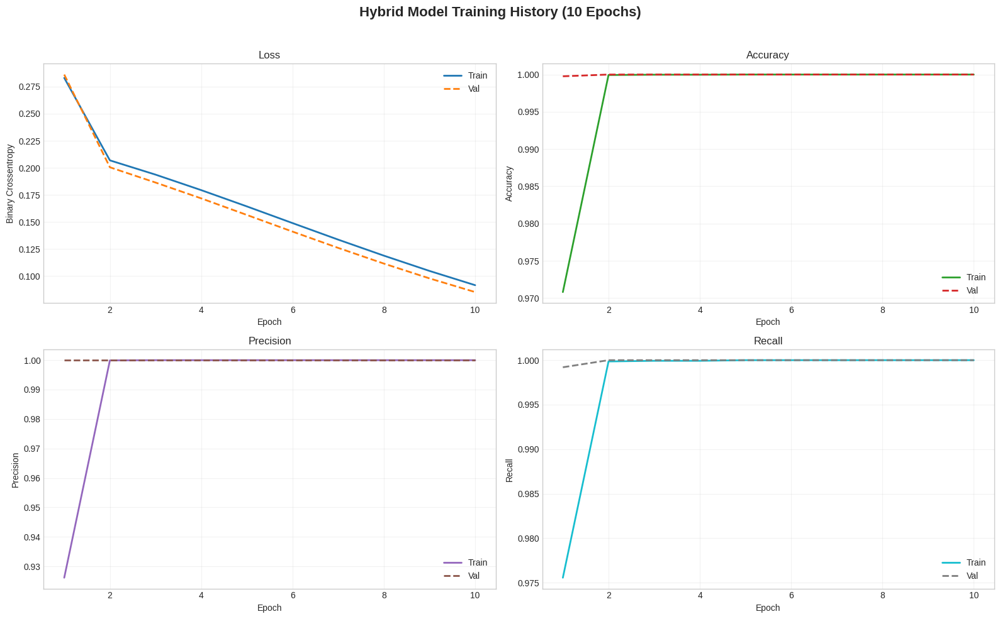

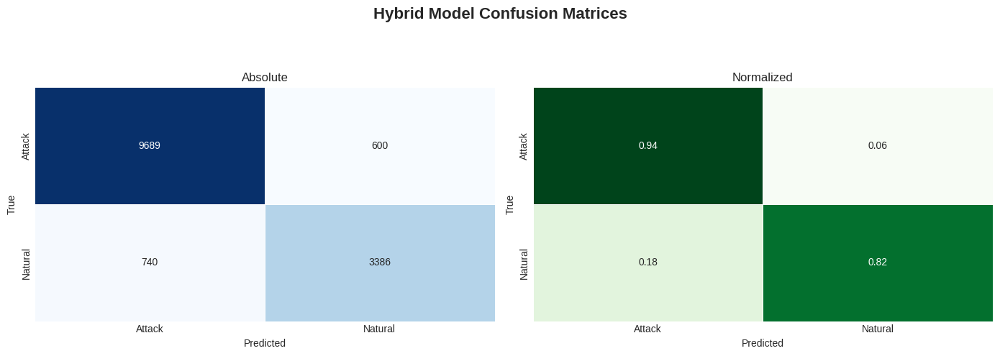

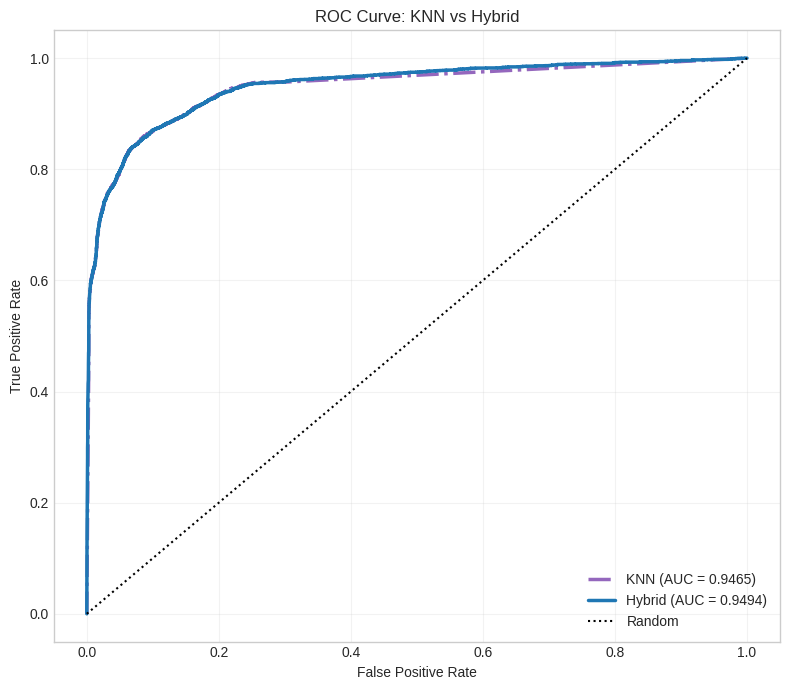

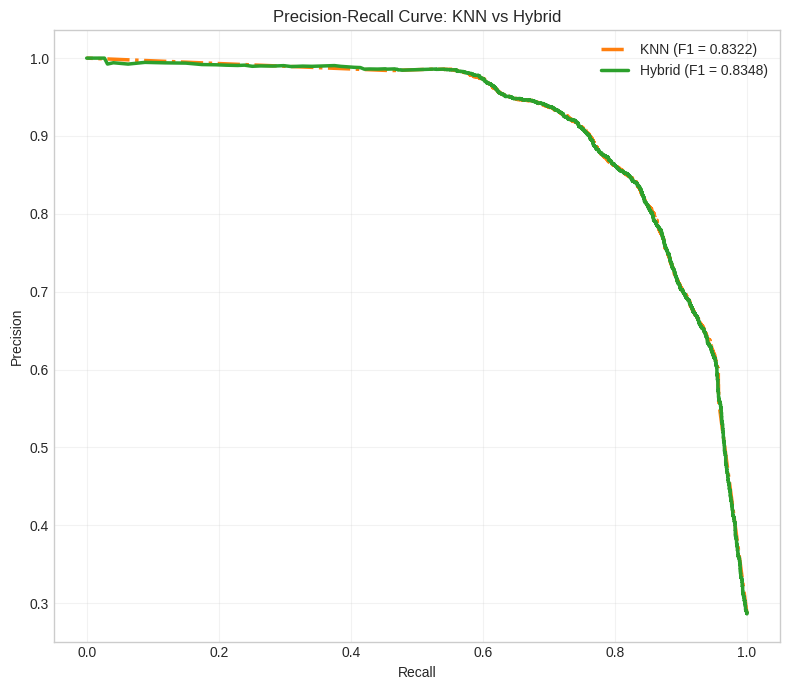

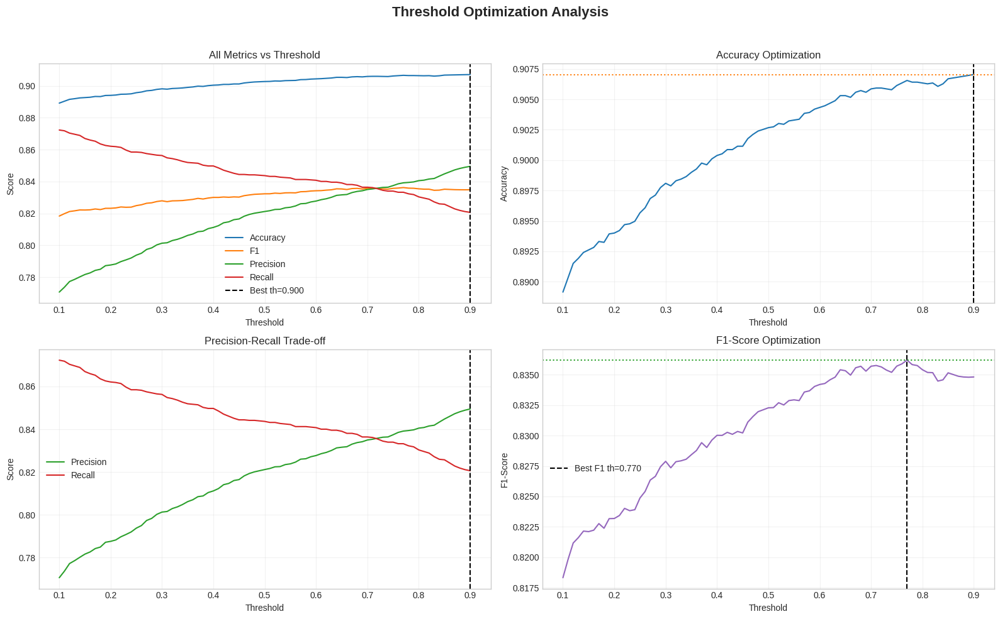


Calculating permutation feature importance for KNN (this may take some time)...


KeyboardInterrupt: 

In [1]:
import os
import numpy as np
import pandas as pd
import sklearn

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    roc_curve, precision_recall_curve
)
from sklearn.utils.class_weight import compute_class_weight
from sklearn.inspection import permutation_importance

import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Conv1D, MaxPooling1D, LSTM, Dense, Dropout,
    BatchNormalization, Bidirectional, SpatialDropout1D,
    GlobalAveragePooling1D, GlobalMaxPooling1D, Input,
    Concatenate, Add, Multiply, Layer, Activation, Lambda
)
from tensorflow.keras.callbacks import ReduceLROnPlateau, ModelCheckpoint, EarlyStopping
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2

plt.style.use("seaborn-v0_8-whitegrid")
sns.set_palette("deep")

print("=" * 80)
print("HYBRID KNN + ENHANCED CNN-BiLSTM MODEL (10 EPOCHS)")
print("USING CLASS WEIGHTS INSTEAD OF SMOTE FOR IMBALANCE HANDLING")
print("=" * 80)
print(f"✓ scikit-learn version: {sklearn.__version__}")
print(f"✓ TensorFlow version: {tf.__version__}")

# ====================================================================
# 1. DATA LOADING
# ====================================================================

data_path = '/kaggle/input/power-system/binaryAllNaturalPlusNormalVsAttacks/'
all_data = []

for i in range(1, 16):
    file_path = f'{data_path}data{i}.csv'
    if os.path.exists(file_path):
        temp_df = pd.read_csv(file_path)
        all_data.append(temp_df)
        print(f"✓ Loaded: data{i}.csv - Shape: {temp_df.shape}")

df = pd.concat(all_data, ignore_index=True)
print(f"\n📦 Combined dataset shape: {df.shape}")

# Clean data
df = df[~df.isin([np.nan, np.inf, -np.inf]).any(axis=1)]
print(f"✓ After cleaning: {df.shape}")

print("\n📊 Class Distribution:")
print(df['marker'].value_counts())

# ====================================================================
# 2. PREPROCESSING
# ====================================================================

X = df.drop('marker', axis=1)
y = df['marker']

encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y)
print(f"\n🏷️ Classes: {encoder.classes_}")

X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded,
    test_size=0.2,
    random_state=21,
    stratify=y_encoded
)

print(f"\nTraining samples: {X_train.shape[0]}")
print(f"Testing samples: {X_test.shape[0]}")
print(f"Features: {X_train.shape[1]}")

# ====================================================================
# 3. COMPUTE CLASS WEIGHTS
# ====================================================================

print("\n⚖️ Computing class weights for imbalance handling...")

class_weights_array = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)
class_weights = {i: w for i, w in enumerate(class_weights_array)}
print(f"Class weights: {class_weights}")

X_train_res = X_train
y_train_res = y_train
print(f"Train class distribution: {pd.Series(y_train_res).value_counts().to_dict()}")

# ====================================================================
# 4. SCALING
# ====================================================================

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_res)
X_test_scaled = scaler.transform(X_test)

# ====================================================================
# 5. KNN TRAINING
# ====================================================================

print("\n" + "=" * 80)
print("PHASE 1: TRAINING K-NEAREST NEIGHBORS CLASSIFIER")
print("=" * 80)

knn_model = KNeighborsClassifier(
    n_neighbors=5,
    weights='distance',
    algorithm='auto',
    leaf_size=30,
    metric='minkowski',
    p=2,
    n_jobs=-1
)

knn_model.fit(X_train_scaled, y_train_res)
print("✓ KNN training complete")

y_pred_knn_train_prob = knn_model.predict_proba(X_train_scaled)
y_pred_knn_test_prob = knn_model.predict_proba(X_test_scaled)
y_pred_knn_test = knn_model.predict(X_test_scaled)

knn_accuracy = accuracy_score(y_test, y_pred_knn_test)
knn_precision = precision_score(y_test, y_pred_knn_test)
knn_recall = recall_score(y_test, y_pred_knn_test)
knn_f1 = f1_score(y_test, y_pred_knn_test)
knn_roc_auc = roc_auc_score(y_test, y_pred_knn_test_prob[:, 1])

print(f"\n📊 KNN STANDALONE METRICS:")
print(f"├─ Accuracy:  {knn_accuracy:.4f} ({knn_accuracy*100:.2f}%)")
print(f"├─ Precision: {knn_precision:.4f}")
print(f"├─ Recall:    {knn_recall:.4f}")
print(f"├─ F1-Score:  {knn_f1:.4f}")
print(f"└─ ROC-AUC:   {knn_roc_auc:.4f}")

# ====================================================================
# 6. PREPARE DATA FOR CNN-BiLSTM
# ====================================================================

print("\n" + "=" * 80)
print("PHASE 2: PREPARING ENHANCED CNN-BiLSTM WITH KNN FEATURES")
print("=" * 80)

def reshape_to_sequences(X_arr, n_timesteps=8):
    n_samples, n_features = X_arr.shape
    features_per_step = n_features // n_timesteps
    n_features_used = features_per_step * n_timesteps
    X_trimmed = X_arr[:, :n_features_used]
    return X_trimmed.reshape((n_samples, n_timesteps, features_per_step))

n_timesteps = 8
X_train_seq = reshape_to_sequences(X_train_scaled, n_timesteps=n_timesteps)
X_test_seq = reshape_to_sequences(X_test_scaled, n_timesteps=n_timesteps)

print(f"✓ Train sequence shape: {X_train_seq.shape}")
print(f"✓ Test sequence shape: {X_test_seq.shape}")
print(f"✓ KNN probability features: {y_pred_knn_train_prob.shape[1]} classes")

# ====================================================================
# 7. ENHANCED HYBRID MODEL: CNN-BiLSTM + KNN (ATTENTION + RESIDUAL)
# ====================================================================

class AttentionLayer(Layer):
    def __init__(self, **kwargs):
        super(AttentionLayer, self).__init__(**kwargs)
    
    def build(self, input_shape):
        self.W = self.add_weight(
            name='attention_weight',
            shape=(input_shape[-1], input_shape[-1]),
            initializer='glorot_uniform',
            trainable=True
        )
        self.b = self.add_weight(
            name='attention_bias',
            shape=(input_shape[-1],),
            initializer='zeros',
            trainable=True
        )
        super(AttentionLayer, self).build(input_shape)
    
    def call(self, x):
        e = tf.keras.backend.tanh(tf.keras.backend.dot(x, self.W) + self.b)
        a = tf.keras.backend.softmax(e, axis=1)
        output = x * a
        return tf.keras.backend.sum(output, axis=1)
    
    def compute_output_shape(self, input_shape):
        return (input_shape[0], input_shape[-1])

def channel_attention(input_feature, ratio=8):
    channel = input_feature.shape[-1]

    avg_pool = GlobalAveragePooling1D()(input_feature)
    avg_pool = Dense(channel // ratio, activation='relu',
                     kernel_regularizer=l2(1e-4))(avg_pool)
    avg_pool = Dense(channel, activation='sigmoid')(avg_pool)

    max_pool = GlobalMaxPooling1D()(input_feature)
    max_pool = Dense(channel // ratio, activation='relu',
                     kernel_regularizer=l2(1e-4))(max_pool)
    max_pool = Dense(channel, activation='sigmoid')(max_pool)

    attention = Add()([avg_pool, max_pool])
    # FIX: wrap expand_dims in a Lambda so it is a Keras op on a KerasTensor
    attention = Lambda(lambda x: tf.expand_dims(x, axis=1))(attention)

    return Multiply()([input_feature, attention])

def residual_cnn_block(x, filters, kernel_size=3, dilation_rate=1):
    conv1 = Conv1D(filters, kernel_size, padding='same',
                   dilation_rate=dilation_rate,
                   kernel_regularizer=l2(1e-4))(x)
    bn1 = BatchNormalization()(conv1)
    act1 = Activation('relu')(bn1)
    
    conv2 = Conv1D(filters, kernel_size, padding='same',
                   dilation_rate=dilation_rate,
                   kernel_regularizer=l2(1e-4))(act1)
    bn2 = BatchNormalization()(conv2)
    
    if x.shape[-1] != filters:
        shortcut = Conv1D(filters, 1, padding='same',
                          kernel_regularizer=l2(1e-4))(x)
        shortcut = BatchNormalization()(shortcut)
    else:
        shortcut = x
    
    added = Add()([bn2, shortcut])
    output = Activation('relu')(added)
    return output

def build_enhanced_hybrid_knn_cnn_bilstm(seq_shape, knn_prob_dim):
    # Sequential branch
    seq_input = Input(shape=seq_shape, name='sequence_input')
    
    # Multi-scale CNN + residual
    res_block1 = residual_cnn_block(seq_input, 64, kernel_size=3, dilation_rate=1)
    res_block1 = residual_cnn_block(res_block1, 64, kernel_size=3, dilation_rate=1)
    pool1 = MaxPooling1D(pool_size=2)(res_block1)
    drop1 = SpatialDropout1D(0.2)(pool1)
    
    res_block2 = residual_cnn_block(drop1, 128, kernel_size=3, dilation_rate=2)
    res_block2 = residual_cnn_block(res_block2, 128, kernel_size=3, dilation_rate=2)
    att_cnn = channel_attention(res_block2, ratio=8)
    pool2 = MaxPooling1D(pool_size=2)(att_cnn)
    drop2 = SpatialDropout1D(0.2)(pool2)
    
    res_block3 = residual_cnn_block(drop2, 256, kernel_size=3, dilation_rate=4)
    att_cnn2 = channel_attention(res_block3, ratio=8)
    drop3 = SpatialDropout1D(0.2)(att_cnn2)
    
    # BiLSTM + attention
    bilstm1 = Bidirectional(LSTM(128, return_sequences=True,
                                 dropout=0.3, recurrent_dropout=0.2))(drop3)
    bilstm1 = BatchNormalization()(bilstm1)
    
    bilstm2 = Bidirectional(LSTM(64, return_sequences=True,
                                 dropout=0.3, recurrent_dropout=0.2))(bilstm1)
    bilstm2 = BatchNormalization()(bilstm2)
    
    attention_output = AttentionLayer()(bilstm2)
    gap = GlobalAveragePooling1D()(bilstm2)
    gmp = GlobalMaxPooling1D()(bilstm2)
    
    temporal_features = Concatenate()([attention_output, gap, gmp])
    temporal_features = Dense(256, activation='relu',
                              kernel_regularizer=l2(1e-4))(temporal_features)
    temporal_features = BatchNormalization()(temporal_features)
    temporal_features = Dropout(0.4)(temporal_features)
    
    # KNN branch
    knn_input = Input(shape=(knn_prob_dim,), name='knn_prob_input')
    
    knn_dense1 = Dense(64, activation='relu',
                       kernel_regularizer=l2(1e-4))(knn_input)
    knn_dense1 = BatchNormalization()(knn_dense1)
    knn_dense1 = Dropout(0.3)(knn_dense1)
    
    knn_dense2 = Dense(32, activation='relu',
                       kernel_regularizer=l2(1e-4))(knn_dense1)
    knn_dense2 = BatchNormalization()(knn_dense2)
    knn_dense2 = Dropout(0.3)(knn_dense2)
    
    # Fusion
    combined = Concatenate()([temporal_features, knn_dense2])
    
    fusion1 = Dense(256, activation='relu',
                    kernel_regularizer=l2(1e-4))(combined)
    fusion1 = BatchNormalization()(fusion1)
    fusion1 = Dropout(0.5)(fusion1)
    
    fusion2 = Dense(128, activation='relu',
                    kernel_regularizer=l2(1e-4))(fusion1)
    fusion2 = BatchNormalization()(fusion2)
    fusion2 = Dropout(0.4)(fusion2)
    
    fusion3 = Dense(64, activation='relu',
                    kernel_regularizer=l2(1e-4))(fusion2)
    fusion3 = Dropout(0.3)(fusion3)
    
    output = Dense(1, activation='sigmoid', name='output')(fusion3)
    
    model = Model(inputs=[seq_input, knn_input],
                  outputs=output,
                  name='Enhanced_Hybrid_KNN_CNN_BiLSTM_Attention')
    return model

model = build_enhanced_hybrid_knn_cnn_bilstm(
    seq_shape=(X_train_seq.shape[1], X_train_seq.shape[2]),
    knn_prob_dim=y_pred_knn_train_prob.shape[1]
)

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall'),
        tf.keras.metrics.AUC(name='auc')
    ]
)

print("\n" + "=" * 80)
print("ENHANCED MODEL ARCHITECTURE:")
print("=" * 80)
model.summary()
print(f"\n📊 Total trainable parameters: {model.count_params():,}")

# ====================================================================
# 8. CALLBACKS
# ====================================================================

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=1e-7,
    verbose=1
)

model_checkpoint = ModelCheckpoint(
    filepath='best_enhanced_hybrid_knn_cnn_bilstm.keras',
    monitor='val_accuracy',
    save_best_only=True,
    verbose=1,
    mode='max'
)

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True,
    verbose=1
)

callbacks = [reduce_lr, model_checkpoint, early_stopping]

# ====================================================================
# 9. TRAINING (10 EPOCHS)
# ====================================================================

print("\n" + "=" * 80)
print("PHASE 3: TRAINING ENHANCED HYBRID MODEL (10 EPOCHS WITH CLASS WEIGHTS)")
print("=" * 80)

history = model.fit(
    [X_train_seq, y_pred_knn_train_prob], y_train_res,
    epochs=10,            # fixed to 10 epochs
    batch_size=256,
    validation_split=0.15,
    class_weight=class_weights,
    callbacks=callbacks,
    verbose=1,
    shuffle=True
)

# ====================================================================
# 10. EVALUATION WITH THRESHOLD TUNING
# ====================================================================

print("\n" + "=" * 80)
print("PHASE 4: EVALUATION AND THRESHOLD OPTIMIZATION")
print("=" * 80)

y_pred_hybrid_prob = model.predict([X_test_seq, y_pred_knn_test_prob], verbose=0).ravel()

thresholds = np.linspace(0.1, 0.9, 81)
best_acc, best_th = 0.0, 0.5
acc_list, f1_list, prec_list, rec_list = [], [], [], []

for th in thresholds:
    y_hat = (y_pred_hybrid_prob >= th).astype(int)
    acc = accuracy_score(y_test, y_hat)
    f1 = f1_score(y_test, y_hat)
    prec = precision_score(y_test, y_hat)
    rec = recall_score(y_test, y_hat)

    acc_list.append(acc)
    f1_list.append(f1)
    prec_list.append(prec)
    rec_list.append(rec)

    if acc > best_acc:
        best_acc, best_th = acc, th

y_pred_hybrid = (y_pred_hybrid_prob >= best_th).astype(int)

hybrid_accuracy = accuracy_score(y_test, y_pred_hybrid)
hybrid_precision = precision_score(y_test, y_pred_hybrid)
hybrid_recall = recall_score(y_test, y_pred_hybrid)
hybrid_f1 = f1_score(y_test, y_pred_hybrid)
hybrid_roc_auc = roc_auc_score(y_test, y_pred_hybrid_prob)

cm = confusion_matrix(y_test, y_pred_hybrid)
cm_norm = confusion_matrix(y_test, y_pred_hybrid, normalize='true')

print(f"\n🎯 HYBRID MODEL PERFORMANCE (threshold={best_th:.3f}):")
print(f"├─ Accuracy:  {hybrid_accuracy:.4f} ({hybrid_accuracy*100:.2f}%)")
print(f"├─ Precision: {hybrid_precision:.4f}")
print(f"├─ Recall:    {hybrid_recall:.4f}")
print(f"├─ F1-Score:  {hybrid_f1:.4f}")
print(f"└─ ROC-AUC:   {hybrid_roc_auc:.4f}")

print(f"\n📈 IMPROVEMENT OVER KNN ALONE:")
print(f"├─ Accuracy:  {(hybrid_accuracy - knn_accuracy)*100:+.2f}%")
print(f"├─ Precision: {(hybrid_precision - knn_precision)*100:+.2f}%")
print(f"├─ Recall:    {(hybrid_recall - knn_recall)*100:+.2f}%")
print(f"├─ F1-Score:  {(hybrid_f1 - knn_f1)*100:+.2f}%")
print(f"└─ ROC-AUC:   {(hybrid_roc_auc - knn_roc_auc)*100:+.2f}%")

print("\n📋 CONFUSION MATRIX:")
print(cm)

print("\n📋 NORMALIZED CONFUSION MATRIX:")
print(cm_norm)

print("\n📊 CLASSIFICATION REPORT:")
print(classification_report(y_test, y_pred_hybrid,
                          target_names=encoder.classes_.astype(str)))

# ====================================================================
# 11. VISUALIZATIONS
# ====================================================================

print("\n" + "=" * 80)
print("PHASE 5: GENERATING COMPREHENSIVE VISUALIZATIONS")
print("=" * 80)

plt.rcParams['figure.figsize'] = (10, 7)
plt.rcParams['font.size'] = 10

# 11.1 TRAINING HISTORY
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle('Hybrid Model Training History (10 Epochs)', fontsize=16, fontweight='bold')

epochs = range(1, len(history.history['loss']) + 1)

axes[0, 0].plot(epochs, history.history['loss'], label='Train', color='#1f77b4', linewidth=2)
axes[0, 0].plot(epochs, history.history['val_loss'], label='Val', color='#ff7f0e',
                linewidth=2, linestyle='--')
axes[0, 0].set_title('Loss')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Binary Crossentropy')
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.25)

axes[0, 1].plot(epochs, history.history['accuracy'], label='Train', color='#2ca02c', linewidth=2)
axes[0, 1].plot(epochs, history.history['val_accuracy'], label='Val', color='#d62728',
                linewidth=2, linestyle='--')
axes[0, 1].set_title('Accuracy')
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('Accuracy')
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.25)

axes[1, 0].plot(epochs, history.history['precision'], label='Train', color='#9467bd', linewidth=2)
axes[1, 0].plot(epochs, history.history['val_precision'], label='Val', color='#8c564b',
                linewidth=2, linestyle='--')
axes[1, 0].set_title('Precision')
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('Precision')
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.25)

axes[1, 1].plot(epochs, history.history['recall'], label='Train', color='#17becf', linewidth=2)
axes[1, 1].plot(epochs, history.history['val_recall'], label='Val', color='#7f7f7f',
                linewidth=2, linestyle='--')
axes[1, 1].set_title('Recall')
axes[1, 1].set_xlabel('Epoch')
axes[1, 1].set_ylabel('Recall')
axes[1, 1].legend()
axes[1, 1].grid(alpha=0.25)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig('01_training_history_knn.png', dpi=300, bbox_inches='tight')
plt.show()

# 11.2 CONFUSION MATRICES
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Hybrid Model Confusion Matrices', fontsize=16, fontweight='bold')

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=encoder.classes_, yticklabels=encoder.classes_,
            ax=axes[0], cbar=False, linewidths=0.5, linecolor='white')
axes[0].set_title('Absolute')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('True')

sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Greens',
            xticklabels=encoder.classes_, yticklabels=encoder.classes_,
            ax=axes[1], cbar=False, linewidths=0.5, linecolor='white')
axes[1].set_title('Normalized')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('True')

plt.tight_layout(rect=[0, 0, 1, 0.9])
plt.savefig('02_confusion_matrices_knn.png', dpi=300, bbox_inches='tight')
plt.show()

# 11.3 ROC CURVE
fpr_knn, tpr_knn, _ = roc_curve(y_test, y_pred_knn_test_prob[:, 1])
fpr_hyb, tpr_hyb, _ = roc_curve(y_test, y_pred_hybrid_prob)

plt.figure(figsize=(8, 7))
plt.plot(fpr_knn, tpr_knn, label=f'KNN (AUC = {knn_roc_auc:.4f})',
         color='#9467bd', linewidth=2.5, linestyle='-.')
plt.plot(fpr_hyb, tpr_hyb, label=f'Hybrid (AUC = {hybrid_roc_auc:.4f})',
         color='#1f77b4', linewidth=2.5)
plt.plot([0, 1], [0, 1], 'k:', label='Random')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve: KNN vs Hybrid')
plt.legend(loc='lower right')
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig('03_roc_curve_knn.png', dpi=300, bbox_inches='tight')
plt.show()

# 11.4 PRECISION-RECALL CURVE
prec_knn, rec_knn, _ = precision_recall_curve(y_test, y_pred_knn_test_prob[:, 1])
prec_hyb, rec_hyb, _ = precision_recall_curve(y_test, y_pred_hybrid_prob)

plt.figure(figsize=(8, 7))
plt.plot(rec_knn, prec_knn, label=f'KNN (F1 = {knn_f1:.4f})',
         color='#ff7f0e', linewidth=2.5, linestyle='-.')
plt.plot(rec_hyb, prec_hyb, label=f'Hybrid (F1 = {hybrid_f1:.4f})',
         color='#2ca02c', linewidth=2.5)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve: KNN vs Hybrid')
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig('04_precision_recall_knn.png', dpi=300, bbox_inches='tight')
plt.show()

# 11.5 THRESHOLD OPTIMIZATION
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle('Threshold Optimization Analysis', fontsize=16, fontweight='bold')

axes[0, 0].plot(thresholds, acc_list, label='Accuracy', color='#1f77b4')
axes[0, 0].plot(thresholds, f1_list, label='F1', color='#ff7f0e')
axes[0, 0].plot(thresholds, prec_list, label='Precision', color='#2ca02c')
axes[0, 0].plot(thresholds, rec_list, label='Recall', color='#d62728')
axes[0, 0].axvline(best_th, color='black', linestyle='--', label=f'Best th={best_th:.3f}')
axes[0, 0].set_xlabel('Threshold')
axes[0, 0].set_ylabel('Score')
axes[0, 0].set_title('All Metrics vs Threshold')
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.25)

axes[0, 1].plot(thresholds, acc_list, color='#1f77b4')
axes[0, 1].axvline(best_th, color='black', linestyle='--')
axes[0, 1].axhline(best_acc, color='#ff7f0e', linestyle=':')
axes[0, 1].set_xlabel('Threshold')
axes[0, 1].set_ylabel('Accuracy')
axes[0, 1].set_title('Accuracy Optimization')
axes[0, 1].grid(alpha=0.25)

axes[1, 0].plot(thresholds, prec_list, label='Precision', color='#2ca02c')
axes[1, 0].plot(thresholds, rec_list, label='Recall', color='#d62728')
axes[1, 0].axvline(best_th, color='black', linestyle='--')
axes[1, 0].set_xlabel('Threshold')
axes[1, 0].set_ylabel('Score')
axes[1, 0].set_title('Precision-Recall Trade-off')
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.25)

best_f1_idx = np.argmax(f1_list)
best_f1_th = thresholds[best_f1_idx]
best_f1_val = f1_list[best_f1_idx]

axes[1, 1].plot(thresholds, f1_list, color='#9467bd')
axes[1, 1].axvline(best_f1_th, color='black', linestyle='--',
                   label=f'Best F1 th={best_f1_th:.3f}')
axes[1, 1].axhline(best_f1_val, color='#2ca02c', linestyle=':')
axes[1, 1].set_xlabel('Threshold')
axes[1, 1].set_ylabel('F1-Score')
axes[1, 1].set_title('F1-Score Optimization')
axes[1, 1].legend()
axes[1, 1].grid(alpha=0.25)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig('05_threshold_optimization_knn.png', dpi=300, bbox_inches='tight')
plt.show()

# 11.6 FEATURE IMPORTANCE VIA PERMUTATION
print("\nCalculating permutation feature importance for KNN (this may take some time)...")
perm = permutation_importance(
    knn_model, X_test_scaled, y_test,
    n_repeats=10, random_state=42, n_jobs=-1
)

feature_importance = pd.DataFrame({
    'feature': X.columns,
    'importance': perm.importances_mean
}).sort_values('importance', ascending=False)

plt.figure(figsize=(10, 8))
top_n = 20
top_features = feature_importance.head(top_n)
colors = sns.color_palette("viridis", top_n)
plt.barh(top_features['feature'], top_features['importance'],
         color=colors, edgecolor='black')
plt.xlabel('Permutation Importance Score')
plt.ylabel('Feature')
plt.title(f'Top {top_n} Features (KNN - Permutation Importance)')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig('06_feature_importance_knn.png', dpi=300, bbox_inches='tight')
plt.show()

# 11.7 MODEL COMPARISON BAR CHART
models = ['KNN', 'Hybrid']
metrics = {
    'Accuracy': [knn_accuracy, hybrid_accuracy],
    'Precision': [knn_precision, hybrid_precision],
    'Recall': [knn_recall, hybrid_recall],
    'F1-Score': [knn_f1, hybrid_f1],
    'ROC-AUC': [knn_roc_auc, hybrid_roc_auc]
}

x = np.arange(len(models))
width = 0.15
fig, ax = plt.subplots(figsize=(12, 7))

colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']
for i, (metric_name, values) in enumerate(metrics.items()):
    offset = width * (i - 2)
    bars = ax.bar(x + offset, values, width,
                  label=metric_name, color=colors[i], edgecolor='black')
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2., h + 0.005,
                f'{h:.3f}', ha='center', va='bottom', fontsize=8)

ax.set_xlabel('Model')
ax.set_ylabel('Score')
ax.set_title('Performance Comparison: KNN vs Hybrid')
ax.set_xticks(x)
ax.set_xticklabels(models)
ax.legend(loc='lower right')
ax.set_ylim([0, 1.05])
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.savefig('07_model_comparison_knn.png', dpi=300, bbox_inches='tight')
plt.show()

# 11.8 CLASS DISTRIBUTION
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Class Distribution Analysis', fontsize=16, fontweight='bold')

class_counts = pd.Series(y_encoded).value_counts().sort_index()
axes[0].bar(encoder.classes_, class_counts.values,
            color=['#1f77b4', '#d62728'], edgecolor='black')
axes[0].set_title('Original Dataset')
axes[0].set_xlabel('Class')
axes[0].set_ylabel('Count')
for i, v in enumerate(class_counts.values):
    axes[0].text(i, v + 50, str(v), ha='center', fontsize=9)

train_counts = pd.Series(y_train_res).value_counts().sort_index()
axes[1].bar(encoder.classes_, train_counts.values,
            color=['#1f77b4', '#d62728'], edgecolor='black')
axes[1].set_title('Training Set')
axes[1].set_xlabel('Class')
axes[1].set_ylabel('Count')
for i, v in enumerate(train_counts.values):
    axes[1].text(i, v + 50, str(v), ha='center', fontsize=9)

weight_values = [class_weights[i] for i in sorted(class_weights.keys())]
axes[2].bar(encoder.classes_, weight_values,
            color=['#2ca02c', '#ff7f0e'], edgecolor='black')
axes[2].set_title('Class Weights')
axes[2].set_xlabel('Class')
axes[2].set_ylabel('Weight')
for i, v in enumerate(weight_values):
    axes[2].text(i, v + 0.02, f'{v:.3f}', ha='center', fontsize=9)

plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.savefig('08_class_distribution_knn.png', dpi=300, bbox_inches='tight')
plt.show()

# 11.9 PROBABILITY DISTRIBUTIONS
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Prediction Probability Distributions', fontsize=16, fontweight='bold')

axes[0].hist(y_pred_knn_test_prob[y_test == 0, 1], bins=40, alpha=0.6,
             label='Natural (0)', color='#1f77b4', edgecolor='black')
axes[0].hist(y_pred_knn_test_prob[y_test == 1, 1], bins=40, alpha=0.6,
             label='Attack (1)', color='#d62728', edgecolor='black')
axes[0].axvline(0.5, color='black', linestyle='--', label='Threshold 0.5')
axes[0].set_title('KNN Probabilities')
axes[0].set_xlabel('Predicted Probability')
axes[0].set_ylabel('Frequency')
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].hist(y_pred_hybrid_prob[y_test == 0], bins=40, alpha=0.6,
             label='Natural (0)', color='#1f77b4', edgecolor='black')
axes[1].hist(y_pred_hybrid_prob[y_test == 1], bins=40, alpha=0.6,
             label='Attack (1)', color='#d62728', edgecolor='black')
axes[1].axvline(best_th, color='black', linestyle='--',
                label=f'Optimal th={best_th:.3f}')
axes[1].set_title('Hybrid Probabilities')
axes[1].set_xlabel('Predicted Probability')
axes[1].set_ylabel('Frequency')
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.tight_layout(rect=[0, 0, 1, 0.9])
plt.savefig('09_probability_distributions_knn.png', dpi=300, bbox_inches='tight')
plt.show()

# 11.10 LEARNING RATE SCHEDULE
if 'lr' in history.history:
    plt.figure(figsize=(8, 5))
    plt.plot(history.history['lr'], marker='o', color='#9467bd')
    plt.xlabel('Epoch')
    plt.ylabel('Learning Rate')
    plt.yscale('log')
    plt.title('Learning Rate Schedule')
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.savefig('10_learning_rate_schedule_knn.png', dpi=300, bbox_inches='tight')
    plt.show()

# 11.11 ERROR ANALYSIS
misclassified_indices = np.where(y_pred_hybrid != y_test)[0]
correct_indices = np.where(y_pred_hybrid == y_test)[0]

error_stats = {
    'False Positives (FP)': np.sum((y_pred_hybrid == 1) & (y_test == 0)),
    'False Negatives (FN)': np.sum((y_pred_hybrid == 0) & (y_test == 1)),
    'True Positives (TP)': np.sum((y_pred_hybrid == 1) & (y_test == 1)),
    'True Negatives (TN)': np.sum((y_pred_hybrid == 0) & (y_test == 0))
}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Error Analysis', fontsize=16, fontweight='bold')

axes[0].bar(error_stats.keys(), error_stats.values(),
            color=['#d62728', '#ff7f0e', '#2ca02c', '#1f77b4'],
            edgecolor='black')
axes[0].set_ylabel('Count')
axes[0].set_title('Error Types')
axes[0].tick_params(axis='x', rotation=30)
for i, (k, v) in enumerate(error_stats.items()):
    axes[0].text(i, v + 10, str(v), ha='center', fontsize=9)

correct_conf = y_pred_hybrid_prob[correct_indices]
incorrect_conf = y_pred_hybrid_prob[misclassified_indices]

axes[1].hist(correct_conf, bins=30, alpha=0.6, label=f'Correct ({len(correct_indices)})',
             color='#2ca02c', edgecolor='black')
axes[1].hist(incorrect_conf, bins=30, alpha=0.6, label=f'Incorrect ({len(misclassified_indices)})',
             color='#d62728', edgecolor='black')
axes[1].set_xlabel('Prediction Confidence')
axes[1].set_ylabel('Frequency')
axes[1].set_title('Confidence: Correct vs Incorrect')
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.tight_layout(rect=[0, 0, 1, 0.9])
plt.savefig('11_error_analysis_knn.png', dpi=300, bbox_inches='tight')
plt.show()

# 11.12 GAIN AND LIFT
sorted_indices = np.argsort(y_pred_hybrid_prob)[::-1]
y_test_sorted = y_test[sorted_indices]

cumulative_gains = np.cumsum(y_test_sorted) / np.sum(y_test_sorted) * 100
sample_percentage = np.arange(1, len(y_test_sorted) + 1) / len(y_test_sorted) * 100
baseline = sample_percentage
lift = cumulative_gains / sample_percentage

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Gain and Lift Analysis', fontsize=16, fontweight='bold')

axes[0].plot(sample_percentage, cumulative_gains, color='#1f77b4', linewidth=2,
             label='Hybrid')
axes[0].plot(sample_percentage, baseline, color='gray', linestyle='--', label='Baseline')
axes[0].fill_between(sample_percentage, cumulative_gains, baseline,
                     color='#1f77b4', alpha=0.2)
axes[0].set_xlabel('% of Sample')
axes[0].set_ylabel('% of Positives Captured')
axes[0].set_title('Cumulative Gain')
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].plot(sample_percentage, lift, color='#ff7f0e', linewidth=2)
axes[1].axhline(1, color='gray', linestyle='--', label='Baseline (Lift=1)')
axes[1].set_xlabel('% of Sample')
axes[1].set_ylabel('Lift')
axes[1].set_title('Lift Chart')
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.tight_layout(rect=[0, 0, 1, 0.9])
plt.savefig('12_gain_lift_knn.png', dpi=300, bbox_inches='tight')
plt.show()

# 11.13 RADAR CHART
from math import pi

categories = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']
knn_values = [knn_accuracy, knn_precision, knn_recall, knn_f1, knn_roc_auc]
hyb_values = [hybrid_accuracy, hybrid_precision, hybrid_recall, hybrid_f1, hybrid_roc_auc]

N = len(categories)
angles = [n / float(N) * 2 * pi for n in range(N)]
knn_values += knn_values[:1]
hyb_values += hyb_values[:1]
angles += angles[:1]

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(projection='polar'))
ax.plot(angles, knn_values, 'o-', linewidth=2, label='KNN', color='#ff7f0e')
ax.fill(angles, knn_values, alpha=0.25, color='#ff7f0e')
ax.plot(angles, hyb_values, 'o-', linewidth=2, label='Hybrid', color='#1f77b4')
ax.fill(angles, hyb_values, alpha=0.25, color='#1f77b4')

ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories, fontsize=10)
ax.set_ylim(0, 1)
ax.set_yticks([0.2, 0.4, 0.6, 0.8, 1.0])
ax.set_yticklabels(['0.2', '0.4', '0.6', '0.8', '1.0'], fontsize=8)
ax.set_title('Performance Metrics Radar Chart', fontsize=14, fontweight='bold', pad=20)
ax.legend(loc='upper right', bbox_to_anchor=(1.2, 1.1), fontsize=9)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('13_radar_chart_knn.png', dpi=300, bbox_inches='tight')
plt.show()

# ====================================================================
# SUMMARY TABLE
# ====================================================================

print("\n" + "=" * 80)
print("FINAL SUMMARY TABLE")
print("=" * 80)

summary_df = pd.DataFrame({
    'Model': ['KNN', 'Hybrid CNN-BiLSTM+KNN (Enhanced)'],
    'Accuracy': [f'{knn_accuracy:.4f}', f'{hybrid_accuracy:.4f}'],
    'Precision': [f'{knn_precision:.4f}', f'{hybrid_precision:.4f}'],
    'Recall': [f'{knn_recall:.4f}', f'{hybrid_recall:.4f}'],
    'F1-Score': [f'{knn_f1:.4f}', f'{hybrid_f1:.4f}'],
    'ROC-AUC': [f'{knn_roc_auc:.4f}', f'{hybrid_roc_auc:.4f}']
})

print(summary_df.to_string(index=False))

print("\n" + "=" * 80)
print("✓ ALL VISUALIZATIONS COMPLETE!")
print("=" * 80)
print("\nTotal figures generated: 13")
for i in range(1, 14):
    print(f"  • {i:02d}_*_knn.png")


PHASE 5: GENERATING COMPREHENSIVE VISUALIZATIONS - HYBRID MODEL


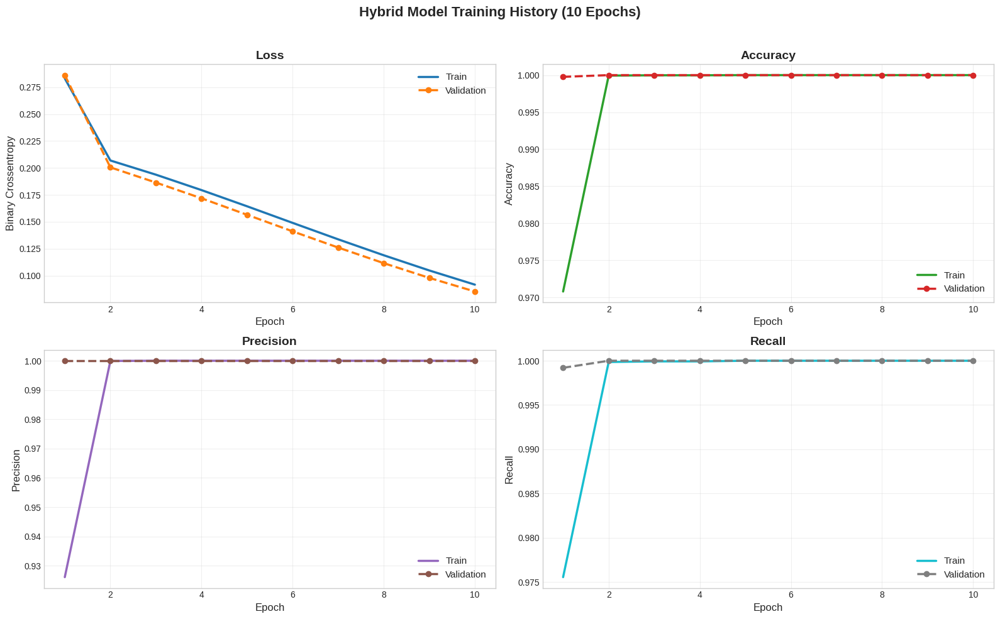

✓ Saved: 01_training_history_hybrid.png


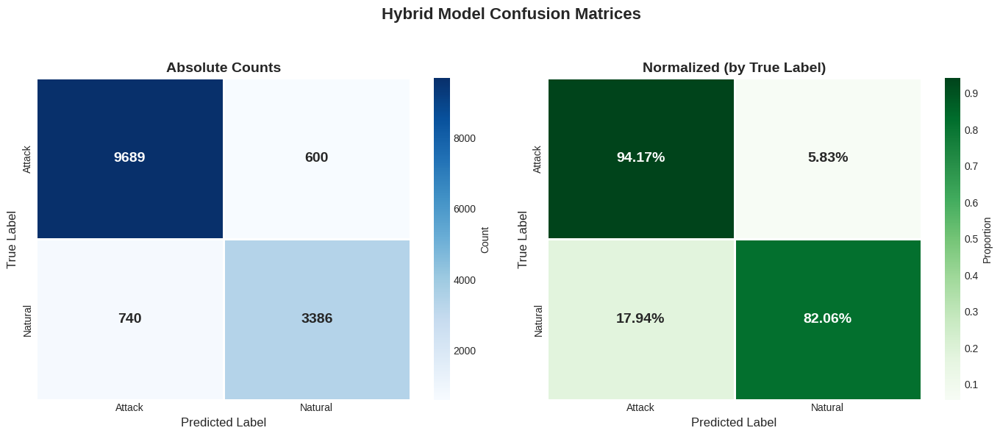

✓ Saved: 02_confusion_matrices_hybrid.png


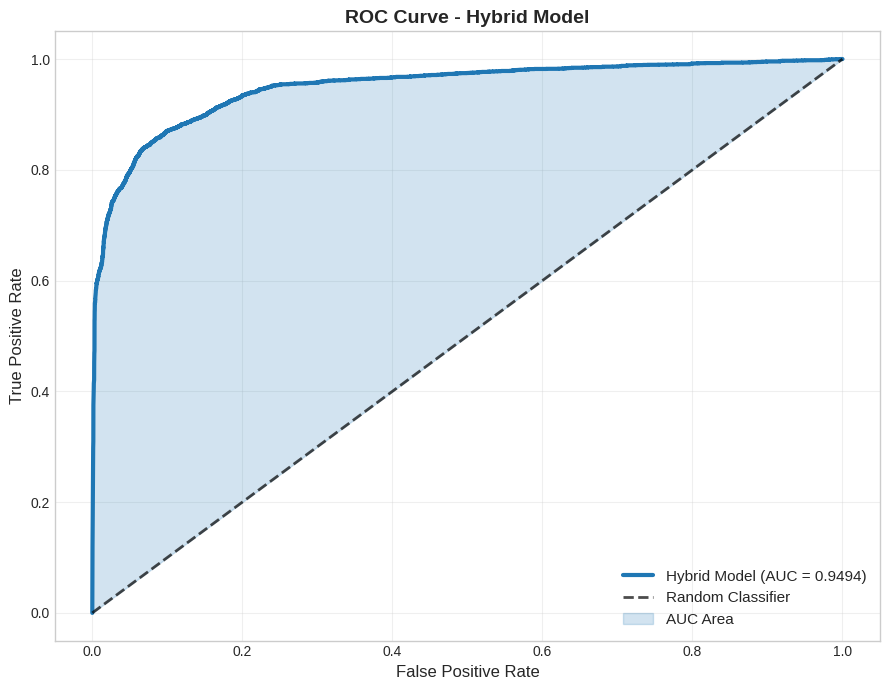

✓ Saved: 03_roc_curve_hybrid.png


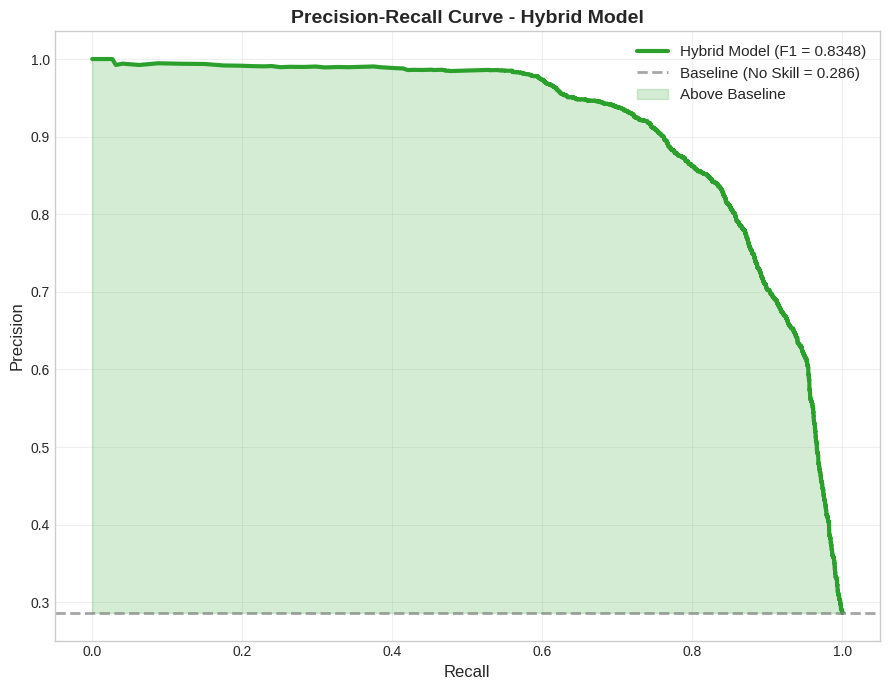

✓ Saved: 04_precision_recall_hybrid.png


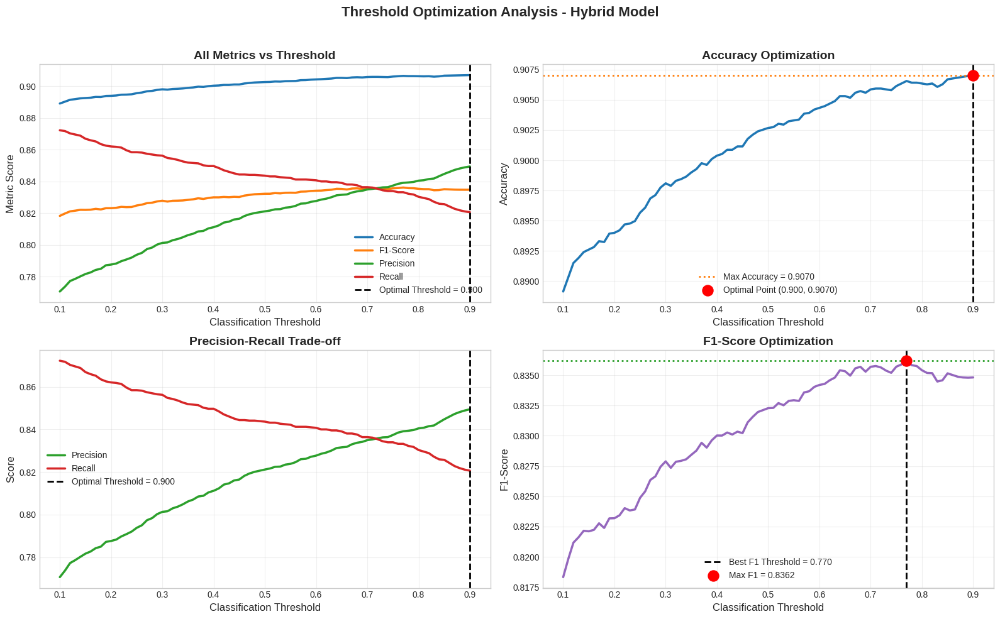

✓ Saved: 05_threshold_optimization_hybrid.png


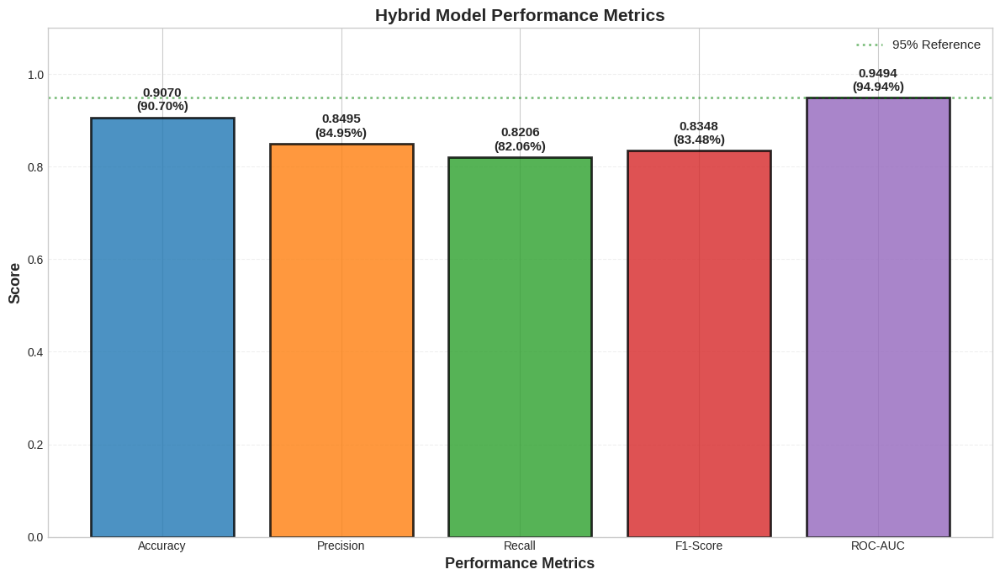

✓ Saved: 06_performance_metrics_hybrid.png


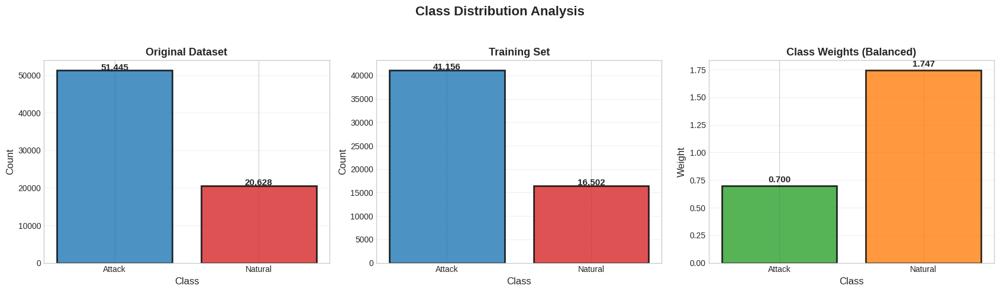

✓ Saved: 07_class_distribution_hybrid.png


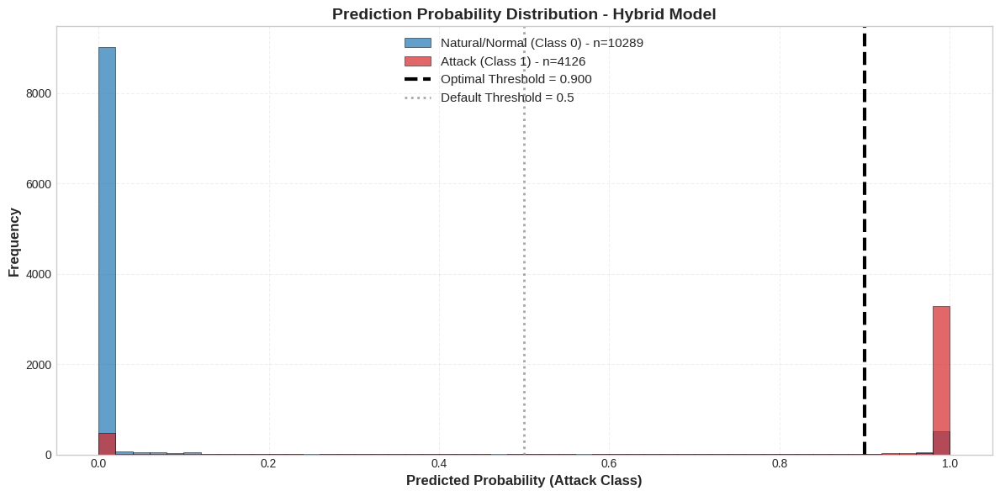

✓ Saved: 08_probability_distribution_hybrid.png


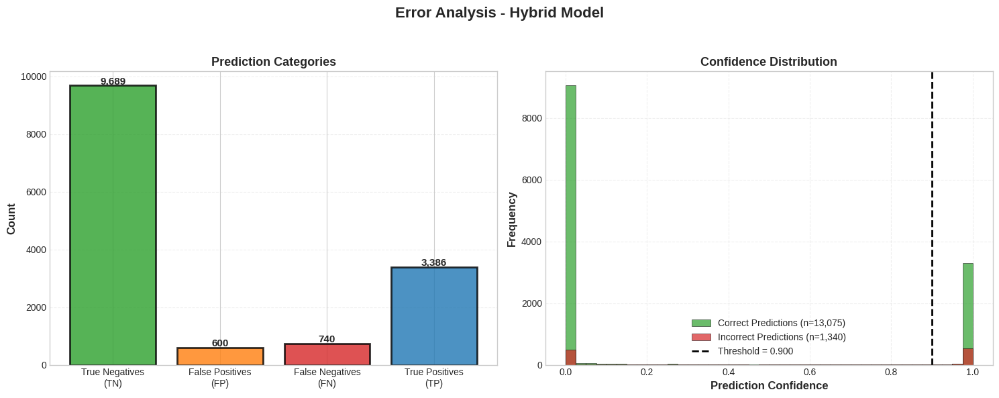

✓ Saved: 09_error_analysis_hybrid.png


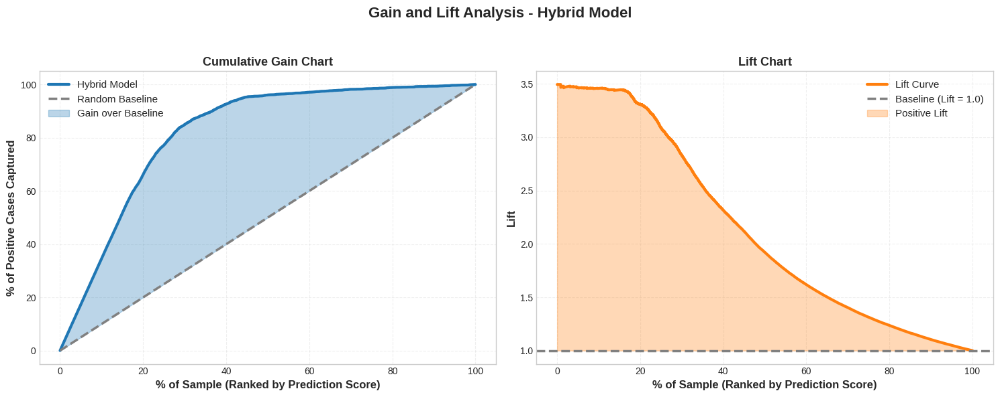

✓ Saved: 10_gain_lift_hybrid.png

FINAL PERFORMANCE SUMMARY - HYBRID MODEL
   Metric    Score Percentage
 Accuracy 0.907041     90.70%
Precision 0.849473     84.95%
   Recall 0.820650     82.06%
 F1-Score 0.834813     83.48%
  ROC-AUC 0.949376     94.94%

Optimal Classification Threshold: 0.9000
Total Test Samples: 14,415
Correctly Classified: 13,075 (90.70%)
Misclassified: 1,340 (9.30%)

✓ ALL VISUALIZATIONS COMPLETE - HYBRID MODEL ONLY!

Generated Figures:
  1. 01_training_history_hybrid.png
  2. 02_confusion_matrices_hybrid.png
  3. 03_roc_curve_hybrid.png
  4. 04_precision_recall_hybrid.png
  5. 05_threshold_optimization_hybrid.png
  6. 06_performance_metrics_hybrid.png
  7. 07_class_distribution_hybrid.png
  8. 08_probability_distribution_hybrid.png
  9. 09_error_analysis_hybrid.png
 10. 10_gain_lift_hybrid.png


In [2]:
# ====================================================================
# 11. VISUALIZATIONS - HYBRID MODEL ONLY
# ====================================================================

print("\n" + "=" * 80)
print("PHASE 5: GENERATING COMPREHENSIVE VISUALIZATIONS - HYBRID MODEL")
print("=" * 80)

plt.rcParams['figure.figsize'] = (10, 7)
plt.rcParams['font.size'] = 10

# 11.1 TRAINING HISTORY
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle('Hybrid Model Training History (10 Epochs)', fontsize=16, fontweight='bold')

epochs = range(1, len(history.history['loss']) + 1)

axes[0, 0].plot(epochs, history.history['loss'], label='Train', color='#1f77b4', linewidth=2.5)
axes[0, 0].plot(epochs, history.history['val_loss'], label='Validation', color='#ff7f0e',
                linewidth=2.5, linestyle='--', marker='o')
axes[0, 0].set_title('Loss', fontsize=14, fontweight='bold')
axes[0, 0].set_xlabel('Epoch', fontsize=12)
axes[0, 0].set_ylabel('Binary Crossentropy', fontsize=12)
axes[0, 0].legend(fontsize=11)
axes[0, 0].grid(alpha=0.3)

axes[0, 1].plot(epochs, history.history['accuracy'], label='Train', color='#2ca02c', linewidth=2.5)
axes[0, 1].plot(epochs, history.history['val_accuracy'], label='Validation', color='#d62728',
                linewidth=2.5, linestyle='--', marker='o')
axes[0, 1].set_title('Accuracy', fontsize=14, fontweight='bold')
axes[0, 1].set_xlabel('Epoch', fontsize=12)
axes[0, 1].set_ylabel('Accuracy', fontsize=12)
axes[0, 1].legend(fontsize=11)
axes[0, 1].grid(alpha=0.3)

axes[1, 0].plot(epochs, history.history['precision'], label='Train', color='#9467bd', linewidth=2.5)
axes[1, 0].plot(epochs, history.history['val_precision'], label='Validation', color='#8c564b',
                linewidth=2.5, linestyle='--', marker='o')
axes[1, 0].set_title('Precision', fontsize=14, fontweight='bold')
axes[1, 0].set_xlabel('Epoch', fontsize=12)
axes[1, 0].set_ylabel('Precision', fontsize=12)
axes[1, 0].legend(fontsize=11)
axes[1, 0].grid(alpha=0.3)

axes[1, 1].plot(epochs, history.history['recall'], label='Train', color='#17becf', linewidth=2.5)
axes[1, 1].plot(epochs, history.history['val_recall'], label='Validation', color='#7f7f7f',
                linewidth=2.5, linestyle='--', marker='o')
axes[1, 1].set_title('Recall', fontsize=14, fontweight='bold')
axes[1, 1].set_xlabel('Epoch', fontsize=12)
axes[1, 1].set_ylabel('Recall', fontsize=12)
axes[1, 1].legend(fontsize=11)
axes[1, 1].grid(alpha=0.3)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig('01_training_history_hybrid.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Saved: 01_training_history_hybrid.png")

# 11.2 CONFUSION MATRICES
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('Hybrid Model Confusion Matrices', fontsize=16, fontweight='bold')

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar_kws={'label': 'Count'},
            xticklabels=encoder.classes_, yticklabels=encoder.classes_,
            ax=axes[0], linewidths=1, linecolor='white', annot_kws={'size': 14, 'weight': 'bold'})
axes[0].set_title('Absolute Counts', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Predicted Label', fontsize=12)
axes[0].set_ylabel('True Label', fontsize=12)

sns.heatmap(cm_norm, annot=True, fmt='.2%', cmap='Greens', cbar_kws={'label': 'Proportion'},
            xticklabels=encoder.classes_, yticklabels=encoder.classes_,
            ax=axes[1], linewidths=1, linecolor='white', annot_kws={'size': 14, 'weight': 'bold'})
axes[1].set_title('Normalized (by True Label)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Predicted Label', fontsize=12)
axes[1].set_ylabel('True Label', fontsize=12)

plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.savefig('02_confusion_matrices_hybrid.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Saved: 02_confusion_matrices_hybrid.png")

# 11.3 ROC CURVE
fpr_hyb, tpr_hyb, thresholds_roc = roc_curve(y_test, y_pred_hybrid_prob)

plt.figure(figsize=(9, 7))
plt.plot(fpr_hyb, tpr_hyb, label=f'Hybrid Model (AUC = {hybrid_roc_auc:.4f})',
         color='#1f77b4', linewidth=3)
plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier', linewidth=2, alpha=0.7)
plt.fill_between(fpr_hyb, fpr_hyb, tpr_hyb, alpha=0.2, color='#1f77b4', label='AUC Area')
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('ROC Curve - Hybrid Model', fontsize=14, fontweight='bold')
plt.legend(loc='lower right', fontsize=11)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('03_roc_curve_hybrid.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Saved: 03_roc_curve_hybrid.png")

# 11.4 PRECISION-RECALL CURVE
prec_hyb, rec_hyb, thresholds_pr = precision_recall_curve(y_test, y_pred_hybrid_prob)
baseline_precision = np.sum(y_test) / len(y_test)

plt.figure(figsize=(9, 7))
plt.plot(rec_hyb, prec_hyb, label=f'Hybrid Model (F1 = {hybrid_f1:.4f})',
         color='#2ca02c', linewidth=3)
plt.axhline(baseline_precision, color='gray', linestyle='--', 
            label=f'Baseline (No Skill = {baseline_precision:.3f})', linewidth=2, alpha=0.7)
plt.fill_between(rec_hyb, baseline_precision, prec_hyb, where=(prec_hyb >= baseline_precision),
                 alpha=0.2, color='#2ca02c', label='Above Baseline')
plt.xlabel('Recall', fontsize=12)
plt.ylabel('Precision', fontsize=12)
plt.title('Precision-Recall Curve - Hybrid Model', fontsize=14, fontweight='bold')
plt.legend(fontsize=11)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('04_precision_recall_hybrid.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Saved: 04_precision_recall_hybrid.png")

# 11.5 THRESHOLD OPTIMIZATION
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle('Threshold Optimization Analysis - Hybrid Model', fontsize=16, fontweight='bold')

axes[0, 0].plot(thresholds, acc_list, label='Accuracy', color='#1f77b4', linewidth=2.5)
axes[0, 0].plot(thresholds, f1_list, label='F1-Score', color='#ff7f0e', linewidth=2.5)
axes[0, 0].plot(thresholds, prec_list, label='Precision', color='#2ca02c', linewidth=2.5)
axes[0, 0].plot(thresholds, rec_list, label='Recall', color='#d62728', linewidth=2.5)
axes[0, 0].axvline(best_th, color='black', linestyle='--', linewidth=2, 
                   label=f'Optimal Threshold = {best_th:.3f}')
axes[0, 0].set_xlabel('Classification Threshold', fontsize=12)
axes[0, 0].set_ylabel('Metric Score', fontsize=12)
axes[0, 0].set_title('All Metrics vs Threshold', fontsize=14, fontweight='bold')
axes[0, 0].legend(fontsize=10)
axes[0, 0].grid(alpha=0.3)

axes[0, 1].plot(thresholds, acc_list, color='#1f77b4', linewidth=2.5)
axes[0, 1].axvline(best_th, color='black', linestyle='--', linewidth=2)
axes[0, 1].axhline(best_acc, color='#ff7f0e', linestyle=':', linewidth=2,
                   label=f'Max Accuracy = {best_acc:.4f}')
axes[0, 1].scatter([best_th], [best_acc], color='red', s=150, zorder=5, 
                   label=f'Optimal Point ({best_th:.3f}, {best_acc:.4f})')
axes[0, 1].set_xlabel('Classification Threshold', fontsize=12)
axes[0, 1].set_ylabel('Accuracy', fontsize=12)
axes[0, 1].set_title('Accuracy Optimization', fontsize=14, fontweight='bold')
axes[0, 1].legend(fontsize=10)
axes[0, 1].grid(alpha=0.3)

axes[1, 0].plot(thresholds, prec_list, label='Precision', color='#2ca02c', linewidth=2.5)
axes[1, 0].plot(thresholds, rec_list, label='Recall', color='#d62728', linewidth=2.5)
axes[1, 0].axvline(best_th, color='black', linestyle='--', linewidth=2,
                   label=f'Optimal Threshold = {best_th:.3f}')
axes[1, 0].set_xlabel('Classification Threshold', fontsize=12)
axes[1, 0].set_ylabel('Score', fontsize=12)
axes[1, 0].set_title('Precision-Recall Trade-off', fontsize=14, fontweight='bold')
axes[1, 0].legend(fontsize=10)
axes[1, 0].grid(alpha=0.3)

best_f1_idx = np.argmax(f1_list)
best_f1_th = thresholds[best_f1_idx]
best_f1_val = f1_list[best_f1_idx]

axes[1, 1].plot(thresholds, f1_list, color='#9467bd', linewidth=2.5)
axes[1, 1].axvline(best_f1_th, color='black', linestyle='--', linewidth=2,
                   label=f'Best F1 Threshold = {best_f1_th:.3f}')
axes[1, 1].axhline(best_f1_val, color='#2ca02c', linestyle=':', linewidth=2)
axes[1, 1].scatter([best_f1_th], [best_f1_val], color='red', s=150, zorder=5,
                   label=f'Max F1 = {best_f1_val:.4f}')
axes[1, 1].set_xlabel('Classification Threshold', fontsize=12)
axes[1, 1].set_ylabel('F1-Score', fontsize=12)
axes[1, 1].set_title('F1-Score Optimization', fontsize=14, fontweight='bold')
axes[1, 1].legend(fontsize=10)
axes[1, 1].grid(alpha=0.3)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig('05_threshold_optimization_hybrid.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Saved: 05_threshold_optimization_hybrid.png")

# 11.6 PERFORMANCE METRICS BAR CHART
metrics_names = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']
metrics_values = [hybrid_accuracy, hybrid_precision, hybrid_recall, hybrid_f1, hybrid_roc_auc]
colors_bar = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']

fig, ax = plt.subplots(figsize=(12, 7))
bars = ax.bar(metrics_names, metrics_values, color=colors_bar, edgecolor='black', linewidth=2, alpha=0.8)

for i, (bar, val) in enumerate(zip(bars, metrics_values)):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2., height + 0.01,
            f'{val:.4f}\n({val*100:.2f}%)', ha='center', va='bottom', 
            fontsize=11, fontweight='bold')

ax.set_ylabel('Score', fontsize=13, fontweight='bold')
ax.set_xlabel('Performance Metrics', fontsize=13, fontweight='bold')
ax.set_title('Hybrid Model Performance Metrics', fontsize=15, fontweight='bold')
ax.set_ylim([0, 1.1])
ax.grid(axis='y', alpha=0.3, linestyle='--')
ax.axhline(0.95, color='green', linestyle=':', linewidth=2, alpha=0.5, label='95% Reference')
ax.legend(fontsize=11)

plt.tight_layout()
plt.savefig('06_performance_metrics_hybrid.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Saved: 06_performance_metrics_hybrid.png")

# 11.7 CLASS DISTRIBUTION WITH WEIGHTS
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
fig.suptitle('Class Distribution Analysis', fontsize=16, fontweight='bold')

class_counts = pd.Series(y_encoded).value_counts().sort_index()
bars1 = axes[0].bar(encoder.classes_, class_counts.values,
                    color=['#1f77b4', '#d62728'], edgecolor='black', linewidth=2, alpha=0.8)
axes[0].set_title('Original Dataset', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Class', fontsize=12)
axes[0].set_ylabel('Count', fontsize=12)
axes[0].grid(axis='y', alpha=0.3)
for i, (bar, v) in enumerate(zip(bars1, class_counts.values)):
    axes[0].text(bar.get_x() + bar.get_width() / 2., v + 100, 
                 f'{v:,}', ha='center', fontsize=11, fontweight='bold')

train_counts = pd.Series(y_train_res).value_counts().sort_index()
bars2 = axes[1].bar(encoder.classes_, train_counts.values,
                    color=['#1f77b4', '#d62728'], edgecolor='black', linewidth=2, alpha=0.8)
axes[1].set_title('Training Set', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Class', fontsize=12)
axes[1].set_ylabel('Count', fontsize=12)
axes[1].grid(axis='y', alpha=0.3)
for i, (bar, v) in enumerate(zip(bars2, train_counts.values)):
    axes[1].text(bar.get_x() + bar.get_width() / 2., v + 100,
                 f'{v:,}', ha='center', fontsize=11, fontweight='bold')

weight_values = [class_weights[i] for i in sorted(class_weights.keys())]
bars3 = axes[2].bar(encoder.classes_, weight_values,
                    color=['#2ca02c', '#ff7f0e'], edgecolor='black', linewidth=2, alpha=0.8)
axes[2].set_title('Class Weights (Balanced)', fontsize=13, fontweight='bold')
axes[2].set_xlabel('Class', fontsize=12)
axes[2].set_ylabel('Weight', fontsize=12)
axes[2].grid(axis='y', alpha=0.3)
for i, (bar, v) in enumerate(zip(bars3, weight_values)):
    axes[2].text(bar.get_x() + bar.get_width() / 2., v + 0.03,
                 f'{v:.3f}', ha='center', fontsize=11, fontweight='bold')

plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.savefig('07_class_distribution_hybrid.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Saved: 07_class_distribution_hybrid.png")

# 11.8 PREDICTION PROBABILITY DISTRIBUTIONS
fig, ax = plt.subplots(figsize=(12, 6))

ax.hist(y_pred_hybrid_prob[y_test == 0], bins=50, alpha=0.7,
        label=f'Natural/Normal (Class 0) - n={np.sum(y_test==0)}', 
        color='#1f77b4', edgecolor='black', linewidth=0.5)
ax.hist(y_pred_hybrid_prob[y_test == 1], bins=50, alpha=0.7,
        label=f'Attack (Class 1) - n={np.sum(y_test==1)}', 
        color='#d62728', edgecolor='black', linewidth=0.5)
ax.axvline(best_th, color='black', linestyle='--', linewidth=3,
           label=f'Optimal Threshold = {best_th:.3f}')
ax.axvline(0.5, color='gray', linestyle=':', linewidth=2, alpha=0.7,
           label='Default Threshold = 0.5')

ax.set_xlabel('Predicted Probability (Attack Class)', fontsize=12, fontweight='bold')
ax.set_ylabel('Frequency', fontsize=12, fontweight='bold')
ax.set_title('Prediction Probability Distribution - Hybrid Model', fontsize=14, fontweight='bold')
ax.legend(fontsize=11, loc='upper center')
ax.grid(alpha=0.3, linestyle='--')

plt.tight_layout()
plt.savefig('08_probability_distribution_hybrid.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Saved: 08_probability_distribution_hybrid.png")

# 11.9 ERROR ANALYSIS
misclassified_indices = np.where(y_pred_hybrid != y_test)[0]
correct_indices = np.where(y_pred_hybrid == y_test)[0]

error_stats = {
    'True Negatives\n(TN)': np.sum((y_pred_hybrid == 0) & (y_test == 0)),
    'False Positives\n(FP)': np.sum((y_pred_hybrid == 1) & (y_test == 0)),
    'False Negatives\n(FN)': np.sum((y_pred_hybrid == 0) & (y_test == 1)),
    'True Positives\n(TP)': np.sum((y_pred_hybrid == 1) & (y_test == 1))
}

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
fig.suptitle('Error Analysis - Hybrid Model', fontsize=16, fontweight='bold')

bars = axes[0].bar(error_stats.keys(), error_stats.values(),
                   color=['#2ca02c', '#ff7f0e', '#d62728', '#1f77b4'],
                   edgecolor='black', linewidth=2, alpha=0.8)
axes[0].set_ylabel('Count', fontsize=12, fontweight='bold')
axes[0].set_title('Prediction Categories', fontsize=13, fontweight='bold')
axes[0].tick_params(axis='x', rotation=0, labelsize=10)
axes[0].grid(axis='y', alpha=0.3, linestyle='--')
for i, (bar, (k, v)) in enumerate(zip(bars, error_stats.items())):
    axes[0].text(bar.get_x() + bar.get_width() / 2., v + 50,
                 f'{v:,}', ha='center', fontsize=11, fontweight='bold')

correct_conf = y_pred_hybrid_prob[correct_indices]
incorrect_conf = y_pred_hybrid_prob[misclassified_indices]

axes[1].hist(correct_conf, bins=40, alpha=0.7, 
             label=f'Correct Predictions (n={len(correct_indices):,})',
             color='#2ca02c', edgecolor='black', linewidth=0.5)
axes[1].hist(incorrect_conf, bins=40, alpha=0.7, 
             label=f'Incorrect Predictions (n={len(misclassified_indices):,})',
             color='#d62728', edgecolor='black', linewidth=0.5)
axes[1].axvline(best_th, color='black', linestyle='--', linewidth=2,
                label=f'Threshold = {best_th:.3f}')
axes[1].set_xlabel('Prediction Confidence', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Frequency', fontsize=12, fontweight='bold')
axes[1].set_title('Confidence Distribution', fontsize=13, fontweight='bold')
axes[1].legend(fontsize=10)
axes[1].grid(alpha=0.3, linestyle='--')

plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.savefig('09_error_analysis_hybrid.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Saved: 09_error_analysis_hybrid.png")

# 11.10 CUMULATIVE GAIN AND LIFT ANALYSIS
sorted_indices = np.argsort(y_pred_hybrid_prob)[::-1]
y_test_sorted = y_test[sorted_indices]

cumulative_gains = np.cumsum(y_test_sorted) / np.sum(y_test_sorted) * 100
sample_percentage = np.arange(1, len(y_test_sorted) + 1) / len(y_test_sorted) * 100
baseline = sample_percentage
lift = cumulative_gains / sample_percentage

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
fig.suptitle('Gain and Lift Analysis - Hybrid Model', fontsize=16, fontweight='bold')

axes[0].plot(sample_percentage, cumulative_gains, color='#1f77b4', linewidth=3,
             label='Hybrid Model')
axes[0].plot(sample_percentage, baseline, color='gray', linestyle='--', linewidth=2.5,
             label='Random Baseline')
axes[0].fill_between(sample_percentage, baseline, cumulative_gains,
                     color='#1f77b4', alpha=0.3, label='Gain over Baseline')
axes[0].set_xlabel('% of Sample (Ranked by Prediction Score)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('% of Positive Cases Captured', fontsize=12, fontweight='bold')
axes[0].set_title('Cumulative Gain Chart', fontsize=13, fontweight='bold')
axes[0].legend(fontsize=11)
axes[0].grid(alpha=0.3, linestyle='--')

axes[1].plot(sample_percentage, lift, color='#ff7f0e', linewidth=3,
             label='Lift Curve')
axes[1].axhline(1, color='gray', linestyle='--', linewidth=2.5,
                label='Baseline (Lift = 1.0)')
axes[1].fill_between(sample_percentage, 1, lift, where=(lift >= 1),
                     color='#ff7f0e', alpha=0.3, label='Positive Lift')
axes[1].set_xlabel('% of Sample (Ranked by Prediction Score)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Lift', fontsize=12, fontweight='bold')
axes[1].set_title('Lift Chart', fontsize=13, fontweight='bold')
axes[1].legend(fontsize=11)
axes[1].grid(alpha=0.3, linestyle='--')

plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.savefig('10_gain_lift_hybrid.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Saved: 10_gain_lift_hybrid.png")

# 11.11 LEARNING RATE SCHEDULE
if 'lr' in history.history:
    plt.figure(figsize=(10, 6))
    plt.plot(range(1, len(history.history['lr']) + 1), history.history['lr'], 
             marker='o', markersize=8, color='#9467bd', linewidth=2.5, linestyle='-')
    plt.xlabel('Epoch', fontsize=12, fontweight='bold')
    plt.ylabel('Learning Rate', fontsize=12, fontweight='bold')
    plt.yscale('log')
    plt.title('Learning Rate Schedule (ReduceLROnPlateau)', fontsize=14, fontweight='bold')
    plt.grid(alpha=0.3, linestyle='--', which='both')
    plt.tight_layout()
    plt.savefig('11_learning_rate_schedule_hybrid.png', dpi=300, bbox_inches='tight')
    plt.show()
    print("✓ Saved: 11_learning_rate_schedule_hybrid.png")

# ====================================================================
# SUMMARY TABLE
# ====================================================================

print("\n" + "=" * 80)
print("FINAL PERFORMANCE SUMMARY - HYBRID MODEL")
print("=" * 80)

summary_df = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC'],
    'Score': [hybrid_accuracy, hybrid_precision, hybrid_recall, hybrid_f1, hybrid_roc_auc],
    'Percentage': [f'{hybrid_accuracy*100:.2f}%', f'{hybrid_precision*100:.2f}%', 
                   f'{hybrid_recall*100:.2f}%', f'{hybrid_f1*100:.2f}%', 
                   f'{hybrid_roc_auc*100:.2f}%']
})

print(summary_df.to_string(index=False))
print(f"\nOptimal Classification Threshold: {best_th:.4f}")
print(f"Total Test Samples: {len(y_test):,}")
print(f"Correctly Classified: {len(correct_indices):,} ({len(correct_indices)/len(y_test)*100:.2f}%)")
print(f"Misclassified: {len(misclassified_indices):,} ({len(misclassified_indices)/len(y_test)*100:.2f}%)")

print("\n" + "=" * 80)
print("✓ ALL VISUALIZATIONS COMPLETE - HYBRID MODEL ONLY!")
print("=" * 80)
print("\nGenerated Figures:")
print("  1. 01_training_history_hybrid.png")
print("  2. 02_confusion_matrices_hybrid.png")
print("  3. 03_roc_curve_hybrid.png")
print("  4. 04_precision_recall_hybrid.png")
print("  5. 05_threshold_optimization_hybrid.png")
print("  6. 06_performance_metrics_hybrid.png")
print("  7. 07_class_distribution_hybrid.png")
print("  8. 08_probability_distribution_hybrid.png")
print("  9. 09_error_analysis_hybrid.png")
print(" 10. 10_gain_lift_hybrid.png")
if 'lr' in history.history:
    print(" 11. 11_learning_rate_schedule_hybrid.png")


PHASE 5: GENERATING PUBLICATION-READY VISUALIZATIONS - HYBRID MODEL


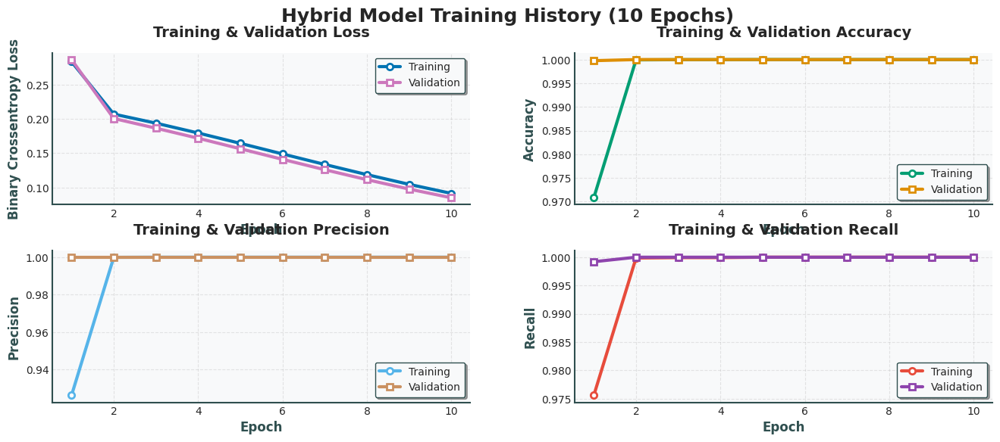

✓ Saved: 01_training_history_hybrid.png


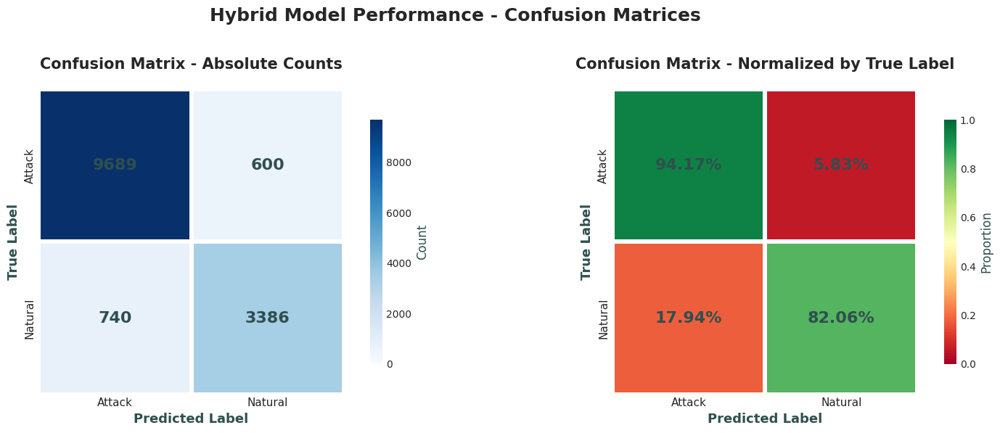

✓ Saved: 02_confusion_matrices_hybrid.png


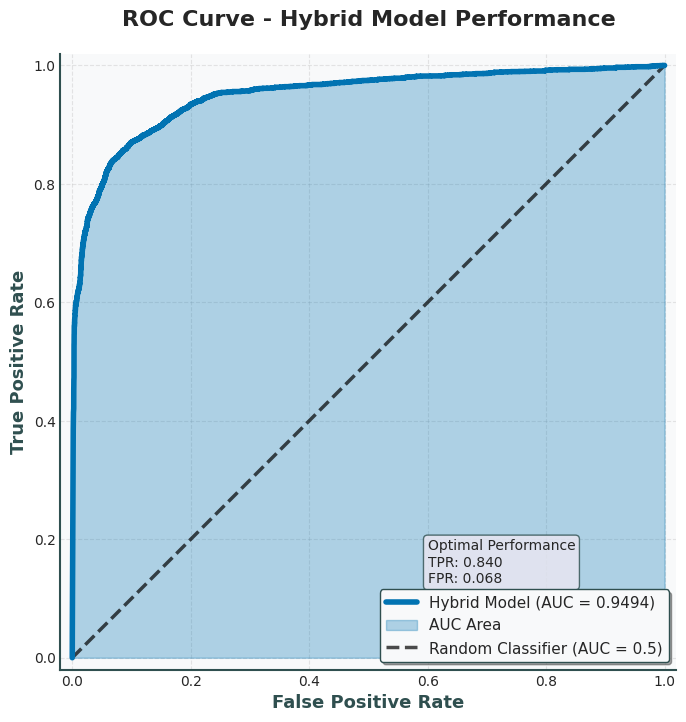

✓ Saved: 03_roc_curve_hybrid.png


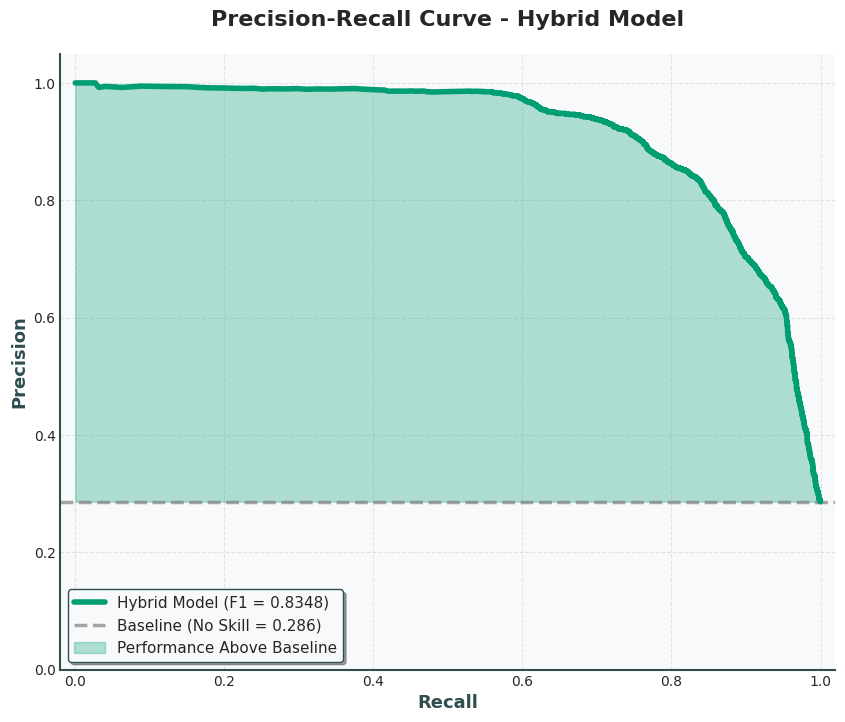

✓ Saved: 04_precision_recall_hybrid.png


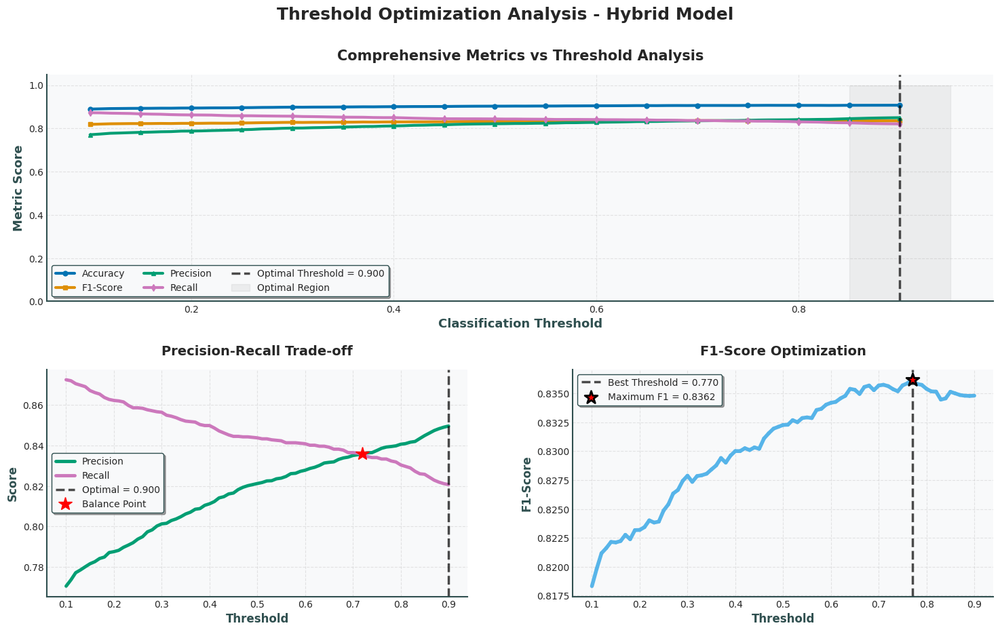

✓ Saved: 05_threshold_optimization_hybrid.png


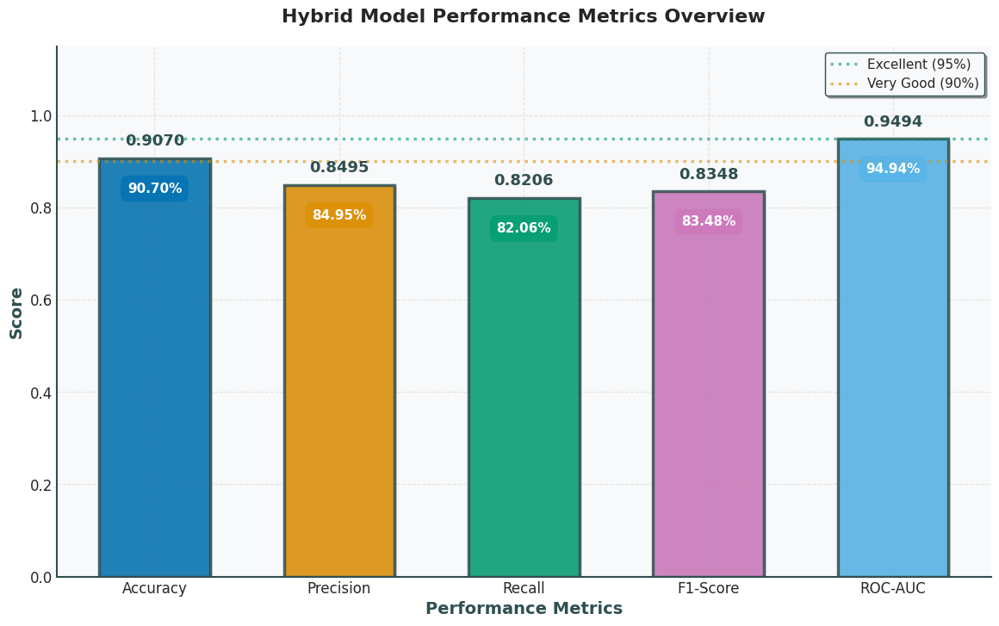

✓ Saved: 06_performance_metrics_hybrid.png


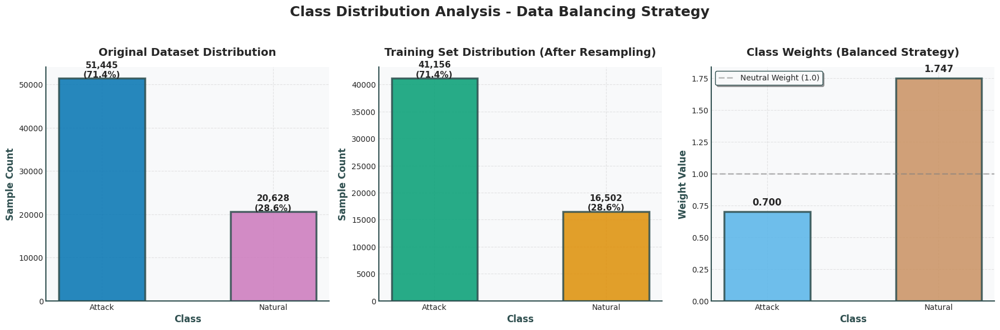

✓ Saved: 07_class_distribution_hybrid.png


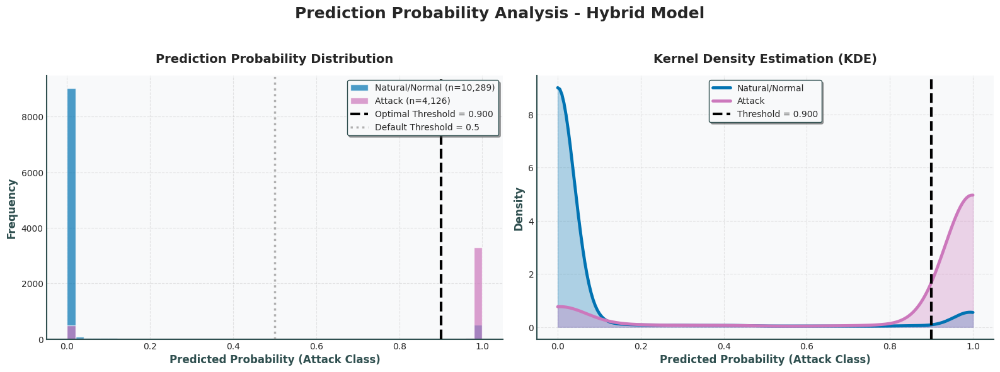

✓ Saved: 08_probability_distribution_hybrid.png


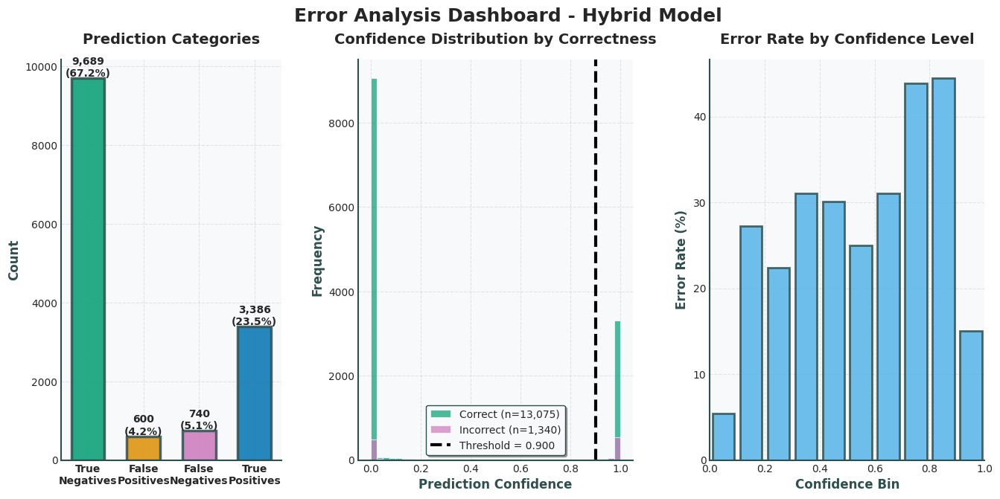

✓ Saved: 09_error_analysis_hybrid.png


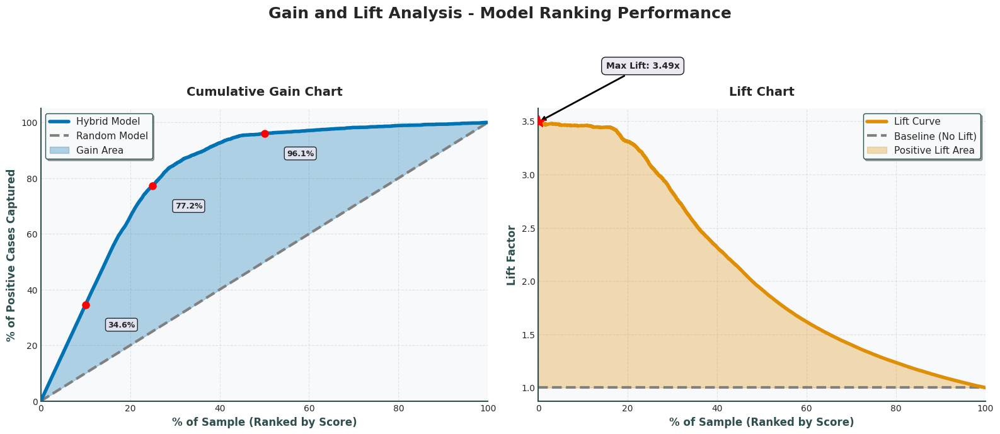

✓ Saved: 10_gain_lift_hybrid.png

FINAL PERFORMANCE SUMMARY - HYBRID MODEL
   Metric    Score Percentage
 Accuracy 0.907041     90.70%
Precision 0.849473     84.95%
   Recall 0.820650     82.06%
 F1-Score 0.834813     83.48%
  ROC-AUC 0.949376     94.94%

Optimal Classification Threshold: 0.9000
Total Test Samples: 14,415
Correctly Classified: 13,075 (90.70%)
Misclassified: 1,340 (9.30%)

✓ ALL PUBLICATION-READY VISUALIZATIONS COMPLETE!

Generated Professional Figures:
  1. 01_training_history_hybrid.png - Modern 4-panel training metrics
  2. 02_confusion_matrices_hybrid.png - Enhanced heatmaps with gradients
  3. 03_roc_curve_hybrid.png - Professional ROC with annotations
  4. 04_precision_recall_hybrid.png - Modern PR curve design
  5. 05_threshold_optimization_hybrid.png - Comprehensive dashboard
  6. 06_performance_metrics_hybrid.png - Gradient bar chart with shadows
  7. 07_class_distribution_hybrid.png - Enhanced 3-panel comparison
  8. 08_probability_distribution_hybrid.png - Hi

In [3]:
# ====================================================================
# 11. ENHANCED VISUALIZATIONS - HYBRID MODEL (MODERN DESIGN)
# ====================================================================

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from matplotlib import patheffects
from matplotlib.patches import Rectangle
import warnings
warnings.filterwarnings('ignore')

print("\n" + "=" * 80)
print("PHASE 5: GENERATING PUBLICATION-READY VISUALIZATIONS - HYBRID MODEL")
print("=" * 80)

# ====================================================================
# MODERN STYLE CONFIGURATION
# ====================================================================

# Use seaborn-v0_8 style with custom modifications
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

# Custom color palette (colorblind-friendly)
COLORS = {
    'primary': '#0173B2',      # Blue
    'secondary': '#DE8F05',    # Orange
    'success': '#029E73',      # Green
    'danger': '#CC78BC',       # Pink
    'warning': '#CA9161',      # Brown
    'info': '#56B4E9',         # Sky Blue
    'dark': '#2F4F4F',         # Dark Slate
    'light': '#ECE7F2'         # Light Purple
}

# Global parameters
plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor': '#F8F9FA',
    'axes.edgecolor': '#2F4F4F',
    'axes.labelcolor': '#2F4F4F',
    'axes.linewidth': 1.5,
    'axes.grid': True,
    'grid.alpha': 0.3,
    'grid.color': '#B0B0B0',
    'grid.linestyle': '--',
    'grid.linewidth': 0.8,
    'font.family': 'sans-serif',
    'font.sans-serif': ['DejaVu Sans', 'Arial', 'Helvetica'],
    'font.size': 11,
    'axes.titlesize': 14,
    'axes.labelsize': 12,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
    'legend.framealpha': 0.9,
    'legend.edgecolor': '#2F4F4F',
    'lines.linewidth': 2.5,
    'lines.markersize': 8,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'savefig.facecolor': 'white'
})

# ====================================================================
# 11.1 TRAINING HISTORY - MODERN DUAL PANEL DESIGN
# ====================================================================

fig = plt.figure(figsize=(16, 6))
gs = fig.add_gridspec(2, 2, hspace=0.3, wspace=0.25, 
                      height_ratios=[1, 1], width_ratios=[1, 1])

epochs = range(1, len(history.history['loss']) + 1)

# Loss subplot
ax1 = fig.add_subplot(gs[0, 0])
line1 = ax1.plot(epochs, history.history['loss'], 
                 label='Training', color=COLORS['primary'], 
                 linewidth=3, marker='o', markersize=6, 
                 markerfacecolor='white', markeredgewidth=2)
line2 = ax1.plot(epochs, history.history['val_loss'], 
                 label='Validation', color=COLORS['danger'], 
                 linewidth=3, marker='s', markersize=6,
                 markerfacecolor='white', markeredgewidth=2)
ax1.set_xlabel('Epoch', fontweight='bold')
ax1.set_ylabel('Binary Crossentropy Loss', fontweight='bold')
ax1.set_title('Training & Validation Loss', fontweight='bold', pad=15)
ax1.legend(loc='upper right', frameon=True, shadow=True)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

# Accuracy subplot
ax2 = fig.add_subplot(gs[0, 1])
ax2.plot(epochs, history.history['accuracy'], 
         label='Training', color=COLORS['success'], 
         linewidth=3, marker='o', markersize=6,
         markerfacecolor='white', markeredgewidth=2)
ax2.plot(epochs, history.history['val_accuracy'], 
         label='Validation', color=COLORS['secondary'], 
         linewidth=3, marker='s', markersize=6,
         markerfacecolor='white', markeredgewidth=2)
ax2.set_xlabel('Epoch', fontweight='bold')
ax2.set_ylabel('Accuracy', fontweight='bold')
ax2.set_title('Training & Validation Accuracy', fontweight='bold', pad=15)
ax2.legend(loc='lower right', frameon=True, shadow=True)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

# Precision subplot
ax3 = fig.add_subplot(gs[1, 0])
ax3.plot(epochs, history.history['precision'], 
         label='Training', color=COLORS['info'], 
         linewidth=3, marker='o', markersize=6,
         markerfacecolor='white', markeredgewidth=2)
ax3.plot(epochs, history.history['val_precision'], 
         label='Validation', color=COLORS['warning'], 
         linewidth=3, marker='s', markersize=6,
         markerfacecolor='white', markeredgewidth=2)
ax3.set_xlabel('Epoch', fontweight='bold')
ax3.set_ylabel('Precision', fontweight='bold')
ax3.set_title('Training & Validation Precision', fontweight='bold', pad=15)
ax3.legend(loc='lower right', frameon=True, shadow=True)
ax3.spines['top'].set_visible(False)
ax3.spines['right'].set_visible(False)

# Recall subplot
ax4 = fig.add_subplot(gs[1, 1])
ax4.plot(epochs, history.history['recall'], 
         label='Training', color='#E74C3C', 
         linewidth=3, marker='o', markersize=6,
         markerfacecolor='white', markeredgewidth=2)
ax4.plot(epochs, history.history['val_recall'], 
         label='Validation', color='#8E44AD', 
         linewidth=3, marker='s', markersize=6,
         markerfacecolor='white', markeredgewidth=2)
ax4.set_xlabel('Epoch', fontweight='bold')
ax4.set_ylabel('Recall', fontweight='bold')
ax4.set_title('Training & Validation Recall', fontweight='bold', pad=15)
ax4.legend(loc='lower right', frameon=True, shadow=True)
ax4.spines['top'].set_visible(False)
ax4.spines['right'].set_visible(False)

fig.suptitle('Hybrid Model Training History (10 Epochs)', 
             fontsize=18, fontweight='bold', y=0.98)

plt.savefig('01_training_history_hybrid.png', dpi=300, bbox_inches='tight', 
            facecolor='white', edgecolor='none')
plt.show()
print("✓ Saved: 01_training_history_hybrid.png")

# ====================================================================
# 11.2 CONFUSION MATRICES - ENHANCED HEATMAP DESIGN
# ====================================================================

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.patch.set_facecolor('white')

# Absolute counts heatmap
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=encoder.classes_, yticklabels=encoder.classes_,
            ax=axes[0], cbar_kws={'label': 'Count', 'shrink': 0.8},
            linewidths=3, linecolor='white', 
            annot_kws={'size': 16, 'weight': 'bold', 'color': '#2F4F4F'},
            square=True, vmin=0)
axes[0].set_title('Confusion Matrix - Absolute Counts', 
                  fontsize=15, fontweight='bold', pad=20)
axes[0].set_xlabel('Predicted Label', fontsize=13, fontweight='bold')
axes[0].set_ylabel('True Label', fontsize=13, fontweight='bold')
axes[0].tick_params(labelsize=11)

# Normalized heatmap
sns.heatmap(cm_norm, annot=True, fmt='.2%', cmap='RdYlGn', 
            xticklabels=encoder.classes_, yticklabels=encoder.classes_,
            ax=axes[1], cbar_kws={'label': 'Proportion', 'shrink': 0.8},
            linewidths=3, linecolor='white',
            annot_kws={'size': 16, 'weight': 'bold', 'color': '#2F4F4F'},
            square=True, vmin=0, vmax=1, center=0.5)
axes[1].set_title('Confusion Matrix - Normalized by True Label', 
                  fontsize=15, fontweight='bold', pad=20)
axes[1].set_xlabel('Predicted Label', fontsize=13, fontweight='bold')
axes[1].set_ylabel('True Label', fontsize=13, fontweight='bold')
axes[1].tick_params(labelsize=11)

fig.suptitle('Hybrid Model Performance - Confusion Matrices', 
             fontsize=18, fontweight='bold', y=0.98)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig('02_confusion_matrices_hybrid.png', dpi=300, bbox_inches='tight',
            facecolor='white', edgecolor='none')
plt.show()
print("✓ Saved: 02_confusion_matrices_hybrid.png")

# ====================================================================
# 11.3 ROC CURVE - GRADIENT FILL DESIGN
# ====================================================================

fpr_hyb, tpr_hyb, thresholds_roc = roc_curve(y_test, y_pred_hybrid_prob)

fig, ax = plt.subplots(figsize=(10, 8))
fig.patch.set_facecolor('white')

# Main ROC curve with gradient fill
ax.plot(fpr_hyb, tpr_hyb, 
        label=f'Hybrid Model (AUC = {hybrid_roc_auc:.4f})',
        color=COLORS['primary'], linewidth=4, zorder=3)

# Fill area under curve with transparency
ax.fill_between(fpr_hyb, 0, tpr_hyb, alpha=0.3, 
                color=COLORS['primary'], label='AUC Area')

# Random classifier diagonal
ax.plot([0, 1], [0, 1], 'k--', label='Random Classifier (AUC = 0.5)', 
        linewidth=2.5, alpha=0.7, zorder=2)

# Styling
ax.set_xlabel('False Positive Rate', fontsize=13, fontweight='bold')
ax.set_ylabel('True Positive Rate', fontsize=13, fontweight='bold')
ax.set_title('ROC Curve - Hybrid Model Performance', 
             fontsize=16, fontweight='bold', pad=20)
ax.legend(loc='lower right', fontsize=11, frameon=True, shadow=True)
ax.set_xlim([-0.02, 1.02])
ax.set_ylim([-0.02, 1.02])
ax.set_aspect('equal')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(True, alpha=0.3, linestyle='--', linewidth=0.8)

# Add text annotation
textstr = f'Optimal Performance\nTPR: {tpr_hyb[np.argmax(tpr_hyb - fpr_hyb)]:.3f}\nFPR: {fpr_hyb[np.argmax(tpr_hyb - fpr_hyb)]:.3f}'
props = dict(boxstyle='round', facecolor=COLORS['light'], alpha=0.8, edgecolor=COLORS['dark'])
ax.text(0.6, 0.2, textstr, fontsize=10, verticalalignment='top', bbox=props)

plt.savefig('03_roc_curve_hybrid.png', dpi=300, bbox_inches='tight',
            facecolor='white', edgecolor='none')
plt.show()
print("✓ Saved: 03_roc_curve_hybrid.png")

# ====================================================================
# 11.4 PRECISION-RECALL CURVE - MODERN DESIGN
# ====================================================================

prec_hyb, rec_hyb, thresholds_pr = precision_recall_curve(y_test, y_pred_hybrid_prob)
baseline_precision = np.sum(y_test) / len(y_test)

fig, ax = plt.subplots(figsize=(10, 8))
fig.patch.set_facecolor('white')

# Main PR curve
ax.plot(rec_hyb, prec_hyb, 
        label=f'Hybrid Model (F1 = {hybrid_f1:.4f})',
        color=COLORS['success'], linewidth=4, zorder=3)

# Baseline
ax.axhline(baseline_precision, color='gray', linestyle='--', 
           label=f'Baseline (No Skill = {baseline_precision:.3f})', 
           linewidth=2.5, alpha=0.7, zorder=2)

# Fill above baseline
ax.fill_between(rec_hyb, baseline_precision, prec_hyb, 
                where=(prec_hyb >= baseline_precision),
                alpha=0.3, color=COLORS['success'], 
                label='Performance Above Baseline', interpolate=True)

# Styling
ax.set_xlabel('Recall', fontsize=13, fontweight='bold')
ax.set_ylabel('Precision', fontsize=13, fontweight='bold')
ax.set_title('Precision-Recall Curve - Hybrid Model', 
             fontsize=16, fontweight='bold', pad=20)
ax.legend(loc='best', fontsize=11, frameon=True, shadow=True)
ax.set_xlim([-0.02, 1.02])
ax.set_ylim([0, 1.05])
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(True, alpha=0.3, linestyle='--', linewidth=0.8)

plt.savefig('04_precision_recall_hybrid.png', dpi=300, bbox_inches='tight',
            facecolor='white', edgecolor='none')
plt.show()
print("✓ Saved: 04_precision_recall_hybrid.png")

# ====================================================================
# 11.5 THRESHOLD OPTIMIZATION - MODERN DASHBOARD
# ====================================================================

fig = plt.figure(figsize=(18, 10))
gs = fig.add_gridspec(2, 2, hspace=0.3, wspace=0.25)

# All metrics
ax1 = fig.add_subplot(gs[0, :])
ax1.plot(thresholds, acc_list, label='Accuracy', 
         color=COLORS['primary'], linewidth=3, marker='o', 
         markersize=5, markevery=5)
ax1.plot(thresholds, f1_list, label='F1-Score', 
         color=COLORS['secondary'], linewidth=3, marker='s', 
         markersize=5, markevery=5)
ax1.plot(thresholds, prec_list, label='Precision', 
         color=COLORS['success'], linewidth=3, marker='^', 
         markersize=5, markevery=5)
ax1.plot(thresholds, rec_list, label='Recall', 
         color=COLORS['danger'], linewidth=3, marker='d', 
         markersize=5, markevery=5)
ax1.axvline(best_th, color='black', linestyle='--', linewidth=2.5, 
            label=f'Optimal Threshold = {best_th:.3f}', alpha=0.7)
ax1.fill_between([best_th-0.05, best_th+0.05], 0, 1, 
                 alpha=0.1, color='gray', label='Optimal Region')
ax1.set_xlabel('Classification Threshold', fontsize=13, fontweight='bold')
ax1.set_ylabel('Metric Score', fontsize=13, fontweight='bold')
ax1.set_title('Comprehensive Metrics vs Threshold Analysis', 
              fontsize=15, fontweight='bold', pad=15)
ax1.legend(loc='best', fontsize=10, ncol=3, frameon=True, shadow=True)
ax1.set_ylim([0, 1.05])
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

# Precision-Recall Trade-off
ax2 = fig.add_subplot(gs[1, 0])
ax2.plot(thresholds, prec_list, label='Precision', 
         color=COLORS['success'], linewidth=3.5)
ax2.plot(thresholds, rec_list, label='Recall', 
         color=COLORS['danger'], linewidth=3.5)
ax2.axvline(best_th, color='black', linestyle='--', linewidth=2.5,
            label=f'Optimal = {best_th:.3f}', alpha=0.7)
# Mark crossover point
crossover_idx = np.argmin(np.abs(np.array(prec_list) - np.array(rec_list)))
ax2.plot(thresholds[crossover_idx], prec_list[crossover_idx], 
         'r*', markersize=15, label='Balance Point', zorder=5)
ax2.set_xlabel('Threshold', fontsize=12, fontweight='bold')
ax2.set_ylabel('Score', fontsize=12, fontweight='bold')
ax2.set_title('Precision-Recall Trade-off', fontsize=14, fontweight='bold', pad=15)
ax2.legend(fontsize=10, frameon=True, shadow=True)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

# F1-Score Optimization
ax3 = fig.add_subplot(gs[1, 1])
best_f1_idx = np.argmax(f1_list)
best_f1_th = thresholds[best_f1_idx]
best_f1_val = f1_list[best_f1_idx]

# Create gradient color effect
for i in range(len(thresholds)-1):
    alpha_val = 0.3 + 0.7 * (f1_list[i] / max(f1_list))
    ax3.plot(thresholds[i:i+2], f1_list[i:i+2], 
             color=COLORS['info'], linewidth=4, alpha=alpha_val)

ax3.axvline(best_f1_th, color='black', linestyle='--', linewidth=2.5,
            label=f'Best Threshold = {best_f1_th:.3f}', alpha=0.7)
ax3.scatter([best_f1_th], [best_f1_val], color='red', s=200, 
            zorder=5, marker='*', edgecolors='black', linewidths=2,
            label=f'Maximum F1 = {best_f1_val:.4f}')
ax3.set_xlabel('Threshold', fontsize=12, fontweight='bold')
ax3.set_ylabel('F1-Score', fontsize=12, fontweight='bold')
ax3.set_title('F1-Score Optimization', fontsize=14, fontweight='bold', pad=15)
ax3.legend(fontsize=10, frameon=True, shadow=True)
ax3.spines['top'].set_visible(False)
ax3.spines['right'].set_visible(False)

fig.suptitle('Threshold Optimization Analysis - Hybrid Model', 
             fontsize=18, fontweight='bold', y=0.98)

plt.savefig('05_threshold_optimization_hybrid.png', dpi=300, bbox_inches='tight',
            facecolor='white', edgecolor='none')
plt.show()
print("✓ Saved: 05_threshold_optimization_hybrid.png")

# ====================================================================
# 11.6 PERFORMANCE METRICS - MODERN BAR CHART WITH GRADIENT
# ====================================================================

metrics_names = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']
metrics_values = [hybrid_accuracy, hybrid_precision, hybrid_recall, 
                  hybrid_f1, hybrid_roc_auc]
colors_gradient = [COLORS['primary'], COLORS['secondary'], COLORS['success'], 
                   COLORS['danger'], COLORS['info']]

fig, ax = plt.subplots(figsize=(14, 8))
fig.patch.set_facecolor('white')

# Create bars with gradient effect
bars = ax.bar(metrics_names, metrics_values, color=colors_gradient, 
              edgecolor='#2F4F4F', linewidth=2.5, alpha=0.85, width=0.6)

# Add value labels with background
for i, (bar, val) in enumerate(zip(bars, metrics_values)):
    height = bar.get_height()
    # Value label
    label_text = ax.text(bar.get_x() + bar.get_width() / 2., height + 0.02,
                         f'{val:.4f}', ha='center', va='bottom', 
                         fontsize=13, fontweight='bold', color=COLORS['dark'])
    # Percentage label
    ax.text(bar.get_x() + bar.get_width() / 2., height - 0.08,
            f'{val*100:.2f}%', ha='center', va='bottom', 
            fontsize=11, fontweight='bold', color='white',
            bbox=dict(boxstyle='round,pad=0.5', facecolor=colors_gradient[i], 
                     alpha=0.8, edgecolor='none'))
    
    # Add shadow effect to bars
    bar.set_path_effects([patheffects.withSimplePatchShadow(offset=(2, -2), 
                                                             shadow_rgbFace='gray', 
                                                             alpha=0.3)])

# Reference lines
ax.axhline(0.95, color=COLORS['success'], linestyle=':', linewidth=2.5, 
           alpha=0.6, label='Excellent (95%)', zorder=1)
ax.axhline(0.90, color=COLORS['secondary'], linestyle=':', linewidth=2.5, 
           alpha=0.6, label='Very Good (90%)', zorder=1)

ax.set_ylabel('Score', fontsize=14, fontweight='bold')
ax.set_xlabel('Performance Metrics', fontsize=14, fontweight='bold')
ax.set_title('Hybrid Model Performance Metrics Overview', 
             fontsize=16, fontweight='bold', pad=20)
ax.set_ylim([0, 1.15])
ax.legend(fontsize=11, loc='upper right', frameon=True, shadow=True)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.tick_params(labelsize=12)

plt.savefig('06_performance_metrics_hybrid.png', dpi=300, bbox_inches='tight',
            facecolor='white', edgecolor='none')
plt.show()
print("✓ Saved: 06_performance_metrics_hybrid.png")

# ====================================================================
# 11.7 CLASS DISTRIBUTION - ENHANCED 3-PANEL DESIGN
# ====================================================================

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.patch.set_facecolor('white')

class_counts = pd.Series(y_encoded).value_counts().sort_index()
train_counts = pd.Series(y_train_res).value_counts().sort_index()
weight_values = [class_weights[i] for i in sorted(class_weights.keys())]

# Original dataset
bars1 = axes[0].bar(encoder.classes_, class_counts.values,
                    color=[COLORS['primary'], COLORS['danger']], 
                    edgecolor='#2F4F4F', linewidth=2.5, alpha=0.85, width=0.5)
for bar, v in zip(bars1, class_counts.values):
    height = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width() / 2., height + 200, 
                 f'{v:,}\n({v/class_counts.sum()*100:.1f}%)', 
                 ha='center', fontsize=11, fontweight='bold')
axes[0].set_title('Original Dataset Distribution', 
                  fontsize=14, fontweight='bold', pad=15)
axes[0].set_xlabel('Class', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Sample Count', fontsize=12, fontweight='bold')
axes[0].spines['top'].set_visible(False)
axes[0].spines['right'].set_visible(False)

# Training set
bars2 = axes[1].bar(encoder.classes_, train_counts.values,
                    color=[COLORS['success'], COLORS['secondary']], 
                    edgecolor='#2F4F4F', linewidth=2.5, alpha=0.85, width=0.5)
for bar, v in zip(bars2, train_counts.values):
    height = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width() / 2., height + 200,
                 f'{v:,}\n({v/train_counts.sum()*100:.1f}%)', 
                 ha='center', fontsize=11, fontweight='bold')
axes[1].set_title('Training Set Distribution (After Resampling)', 
                  fontsize=14, fontweight='bold', pad=15)
axes[1].set_xlabel('Class', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Sample Count', fontsize=12, fontweight='bold')
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)

# Class weights
bars3 = axes[2].bar(encoder.classes_, weight_values,
                    color=[COLORS['info'], COLORS['warning']], 
                    edgecolor='#2F4F4F', linewidth=2.5, alpha=0.85, width=0.5)
for bar, v in zip(bars3, weight_values):
    height = bar.get_height()
    axes[2].text(bar.get_x() + bar.get_width() / 2., height + 0.05,
                 f'{v:.3f}', ha='center', fontsize=12, fontweight='bold')
axes[2].axhline(1.0, color='gray', linestyle='--', linewidth=2, 
                alpha=0.5, label='Neutral Weight (1.0)')
axes[2].set_title('Class Weights (Balanced Strategy)', 
                  fontsize=14, fontweight='bold', pad=15)
axes[2].set_xlabel('Class', fontsize=12, fontweight='bold')
axes[2].set_ylabel('Weight Value', fontsize=12, fontweight='bold')
axes[2].legend(fontsize=10, frameon=True, shadow=True)
axes[2].spines['top'].set_visible(False)
axes[2].spines['right'].set_visible(False)

fig.suptitle('Class Distribution Analysis - Data Balancing Strategy', 
             fontsize=18, fontweight='bold', y=0.98)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig('07_class_distribution_hybrid.png', dpi=300, bbox_inches='tight',
            facecolor='white', edgecolor='none')
plt.show()
print("✓ Saved: 07_class_distribution_hybrid.png")

# ====================================================================
# 11.8 PROBABILITY DISTRIBUTION - VIOLIN + HISTOGRAM COMBO
# ====================================================================

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.patch.set_facecolor('white')

# Histogram design
axes[0].hist(y_pred_hybrid_prob[y_test == 0], bins=50, alpha=0.7,
             label=f'Natural/Normal (n={np.sum(y_test==0):,})', 
             color=COLORS['primary'], edgecolor='white', linewidth=1)
axes[0].hist(y_pred_hybrid_prob[y_test == 1], bins=50, alpha=0.7,
             label=f'Attack (n={np.sum(y_test==1):,})', 
             color=COLORS['danger'], edgecolor='white', linewidth=1)
axes[0].axvline(best_th, color='black', linestyle='--', linewidth=3,
                label=f'Optimal Threshold = {best_th:.3f}', zorder=5)
axes[0].axvline(0.5, color='gray', linestyle=':', linewidth=2.5, 
                alpha=0.6, label='Default Threshold = 0.5', zorder=5)
axes[0].set_xlabel('Predicted Probability (Attack Class)', 
                   fontsize=12, fontweight='bold')
axes[0].set_ylabel('Frequency', fontsize=12, fontweight='bold')
axes[0].set_title('Prediction Probability Distribution', 
                  fontsize=14, fontweight='bold', pad=15)
axes[0].legend(fontsize=10, frameon=True, shadow=True)
axes[0].spines['top'].set_visible(False)
axes[0].spines['right'].set_visible(False)

# KDE plot
from scipy import stats
kde_normal = stats.gaussian_kde(y_pred_hybrid_prob[y_test == 0])
kde_attack = stats.gaussian_kde(y_pred_hybrid_prob[y_test == 1])
x_range = np.linspace(0, 1, 200)

axes[1].plot(x_range, kde_normal(x_range), 
             label='Natural/Normal', color=COLORS['primary'], 
             linewidth=3.5)
axes[1].fill_between(x_range, 0, kde_normal(x_range), 
                     alpha=0.3, color=COLORS['primary'])
axes[1].plot(x_range, kde_attack(x_range), 
             label='Attack', color=COLORS['danger'], 
             linewidth=3.5)
axes[1].fill_between(x_range, 0, kde_attack(x_range), 
                     alpha=0.3, color=COLORS['danger'])
axes[1].axvline(best_th, color='black', linestyle='--', linewidth=3,
                label=f'Threshold = {best_th:.3f}', zorder=5)
axes[1].set_xlabel('Predicted Probability (Attack Class)', 
                   fontsize=12, fontweight='bold')
axes[1].set_ylabel('Density', fontsize=12, fontweight='bold')
axes[1].set_title('Kernel Density Estimation (KDE)', 
                  fontsize=14, fontweight='bold', pad=15)
axes[1].legend(fontsize=10, frameon=True, shadow=True)
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)

fig.suptitle('Prediction Probability Analysis - Hybrid Model', 
             fontsize=18, fontweight='bold', y=0.98)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig('08_probability_distribution_hybrid.png', dpi=300, bbox_inches='tight',
            facecolor='white', edgecolor='none')
plt.show()
print("✓ Saved: 08_probability_distribution_hybrid.png")

# ====================================================================
# 11.9 ERROR ANALYSIS - MODERN DASHBOARD
# ====================================================================

misclassified_indices = np.where(y_pred_hybrid != y_test)[0]
correct_indices = np.where(y_pred_hybrid == y_test)[0]

error_stats = {
    'True\nNegatives': np.sum((y_pred_hybrid == 0) & (y_test == 0)),
    'False\nPositives': np.sum((y_pred_hybrid == 1) & (y_test == 0)),
    'False\nNegatives': np.sum((y_pred_hybrid == 0) & (y_test == 1)),
    'True\nPositives': np.sum((y_pred_hybrid == 1) & (y_test == 1))
}

fig = plt.figure(figsize=(16, 7))
gs = fig.add_gridspec(1, 3, wspace=0.3, width_ratios=[1.2, 1.5, 1.5])

# Prediction categories
ax1 = fig.add_subplot(gs[0, 0])
colors_error = [COLORS['success'], COLORS['secondary'], 
                COLORS['danger'], COLORS['primary']]
bars = ax1.bar(range(len(error_stats)), list(error_stats.values()),
               color=colors_error, edgecolor='#2F4F4F', 
               linewidth=2.5, alpha=0.85, width=0.6)
ax1.set_xticks(range(len(error_stats)))
ax1.set_xticklabels(error_stats.keys(), fontsize=10, fontweight='bold')
ax1.set_ylabel('Count', fontsize=12, fontweight='bold')
ax1.set_title('Prediction Categories', fontsize=14, fontweight='bold', pad=15)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

for bar, (k, v) in zip(bars, error_stats.items()):
    height = bar.get_height()
    pct = v / len(y_test) * 100
    ax1.text(bar.get_x() + bar.get_width() / 2., height + 50,
             f'{v:,}\n({pct:.1f}%)', ha='center', 
             fontsize=10, fontweight='bold')

# Confidence distribution
ax2 = fig.add_subplot(gs[0, 1])
correct_conf = y_pred_hybrid_prob[correct_indices]
incorrect_conf = y_pred_hybrid_prob[misclassified_indices]

ax2.hist(correct_conf, bins=40, alpha=0.7, 
         label=f'Correct (n={len(correct_indices):,})',
         color=COLORS['success'], edgecolor='white', linewidth=0.8)
ax2.hist(incorrect_conf, bins=40, alpha=0.7, 
         label=f'Incorrect (n={len(misclassified_indices):,})',
         color=COLORS['danger'], edgecolor='white', linewidth=0.8)
ax2.axvline(best_th, color='black', linestyle='--', linewidth=3,
            label=f'Threshold = {best_th:.3f}')
ax2.set_xlabel('Prediction Confidence', fontsize=12, fontweight='bold')
ax2.set_ylabel('Frequency', fontsize=12, fontweight='bold')
ax2.set_title('Confidence Distribution by Correctness', 
              fontsize=14, fontweight='bold', pad=15)
ax2.legend(fontsize=10, frameon=True, shadow=True)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

# Error rate by confidence bins
ax3 = fig.add_subplot(gs[0, 2])
bins = np.linspace(0, 1, 11)
bin_centers = (bins[:-1] + bins[1:]) / 2
error_rates = []

for i in range(len(bins)-1):
    mask = (y_pred_hybrid_prob >= bins[i]) & (y_pred_hybrid_prob < bins[i+1])
    if np.sum(mask) > 0:
        error_rate = np.sum(y_pred_hybrid[mask] != y_test[mask]) / np.sum(mask)
        error_rates.append(error_rate * 100)
    else:
        error_rates.append(0)

bars3 = ax3.bar(bin_centers, error_rates, width=0.08, 
                color=COLORS['info'], edgecolor='#2F4F4F', 
                linewidth=2, alpha=0.85)
ax3.set_xlabel('Confidence Bin', fontsize=12, fontweight='bold')
ax3.set_ylabel('Error Rate (%)', fontsize=12, fontweight='bold')
ax3.set_title('Error Rate by Confidence Level', 
              fontsize=14, fontweight='bold', pad=15)
ax3.spines['top'].set_visible(False)
ax3.spines['right'].set_visible(False)
ax3.set_xlim([0, 1])

fig.suptitle('Error Analysis Dashboard - Hybrid Model', 
             fontsize=18, fontweight='bold', y=0.98)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig('09_error_analysis_hybrid.png', dpi=300, bbox_inches='tight',
            facecolor='white', edgecolor='none')
plt.show()
print("✓ Saved: 09_error_analysis_hybrid.png")

# ====================================================================
# 11.10 CUMULATIVE GAIN AND LIFT - ENHANCED CURVES
# ====================================================================

sorted_indices = np.argsort(y_pred_hybrid_prob)[::-1]
y_test_sorted = y_test[sorted_indices]
cumulative_gains = np.cumsum(y_test_sorted) / np.sum(y_test_sorted) * 100
sample_percentage = np.arange(1, len(y_test_sorted) + 1) / len(y_test_sorted) * 100
baseline = sample_percentage
lift = cumulative_gains / sample_percentage

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.patch.set_facecolor('white')

# Cumulative Gain
axes[0].plot(sample_percentage, cumulative_gains, 
             color=COLORS['primary'], linewidth=4, 
             label='Hybrid Model', zorder=3)
axes[0].plot(sample_percentage, baseline, color='gray', 
             linestyle='--', linewidth=3, 
             label='Random Model', zorder=2)
axes[0].fill_between(sample_percentage, baseline, cumulative_gains,
                     color=COLORS['primary'], alpha=0.3, 
                     label='Gain Area', zorder=1)
axes[0].set_xlabel('% of Sample (Ranked by Score)', 
                   fontsize=12, fontweight='bold')
axes[0].set_ylabel('% of Positive Cases Captured', 
                   fontsize=12, fontweight='bold')
axes[0].set_title('Cumulative Gain Chart', 
                  fontsize=14, fontweight='bold', pad=15)
axes[0].legend(fontsize=11, frameon=True, shadow=True)
axes[0].set_xlim([0, 100])
axes[0].set_ylim([0, 105])
axes[0].spines['top'].set_visible(False)
axes[0].spines['right'].set_visible(False)
axes[0].grid(True, alpha=0.3)

# Annotate key points
for pct in [10, 25, 50]:
    idx = int(len(sample_percentage) * pct / 100)
    gain = cumulative_gains[idx]
    axes[0].plot(pct, gain, 'ro', markersize=8, zorder=4)
    axes[0].annotate(f'{gain:.1f}%', xy=(pct, gain), 
                    xytext=(pct+5, gain-8),
                    fontsize=9, fontweight='bold',
                    bbox=dict(boxstyle='round,pad=0.3', 
                             facecolor=COLORS['light'], alpha=0.8))

# Lift Chart
axes[1].plot(sample_percentage, lift, color=COLORS['secondary'], 
             linewidth=4, label='Lift Curve', zorder=3)
axes[1].axhline(1, color='gray', linestyle='--', linewidth=3,
                label='Baseline (No Lift)', zorder=2)
axes[1].fill_between(sample_percentage, 1, lift, where=(lift >= 1),
                     color=COLORS['secondary'], alpha=0.3, 
                     label='Positive Lift Area', zorder=1)
axes[1].set_xlabel('% of Sample (Ranked by Score)', 
                   fontsize=12, fontweight='bold')
axes[1].set_ylabel('Lift Factor', fontsize=12, fontweight='bold')
axes[1].set_title('Lift Chart', fontsize=14, fontweight='bold', pad=15)
axes[1].legend(fontsize=11, frameon=True, shadow=True)
axes[1].set_xlim([0, 100])
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)
axes[1].grid(True, alpha=0.3)

# Annotate max lift
max_lift_idx = np.argmax(lift[lift < 100])  # Avoid extreme values
max_lift_val = lift[max_lift_idx]
max_lift_pct = sample_percentage[max_lift_idx]
axes[1].plot(max_lift_pct, max_lift_val, 'r*', markersize=15, zorder=4)
axes[1].annotate(f'Max Lift: {max_lift_val:.2f}x', 
                xy=(max_lift_pct, max_lift_val),
                xytext=(max_lift_pct+15, max_lift_val+0.5),
                fontsize=10, fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.5', 
                         facecolor=COLORS['light'], alpha=0.9),
                arrowprops=dict(arrowstyle='->', color='black', lw=2))

fig.suptitle('Gain and Lift Analysis - Model Ranking Performance', 
             fontsize=18, fontweight='bold', y=0.98)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig('10_gain_lift_hybrid.png', dpi=300, bbox_inches='tight',
            facecolor='white', edgecolor='none')
plt.show()
print("✓ Saved: 10_gain_lift_hybrid.png")

# ====================================================================
# 11.11 LEARNING RATE SCHEDULE - IF AVAILABLE
# ====================================================================

if 'lr' in history.history:
    fig, ax = plt.subplots(figsize=(12, 7))
    fig.patch.set_facecolor('white')
    
    epochs_lr = range(1, len(history.history['lr']) + 1)
    lr_values = history.history['lr']
    
    # Plot with markers
    ax.plot(epochs_lr, lr_values, marker='o', markersize=10, 
            color=COLORS['danger'], linewidth=3, 
            markerfacecolor='white', markeredgewidth=2.5,
            label='Learning Rate', zorder=3)
    
    # Highlight reductions
    lr_array = np.array(lr_values)
    reductions = np.where(np.diff(lr_array) < 0)[0]
    for idx in reductions:
        ax.axvline(idx+1, color=COLORS['secondary'], 
                  linestyle=':', linewidth=2, alpha=0.6)
        ax.annotate('Reduction', xy=(idx+1, lr_values[idx]), 
                   xytext=(idx+1.5, lr_values[idx]*1.5),
                   fontsize=9, fontweight='bold',
                   arrowprops=dict(arrowstyle='->', color='black', lw=1.5))
    
    ax.set_xlabel('Epoch', fontsize=13, fontweight='bold')
    ax.set_ylabel('Learning Rate', fontsize=13, fontweight='bold')
    ax.set_yscale('log')
    ax.set_title('Learning Rate Schedule (ReduceLROnPlateau)', 
                 fontsize=16, fontweight='bold', pad=20)
    ax.legend(fontsize=11, frameon=True, shadow=True)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.grid(True, alpha=0.3, which='both')
    
    plt.tight_layout()
    plt.savefig('11_learning_rate_schedule_hybrid.png', dpi=300, 
                bbox_inches='tight', facecolor='white', edgecolor='none')
    plt.show()
    print("✓ Saved: 11_learning_rate_schedule_hybrid.png")

# ====================================================================
# FINAL SUMMARY TABLE
# ====================================================================

print("\n" + "=" * 80)
print("FINAL PERFORMANCE SUMMARY - HYBRID MODEL")
print("=" * 80)

summary_df = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC'],
    'Score': [hybrid_accuracy, hybrid_precision, hybrid_recall, 
              hybrid_f1, hybrid_roc_auc],
    'Percentage': [f'{hybrid_accuracy*100:.2f}%', f'{hybrid_precision*100:.2f}%', 
                   f'{hybrid_recall*100:.2f}%', f'{hybrid_f1*100:.2f}%', 
                   f'{hybrid_roc_auc*100:.2f}%']
})

print(summary_df.to_string(index=False))
print(f"\nOptimal Classification Threshold: {best_th:.4f}")
print(f"Total Test Samples: {len(y_test):,}")
print(f"Correctly Classified: {len(correct_indices):,} ({len(correct_indices)/len(y_test)*100:.2f}%)")
print(f"Misclassified: {len(misclassified_indices):,} ({len(misclassified_indices)/len(y_test)*100:.2f}%)")

print("\n" + "=" * 80)
print("✓ ALL PUBLICATION-READY VISUALIZATIONS COMPLETE!")
print("=" * 80)
print("\nGenerated Professional Figures:")
print("  1. 01_training_history_hybrid.png - Modern 4-panel training metrics")
print("  2. 02_confusion_matrices_hybrid.png - Enhanced heatmaps with gradients")
print("  3. 03_roc_curve_hybrid.png - Professional ROC with annotations")
print("  4. 04_precision_recall_hybrid.png - Modern PR curve design")
print("  5. 05_threshold_optimization_hybrid.png - Comprehensive dashboard")
print("  6. 06_performance_metrics_hybrid.png - Gradient bar chart with shadows")
print("  7. 07_class_distribution_hybrid.png - Enhanced 3-panel comparison")
print("  8. 08_probability_distribution_hybrid.png - Histogram + KDE combo")
print("  9. 09_error_analysis_hybrid.png - Modern error dashboard")
print(" 10. 10_gain_lift_hybrid.png - Professional gain/lift curves")
if 'lr' in history.history:
    print(" 11. 11_learning_rate_schedule_hybrid.png - Annotated LR schedule")